In [1]:
# ==================================================================================================
# DEMARCHE_ENCAD3
# ETAPE 1 — AUDIT ET GEL DU DATASET DE REFERENCE
# ==================================================================================================
#
# OBJECTIF
# --------
# 1. Charger le dataset original.
# 2. Vérifier sa structure générale.
# 3. Observer les problèmes/anomalies potentielles SANS les corriger.
# 4. Calculer une empreinte SHA256 du fichier.
# 5. Figer ce dataset comme Dataset_REF.
#
# IMPORTANT
# ---------
# A cette étape :
#
# - PAS de cible prédictive
# - PAS de modèle ML
# - PAS de SHAP
# - PAS de sélection de features
# - PAS de RAG
# - PAS de lecture des documents officiels
# - PAS de Knowledge Base
# - PAS d'injection d'erreur
# - PAS de correction
#
# Une anomalie statistique observée n'est PAS automatiquement une erreur.
#
# ==================================================================================================


# ==================================================================================================
# 0. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np
import hashlib
import json
import warnings

warnings.filterwarnings("ignore")


# ==================================================================================================
# 1. CONFIGURATION DU PROJET
# ==================================================================================================

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

DICTIONARY_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_dictionary.md"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference_audit"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==================================================================================================
# 2. PARAMETRES D'AUDIT
# ==================================================================================================

NEAR_CONSTANT_THRESHOLD = 0.99

IQR_FACTOR = 1.5


# ==================================================================================================
# 3. FONCTIONS UTILITAIRES
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


# ==================================================================================================
# 4. VERIFICATION DES FICHIERS
# ==================================================================================================

print("=" * 120)
print("DEMARCHE_ENCAD3 — ETAPE 1")
print("AUDIT ET GEL DU DATASET DE REFERENCE")
print("=" * 120)

print()

print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset      : {DATASET_PATH}")
print(f"Dictionary   : {DICTIONARY_PATH}")


if not DATASET_PATH.exists():

    raise FileNotFoundError(
        f"Dataset introuvable :\n{DATASET_PATH}"
    )


if not DICTIONARY_PATH.exists():

    raise FileNotFoundError(
        f"Dictionnaire introuvable :\n{DICTIONARY_PATH}"
    )


# ==================================================================================================
# 5. EMPREINTE DU DATASET ORIGINAL
# ==================================================================================================

dataset_sha256_before = sha256_file(
    DATASET_PATH
)


print()
print("=" * 120)
print("DATASET SHA256")
print("=" * 120)

print(
    dataset_sha256_before
)


# ==================================================================================================
# 6. CHARGEMENT DU DATASET
# ==================================================================================================

df = pd.read_csv(
    DATASET_PATH
)


n_rows, n_columns = df.shape

n_cells = n_rows * n_columns


print()
print("=" * 120)
print("STRUCTURE GENERALE")
print("=" * 120)

print(f"Rows    : {n_rows}")
print(f"Columns : {n_columns}")
print(f"Cells   : {n_cells}")


# ==================================================================================================
# 7. TYPES DE VARIABLES
# ==================================================================================================

dtype_summary = (
    df.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="number_of_features")
)


dtype_summary.to_csv(
    RESULTS_DIR / "01_dtype_summary.csv",
    index=False
)


numeric_columns = (
    df.select_dtypes(
        include=[np.number]
    )
    .columns
    .tolist()
)


non_numeric_columns = [
    c
    for c in df.columns
    if c not in numeric_columns
]


print()
print("=" * 120)
print("VARIABLE TYPES")
print("=" * 120)

print(
    f"Numeric features     : {len(numeric_columns)}"
)

print(
    f"Non-numeric features : {len(non_numeric_columns)}"
)


if non_numeric_columns:

    print("\nNon-numeric variables:")

    for column in non_numeric_columns:

        print(
            f" - {column}: "
            f"dtype={df[column].dtype}, "
            f"unique={df[column].nunique(dropna=True)}, "
            f"missing={df[column].isna().sum()}"
        )


# ==================================================================================================
# 8. VALEURS MANQUANTES
# ==================================================================================================

missing_count = (
    df.isna()
    .sum()
)


missing_percent = (
    missing_count
    /
    n_rows
    *
    100
)


missing_df = pd.DataFrame({

    "feature":
        df.columns,

    "missing_count":
        missing_count.values,

    "missing_percent":
        missing_percent.values

})


missing_df = (
    missing_df
    .sort_values(
        "missing_count",
        ascending=False
    )
    .reset_index(drop=True)
)


missing_df.to_csv(
    RESULTS_DIR / "02_missing_values.csv",
    index=False
)


total_missing_cells = int(
    missing_count.sum()
)


features_with_missing = int(
    (missing_count > 0).sum()
)


print()
print("=" * 120)
print("MISSING VALUES")
print("=" * 120)

print(
    f"Missing cells         : {total_missing_cells}"
)

print(
    f"Features with missing : {features_with_missing}"
)


if features_with_missing > 0:

    print("\nFeatures containing missing values:")

    print(
        missing_df[
            missing_df["missing_count"] > 0
        ].to_string(index=False)
    )


# ==================================================================================================
# 9. DUPLICATED ROWS
# ==================================================================================================

duplicated_mask = df.duplicated(
    keep=False
)


duplicated_rows_all = int(
    duplicated_mask.sum()
)


duplicated_rows_extra = int(
    df.duplicated().sum()
)


duplicate_percent = (
    duplicated_rows_extra
    /
    n_rows
    *
    100
)


duplicate_summary = pd.DataFrame(
    [
        {
            "duplicated_rows_extra":
                duplicated_rows_extra,

            "rows_in_duplicate_groups":
                duplicated_rows_all,

            "duplicate_percent":
                duplicate_percent
        }
    ]
)


duplicate_summary.to_csv(
    RESULTS_DIR / "03_duplicates.csv",
    index=False
)


print()
print("=" * 120)
print("DUPLICATED ROWS")
print("=" * 120)

print(
    f"Additional duplicated rows : {duplicated_rows_extra}"
)

print(
    f"Percentage                 : {duplicate_percent:.6f}%"
)

print(
    f"Rows in duplicate groups   : {duplicated_rows_all}"
)


# ==================================================================================================
# 10. CONSTANT FEATURES
# ==================================================================================================

constant_features = []


for column in df.columns:

    if df[column].nunique(dropna=False) <= 1:

        constant_features.append(
            column
        )


constant_df = pd.DataFrame(
    {
        "feature":
            constant_features
    }
)


constant_df.to_csv(
    RESULTS_DIR / "04_constant_features.csv",
    index=False
)


print()
print("=" * 120)
print("CONSTANT FEATURES")
print("=" * 120)

print(
    f"Number of constant features : {len(constant_features)}"
)


for feature in constant_features:

    print(
        " -",
        feature
    )


# ==================================================================================================
# 11. NEAR-CONSTANT FEATURES
#
# Observation uniquement.
# Aucune variable n'est supprimée.
# ==================================================================================================

near_constant_rows = []


for column in df.columns:

    value_frequency = (
        df[column]
        .value_counts(
            normalize=True,
            dropna=False
        )
    )

    if len(value_frequency) == 0:

        continue

    dominant_fraction = float(
        value_frequency.iloc[0]
    )

    if (
        dominant_fraction >= NEAR_CONSTANT_THRESHOLD
        and
        column not in constant_features
    ):

        near_constant_rows.append(
            {
                "feature":
                    column,

                "dominant_fraction":
                    dominant_fraction,

                "dominant_percent":
                    dominant_fraction * 100
            }
        )


near_constant_df = pd.DataFrame(
    near_constant_rows
)


if not near_constant_df.empty:

    near_constant_df = (
        near_constant_df
        .sort_values(
            "dominant_fraction",
            ascending=False
        )
        .reset_index(drop=True)
    )


near_constant_df.to_csv(
    RESULTS_DIR / "05_near_constant_features.csv",
    index=False
)


print()
print("=" * 120)
print("NEAR-CONSTANT FEATURES")
print("=" * 120)

print(
    f"Threshold : {NEAR_CONSTANT_THRESHOLD:.0%}"
)

print(
    f"Number    : {len(near_constant_df)}"
)


# ==================================================================================================
# 12. INFINITE VALUES
# ==================================================================================================

infinite_rows = []


for column in numeric_columns:

    values = df[column].to_numpy(
        dtype=float,
        copy=False
    )

    positive_inf = int(
        np.isposinf(values).sum()
    )

    negative_inf = int(
        np.isneginf(values).sum()
    )

    total_inf = (
        positive_inf
        +
        negative_inf
    )

    if total_inf > 0:

        infinite_rows.append(
            {
                "feature":
                    column,

                "positive_infinity":
                    positive_inf,

                "negative_infinity":
                    negative_inf,

                "total_infinity":
                    total_inf
            }
        )


infinite_df = pd.DataFrame(
    infinite_rows
)


infinite_df.to_csv(
    RESULTS_DIR / "06_infinite_values.csv",
    index=False
)


print()
print("=" * 120)
print("INFINITE VALUES")
print("=" * 120)

print(
    f"Features containing infinity : {len(infinite_df)}"
)


# ==================================================================================================
# 13. NEGATIVE NUMERIC VALUES
#
# IMPORTANT:
# Une valeur négative n'est PAS automatiquement considérée
# comme une erreur.
# ==================================================================================================

negative_rows = []


for column in numeric_columns:

    series = df[column].dropna()

    negative_count = int(
        (series < 0).sum()
    )

    if negative_count > 0:

        negative_rows.append(
            {
                "feature":
                    column,

                "negative_count":
                    negative_count,

                "negative_percent":
                    (
                        negative_count
                        /
                        len(series)
                        *
                        100
                    ),

                "minimum_value":
                    float(series.min())
            }
        )


negative_df = pd.DataFrame(
    negative_rows
)


if not negative_df.empty:

    negative_df = (
        negative_df
        .sort_values(
            "negative_count",
            ascending=False
        )
        .reset_index(drop=True)
    )


negative_df.to_csv(
    RESULTS_DIR / "07_negative_values.csv",
    index=False
)


print()
print("=" * 120)
print("NEGATIVE NUMERIC VALUES")
print("=" * 120)

print(
    f"Features containing negatives : {len(negative_df)}"
)


if not negative_df.empty:

    print()

    print(
        negative_df.to_string(
            index=False
        )
    )


# ==================================================================================================
# 14. IQR EXTREME OBSERVATIONS
#
# IMPORTANT:
#
# Il s'agit uniquement d'un signal statistique descriptif.
#
# IQR extreme != erreur.
#
# Aucune valeur n'est supprimée, remplacée ou corrigée.
# ==================================================================================================

iqr_rows = []


for column in numeric_columns:

    series = df[column].dropna()

    if len(series) == 0:

        continue

    q1 = series.quantile(
        0.25
    )

    q3 = series.quantile(
        0.75
    )

    iqr = q3 - q1


    if iqr == 0:

        continue


    lower_bound = (
        q1
        -
        IQR_FACTOR * iqr
    )

    upper_bound = (
        q3
        +
        IQR_FACTOR * iqr
    )


    extreme_mask = (
        (series < lower_bound)
        |
        (series > upper_bound)
    )


    extreme_count = int(
        extreme_mask.sum()
    )


    if extreme_count > 0:

        iqr_rows.append(
            {
                "feature":
                    column,

                "Q1":
                    float(q1),

                "Q3":
                    float(q3),

                "IQR":
                    float(iqr),

                "lower_bound":
                    float(lower_bound),

                "upper_bound":
                    float(upper_bound),

                "extreme_count":
                    extreme_count,

                "extreme_percent":
                    (
                        extreme_count
                        /
                        len(series)
                        *
                        100
                    )
            }
        )


iqr_df = pd.DataFrame(
    iqr_rows
)


if not iqr_df.empty:

    iqr_df = (
        iqr_df
        .sort_values(
            "extreme_count",
            ascending=False
        )
        .reset_index(drop=True)
    )


iqr_df.to_csv(
    RESULTS_DIR / "08_iqr_extreme_observations.csv",
    index=False
)


total_iqr_extremes = (
    int(iqr_df["extreme_count"].sum())
    if not iqr_df.empty
    else 0
)


print()
print("=" * 120)
print("IQR EXTREME OBSERVATIONS")
print("=" * 120)

print(
    f"Features concerned : {len(iqr_df)}"
)

print(
    f"Total observations : {total_iqr_extremes}"
)

print(
    "\nInterpretation: statistical observation only; "
    "NOT an automatic data-quality error."
)


# ==================================================================================================
# 15. COMPLETE FEATURE AUDIT TABLE
# ==================================================================================================

feature_audit_rows = []


for column in df.columns:

    series = df[column]

    row = {

        "feature":
            column,

        "dtype":
            str(series.dtype),

        "non_missing":
            int(series.notna().sum()),

        "missing":
            int(series.isna().sum()),

        "missing_percent":
            float(
                series.isna().mean()
                *
                100
            ),

        "unique_values":
            int(
                series.nunique(
                    dropna=True
                )
            ),

        "constant":
            bool(
                column
                in
                constant_features
            ),

        "near_constant_99pct":
            bool(
                column
                in
                (
                    near_constant_df["feature"].tolist()
                    if not near_constant_df.empty
                    else []
                )
            )
    }


    if column in numeric_columns:

        numeric_series = series.dropna()

        row.update({

            "min":
                (
                    float(numeric_series.min())
                    if len(numeric_series) > 0
                    else np.nan
                ),

            "max":
                (
                    float(numeric_series.max())
                    if len(numeric_series) > 0
                    else np.nan
                ),

            "mean":
                (
                    float(numeric_series.mean())
                    if len(numeric_series) > 0
                    else np.nan
                ),

            "median":
                (
                    float(numeric_series.median())
                    if len(numeric_series) > 0
                    else np.nan
                )
        })


    feature_audit_rows.append(
        row
    )


feature_audit_df = pd.DataFrame(
    feature_audit_rows
)


feature_audit_df.to_csv(
    RESULTS_DIR / "09_complete_feature_audit.csv",
    index=False
)


# ==================================================================================================
# 16. VERIFY THAT THE SOURCE DATASET WAS NOT MODIFIED
# ==================================================================================================

dataset_sha256_after = sha256_file(
    DATASET_PATH
)


dataset_unchanged = (
    dataset_sha256_before
    ==
    dataset_sha256_after
)


if not dataset_unchanged:

    raise RuntimeError(
        "STOP: the source dataset changed during the audit."
    )


# ==================================================================================================
# 17. FREEZE Dataset_REF METADATA
# ==================================================================================================

reference_metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_01_REFERENCE_DATASET_AUDIT",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_ref": {

        "filename":
            DATASET_PATH.name,

        "sha256":
            dataset_sha256_before,

        "rows":
            int(n_rows),

        "columns":
            int(n_columns),

        "cells":
            int(n_cells),

        "status":
            "ORIGINAL_UNMODIFIED_REFERENCE_DATASET"
    },

    "audit": {

        "numeric_features":
            int(len(numeric_columns)),

        "non_numeric_features":
            int(len(non_numeric_columns)),

        "missing_cells":
            total_missing_cells,

        "features_with_missing":
            features_with_missing,

        "duplicated_rows_extra":
            duplicated_rows_extra,

        "constant_features":
            int(len(constant_features)),

        "near_constant_features_99pct":
            int(len(near_constant_df)),

        "features_with_infinity":
            int(len(infinite_df)),

        "features_with_negative_values":
            int(len(negative_df)),

        "features_with_iqr_extremes":
            int(len(iqr_df)),

        "total_iqr_extreme_observations":
            total_iqr_extremes
    },

    "interpretation": {

        "missing_means_error":
            False,

        "duplicate_means_error":
            False,

        "negative_means_error":
            False,

        "iqr_extreme_means_error":
            False,

        "dataset_claimed_error_free":
            False
    },

    "safety": {

        "dataset_modified":
            False,

        "target_defined":
            False,

        "model_trained":
            False,

        "shap_calculated":
            False,

        "feature_selection_performed":
            False,

        "rag_used":
            False,

        "knowledge_base_created":
            False,

        "official_documents_read":
            False,

        "errors_injected":
            False,

        "corrections_applied":
            False
    }
}


with open(
    RESULTS_DIR / "10_dataset_REF_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        reference_metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ==================================================================================================
# 18. FINAL SUMMARY
# ==================================================================================================

summary_df = pd.DataFrame(
    [
        ["Dataset", DATASET_PATH.name],

        ["Rows", n_rows],

        ["Columns", n_columns],

        ["Cells", n_cells],

        ["Numeric features", len(numeric_columns)],

        ["Non-numeric features", len(non_numeric_columns)],

        ["Missing cells", total_missing_cells],

        ["Features with missing", features_with_missing],

        ["Duplicated rows", duplicated_rows_extra],

        ["Constant features", len(constant_features)],

        [
            "Near-constant features >=99%",
            len(near_constant_df)
        ],

        [
            "Features with infinity",
            len(infinite_df)
        ],

        [
            "Features with negative values",
            len(negative_df)
        ],

        [
            "Features with IQR extremes",
            len(iqr_df)
        ],

        [
            "IQR extreme observations",
            total_iqr_extremes
        ],

        [
            "Dataset unchanged",
            dataset_unchanged
        ],

        [
            "Target defined",
            False
        ],

        [
            "Model trained",
            False
        ],

        [
            "SHAP calculated",
            False
        ],

        [
            "RAG used",
            False
        ],

        [
            "Corrections applied",
            False
        ]
    ],

    columns=[
        "item",
        "value"
    ]
)


summary_df.to_csv(
    RESULTS_DIR / "11_step01_summary.csv",
    index=False
)


print()
print("=" * 120)
print("ETAPE 1 — RESULTAT FINAL")
print("=" * 120)

print(
    summary_df.to_string(
        index=False
    )
)


print()
print("=" * 120)
print("DATASET_REF FROZEN")
print("=" * 120)

print()

print(
    "Dataset_REF = original dataset, "
    "not artificially corrupted and not modified."
)

print()

print(
    f"SHA256 = {dataset_sha256_before}"
)

print()

print(
    "IMPORTANT:"
)

print(
    "- Statistical anomalies observed in this audit "
    "are NOT automatically labelled as errors."
)

print(
    "- No predictive target has been selected."
)

print(
    "- No model has been trained."
)

print(
    "- No SHAP has been calculated."
)

print(
    "- No correction has been performed."
)

print()

print(
    f"Results saved in:\n{RESULTS_DIR}"
)

print()
print("=" * 120)
print("ETAPE 1 COMPLETED")
print("=" * 120)

DEMARCHE_ENCAD3 — ETAPE 1
AUDIT ET GEL DU DATASET DE REFERENCE

Project root : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3
Dataset      : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\data\clean\data_new.csv
Dictionary   : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\data\clean\data_dictionary.md

DATASET SHA256
5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74

STRUCTURE GENERALE
Rows    : 48784
Columns : 160
Cells   : 7805440

VARIABLE TYPES
Numeric features     : 159
Non-numeric features : 1

Non-numeric variables:
 - race: dtype=object, unique=2, missing=0

MISSING VALUES
Missing cells         : 127857
Features with missing : 5

Features containing missing values:
      feature  missing_count  missing_percent
ghba1c_mean_t          35532        72.835356
   ldl_mean_t          29328        60.118071
   hct_mean_t          27516        56.403739
   cre_mean_t          24813        50.862988
   bps_mean_t        

In [2]:
# ==================================================================================================
# DEMARCHE_ENCAD3
# ETAPE 2 — DEFINITION ET GEL DU PROTOCOLE PREDICTIF
# ==================================================================================================
#
# OBJECTIF
# --------
# 1. Recharger et vérifier Dataset_REF.
# 2. Figer la cible prédictive : risk_score_t.
# 3. Distinguer :
#
#       ALL_DQ_FEATURES
#           toutes les variables disponibles pour la gouvernance DQ
#
#       MODEL_FEATURES
#           variables autorisées pour le modèle prédictif
#
# 4. Exclure du modèle les autres variables contemporaines de l'année t.
# 5. Figer le split TRAIN / TEST.
# 6. Sauvegarder le protocole pour toutes les étapes suivantes.
#
# IMPORTANT
# ---------
# PAS de modèle.
# PAS de SHAP.
# PAS de sélection de features.
# PAS de RAG.
# PAS d'injection.
# PAS de correction.
#
# ==================================================================================================


# ==================================================================================================
# 0. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np
import hashlib
import json
import warnings

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")


# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

STEP1_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference_audit"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "02_prediction_protocol"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==================================================================================================
# 2. PROTOCOLE PREDICTIF REPRIS DE DEMARCHE_ENCAD3
# ==================================================================================================

TARGET = "risk_score_t"

TEST_SIZE = 0.20

RANDOM_STATE = 42


# Variables de l'année t exclues UNIQUEMENT du modèle prédictif.
#
# Elles restent disponibles pour la gouvernance / Data Quality.

EXCLUDED_FROM_MODEL = [

    "program_enrolled_t",

    "cost_t",

    "cost_avoidable_t",

    "bps_mean_t",

    "ghba1c_mean_t",

    "hct_mean_t",

    "cre_mean_t",

    "ldl_mean_t",

    "gagne_sum_t"
]


# ==================================================================================================
# 3. HELPER
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


# ==================================================================================================
# 4. HEADER
# ==================================================================================================

print("=" * 120)

print(
    "DEMARCHE_ENCAD3 — ETAPE 2"
)

print(
    "DEFINITION ET GEL DU PROTOCOLE PREDICTIF"
)

print("=" * 120)


# ==================================================================================================
# 5. VERIFICATION DES FICHIERS
# ==================================================================================================

if not DATASET_PATH.exists():

    raise FileNotFoundError(
        f"Dataset introuvable:\n{DATASET_PATH}"
    )


STEP1_METADATA_PATH = (
    STEP1_DIR
    / "10_dataset_REF_metadata.json"
)


if not STEP1_METADATA_PATH.exists():

    raise FileNotFoundError(
        "\nMétadonnées de l'étape 1 introuvables.\n"
        "L'étape 1 doit être exécutée et figée avant l'étape 2."
    )


# ==================================================================================================
# 6. RECHARGER LES METADONNEES DE Dataset_REF
# ==================================================================================================

with open(
    STEP1_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    step1_metadata = json.load(f)


EXPECTED_SHA256 = (
    step1_metadata[
        "dataset_ref"
    ][
        "sha256"
    ]
)


# ==================================================================================================
# 7. VERIFIER L'INTEGRITE DE Dataset_REF
# ==================================================================================================

CURRENT_SHA256 = sha256_file(
    DATASET_PATH
)


reference_valid = (
    CURRENT_SHA256
    ==
    EXPECTED_SHA256
)


print()
print("=" * 120)
print("DATASET_REF INTEGRITY")
print("=" * 120)

print(
    f"Expected SHA256 : {EXPECTED_SHA256}"
)

print(
    f"Current SHA256  : {CURRENT_SHA256}"
)

print(
    f"Reference valid : {reference_valid}"
)


if not reference_valid:

    raise RuntimeError(
        "\nSTOP: Dataset_REF a été modifié depuis l'étape 1."
    )


# ==================================================================================================
# 8. LOAD Dataset_REF
# ==================================================================================================

df = pd.read_csv(
    DATASET_PATH
)


print()
print("=" * 120)
print("DATASET_REF")
print("=" * 120)

print(
    f"Rows    : {df.shape[0]}"
)

print(
    f"Columns : {df.shape[1]}"
)


# ==================================================================================================
# 9. TARGET CHECK
# ==================================================================================================

if TARGET not in df.columns:

    raise RuntimeError(
        f"Target '{TARGET}' introuvable."
    )


target_missing = int(
    df[TARGET]
    .isna()
    .sum()
)


print()
print("=" * 120)
print("TARGET")
print("=" * 120)

print(
    f"Target         : {TARGET}"
)

print(
    f"Missing values : {target_missing}"
)

print()

print(
    df[TARGET]
    .describe()
    .to_string()
)


# ==================================================================================================
# 10. REMOVE ONLY ROWS WITH MISSING TARGET
#
# Important:
# Ceci ne modifie PAS Dataset_REF.
# Nous créons uniquement la population de modélisation.
# ==================================================================================================

eligible_mask = (
    df[TARGET]
    .notna()
)


model_row_indices = (
    df.index[
        eligible_mask
    ]
    .to_numpy()
)


model_df = (
    df.loc[
        model_row_indices
    ]
    .copy()
)


print()
print("=" * 120)
print("MODELLING POPULATION")
print("=" * 120)

print(
    f"Dataset_REF rows : {len(df)}"
)

print(
    f"Eligible rows    : {len(model_df)}"
)

print(
    f"Excluded because target missing : {target_missing}"
)


# ==================================================================================================
# 11. ALL DATA-QUALITY FEATURES
#
# Toutes les variables sauf la cible restent potentiellement
# disponibles pour la surveillance / gouvernance DQ.
# ==================================================================================================

ALL_DQ_FEATURES = [

    column

    for column in df.columns

    if column != TARGET
]


# ==================================================================================================
# 12. VARIABLES EXCLUES UNIQUEMENT DU MODELE
# ==================================================================================================

excluded_existing = [

    feature

    for feature in EXCLUDED_FROM_MODEL

    if feature in df.columns
]


missing_expected_exclusions = [

    feature

    for feature in EXCLUDED_FROM_MODEL

    if feature not in df.columns
]


if missing_expected_exclusions:

    raise RuntimeError(

        "\nVariables attendues mais absentes du dataset:\n"

        +
        "\n".join(
            missing_expected_exclusions
        )
    )


# ==================================================================================================
# 13. MODEL FEATURE SPACE
# ==================================================================================================

MODEL_FEATURES = [

    feature

    for feature in ALL_DQ_FEATURES

    if feature not in excluded_existing
]


# ==================================================================================================
# 14. ANTI-LEAKAGE CHECK
# ==================================================================================================

if TARGET in MODEL_FEATURES:

    raise RuntimeError(
        "STOP: target leakage."
    )


unexpected_time_t_features = [

    feature

    for feature in MODEL_FEATURES

    if str(feature).endswith("_t")
]


if unexpected_time_t_features:

    raise RuntimeError(

        "\nSTOP: variables de l'année t encore présentes "
        "dans MODEL_FEATURES:\n"

        +
        "\n".join(
            unexpected_time_t_features
        )
    )


# ==================================================================================================
# 15. FEATURE SPACE SUMMARY
# ==================================================================================================

print()
print("=" * 120)
print("FEATURE SPACES")
print("=" * 120)

print(
    f"ALL_DQ_FEATURES : {len(ALL_DQ_FEATURES)}"
)

print(
    f"MODEL_FEATURES  : {len(MODEL_FEATURES)}"
)

print(
    f"Excluded from predictive model only : {len(excluded_existing)}"
)


print()
print(
    "Variables excluded from predictive model only:"
)


for feature in excluded_existing:

    print(
        " -",
        feature
    )


print()
print(
    "IMPORTANT:"
)

print(
    "These variables are NOT removed from Dataset_REF "
    "and remain available for Data Quality governance."
)


# ==================================================================================================
# 16. FEATURE SPACE MANIFEST
# ==================================================================================================

feature_manifest_rows = []


for feature in df.columns:

    if feature == TARGET:

        status = "TARGET"

        dq_available = False

        model_available = False

        reason = "PREDICTIVE_TARGET"


    elif feature in MODEL_FEATURES:

        status = "MODEL_AND_DQ"

        dq_available = True

        model_available = True

        reason = "PREDICTOR_ALLOWED"


    elif feature in excluded_existing:

        status = "DQ_ONLY"

        dq_available = True

        model_available = False

        reason = "CURRENT_PERIOD_VARIABLE_EXCLUDED_FROM_MODEL"


    else:

        status = "REVIEW"

        dq_available = True

        model_available = False

        reason = "NOT_CLASSIFIED"


    feature_manifest_rows.append({

        "feature":
            feature,

        "status":
            status,

        "available_for_DQ_monitoring":
            dq_available,

        "used_in_predictive_model":
            model_available,

        "reason":
            reason,

        "dtype":
            str(df[feature].dtype)
    })


feature_manifest_df = pd.DataFrame(
    feature_manifest_rows
)


feature_manifest_df.to_csv(

    RESULTS_DIR
    / "01_feature_space_manifest.csv",

    index=False
)


# ==================================================================================================
# 17. SAVE MODEL FEATURE LIST
# ==================================================================================================

model_features_df = pd.DataFrame({

    "feature_position":
        np.arange(
            len(MODEL_FEATURES)
        ),

    "feature":
        MODEL_FEATURES
})


model_features_df.to_csv(

    RESULTS_DIR
    / "02_model_features.csv",

    index=False
)


# ==================================================================================================
# 18. CREATE X / y
#
# Aucun preprocessing ici.
# ==================================================================================================

X = model_df[
    MODEL_FEATURES
].copy()


y = model_df[
    TARGET
].copy()


# ==================================================================================================
# 19. NUMERIC / CATEGORICAL FEATURES
# ==================================================================================================

categorical_features = (

    X
    .select_dtypes(
        include=[
            "object",
            "category",
            "bool"
        ]
    )
    .columns
    .tolist()
)


numerical_features = [

    feature

    for feature in MODEL_FEATURES

    if feature not in categorical_features
]


print()
print("=" * 120)
print("MODEL INPUT TYPES")
print("=" * 120)

print(
    f"Numerical predictors   : {len(numerical_features)}"
)

print(
    f"Categorical predictors : {len(categorical_features)}"
)


if categorical_features:

    print(
        "Categorical variables : "
        +
        ", ".join(
            categorical_features
        )
    )


# ==================================================================================================
# 20. MISSINGNESS OF MODEL INPUT
#
# Observation seulement.
# L'imputation sera ajustée sur TRAIN à l'étape suivante.
# ==================================================================================================

X_missing_cells = int(
    X.isna()
    .sum()
    .sum()
)


X_features_with_missing = int(
    (
        X.isna()
        .sum()
        >
        0
    )
    .sum()
)


print()
print("=" * 120)
print("MODEL INPUT MISSINGNESS")
print("=" * 120)

print(
    f"Missing cells         : {X_missing_cells}"
)

print(
    f"Features with missing : {X_features_with_missing}"
)

print(
    "Imputation performed : False"
)


# ==================================================================================================
# 21. FIXED TRAIN / TEST SPLIT
#
# Reproduction du protocole historique:
#
# test_size    = 20%
# random_state = 42
#
# IMPORTANT:
# Nous sauvegardons les indices originaux de Dataset_REF.
# ==================================================================================================

row_positions = np.arange(
    len(model_df)
)


train_pos, test_pos = train_test_split(

    row_positions,

    test_size=TEST_SIZE,

    random_state=RANDOM_STATE,

    shuffle=True
)


train_original_indices = (
    model_df
    .index
    .to_numpy()[
        train_pos
    ]
)


test_original_indices = (
    model_df
    .index
    .to_numpy()[
        test_pos
    ]
)


# ==================================================================================================
# 22. SPLIT CHECKS
# ==================================================================================================

overlap = np.intersect1d(

    train_original_indices,

    test_original_indices
)


all_split_indices = np.concatenate([

    train_original_indices,

    test_original_indices
])


all_rows_covered = (

    len(
        np.unique(
            all_split_indices
        )
    )

    ==

    len(model_df)
)


if len(overlap) != 0:

    raise RuntimeError(
        "STOP: TRAIN / TEST overlap."
    )


if not all_rows_covered:

    raise RuntimeError(
        "STOP: TRAIN / TEST does not cover modelling population."
    )


# ==================================================================================================
# 23. SAVE FIXED SPLIT
# ==================================================================================================

split_df = pd.DataFrame({

    "row_position":

        np.concatenate([
            train_pos,
            test_pos
        ]),

    "original_index":

        np.concatenate([
            train_original_indices,
            test_original_indices
        ]),

    "split":

        (
            ["train"] * len(train_pos)
            +
            ["test"] * len(test_pos)
        )
})


split_df.to_csv(

    RESULTS_DIR
    / "03_fixed_train_test_split.csv",

    index=False
)


# ==================================================================================================
# 24. TRAIN / TEST TARGET SUMMARY
# ==================================================================================================

y_train = y.iloc[
    train_pos
]


y_test = y.iloc[
    test_pos
]


target_split_summary = pd.DataFrame([

    {

        "partition":
            "TRAIN",

        "rows":
            len(y_train),

        "mean":
            float(y_train.mean()),

        "median":
            float(y_train.median()),

        "std":
            float(y_train.std()),

        "min":
            float(y_train.min()),

        "max":
            float(y_train.max())
    },

    {

        "partition":
            "TEST",

        "rows":
            len(y_test),

        "mean":
            float(y_test.mean()),

        "median":
            float(y_test.median()),

        "std":
            float(y_test.std()),

        "min":
            float(y_test.min()),

        "max":
            float(y_test.max())
    }
])


target_split_summary.to_csv(

    RESULTS_DIR
    / "04_target_train_test_summary.csv",

    index=False
)


print()
print("=" * 120)
print("FIXED TRAIN / TEST SPLIT")
print("=" * 120)

print(
    target_split_summary.to_string(
        index=False
    )
)

print()

print(
    f"Overlap : {len(overlap)}"
)

print(
    f"All modelling rows covered : {all_rows_covered}"
)


# ==================================================================================================
# 25. SAVE NUMERIC / CATEGORICAL FEATURE LISTS
# ==================================================================================================

feature_types_df = pd.DataFrame({

    "feature":
        MODEL_FEATURES,

    "feature_type":
        [
            (
                "categorical"
                if feature in categorical_features
                else "numerical"
            )

            for feature in MODEL_FEATURES
        ]
})


feature_types_df.to_csv(

    RESULTS_DIR
    / "05_model_feature_types.csv",

    index=False
)


# ==================================================================================================
# 26. SAVE PROTOCOL METADATA
# ==================================================================================================

protocol_metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_02_PREDICTION_PROTOCOL",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_ref": {

        "filename":
            DATASET_PATH.name,

        "sha256":
            CURRENT_SHA256,

        "rows":
            int(df.shape[0]),

        "columns":
            int(df.shape[1])
    },

    "prediction_task": {

        "target":
            TARGET,

        "problem_type":
            "REGRESSION",

        "historical_protocol":
            "DEMARCHE_ENCAD3_BASELINE_GLOBAL_SHAP"
    },

    "feature_spaces": {

        "all_DQ_features":
            int(len(ALL_DQ_FEATURES)),

        "model_features":
            int(len(MODEL_FEATURES)),

        "numerical_model_features":
            int(len(numerical_features)),

        "categorical_model_features":
            int(len(categorical_features)),

        "excluded_from_model_only":
            excluded_existing
    },

    "modelling_population": {

        "rows":
            int(len(model_df)),

        "target_missing":
            int(target_missing)
    },

    "split": {

        "strategy":
            "RANDOM_HOLDOUT",

        "test_size":
            TEST_SIZE,

        "random_state":
            RANDOM_STATE,

        "shuffle":
            True,

        "train_rows":
            int(len(train_pos)),

        "test_rows":
            int(len(test_pos)),

        "overlap":
            int(len(overlap)),

        "all_rows_covered":
            bool(all_rows_covered)
    },

    "safety": {

        "dataset_modified":
            False,

        "target_frozen":
            True,

        "preprocessing_fitted":
            False,

        "model_trained":
            False,

        "shap_calculated":
            False,

        "feature_selection_performed":
            False,

        "rag_used":
            False,

        "knowledge_base_created":
            False,

        "errors_injected":
            False,

        "corrections_applied":
            False
    }
}


with open(

    RESULTS_DIR
    / "06_prediction_protocol.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        protocol_metadata,

        f,

        indent=4,

        ensure_ascii=False
    )


# ==================================================================================================
# 27. FINAL SAFETY CHECK
# ==================================================================================================

FINAL_SHA256 = sha256_file(
    DATASET_PATH
)


dataset_unchanged = (
    FINAL_SHA256
    ==
    CURRENT_SHA256
)


if not dataset_unchanged:

    raise RuntimeError(
        "STOP: Dataset_REF changed during STEP 2."
    )


# ==================================================================================================
# 28. FINAL SUMMARY
# ==================================================================================================

summary_df = pd.DataFrame([

    [
        "Dataset_REF valid",
        reference_valid
    ],

    [
        "Target",
        TARGET
    ],

    [
        "Target missing",
        target_missing
    ],

    [
        "Modelling rows",
        len(model_df)
    ],

    [
        "ALL_DQ_FEATURES",
        len(ALL_DQ_FEATURES)
    ],

    [
        "MODEL_FEATURES",
        len(MODEL_FEATURES)
    ],

    [
        "Excluded from model only",
        len(excluded_existing)
    ],

    [
        "Numerical model features",
        len(numerical_features)
    ],

    [
        "Categorical model features",
        len(categorical_features)
    ],

    [
        "Model-input missing cells",
        X_missing_cells
    ],

    [
        "Train rows",
        len(train_pos)
    ],

    [
        "Test rows",
        len(test_pos)
    ],

    [
        "Train/test overlap",
        len(overlap)
    ],

    [
        "Dataset unchanged",
        dataset_unchanged
    ],

    [
        "Model trained",
        False
    ],

    [
        "SHAP calculated",
        False
    ],

    [
        "Feature selection",
        False
    ],

    [
        "RAG used",
        False
    ],

    [
        "Corrections applied",
        False
    ]
],

columns=[
    "item",
    "value"
])


summary_df.to_csv(

    RESULTS_DIR
    / "07_step02_summary.csv",

    index=False
)


print()
print("=" * 120)
print("ETAPE 2 — RESULTAT FINAL")
print("=" * 120)

print(
    summary_df.to_string(
        index=False
    )
)


print()
print("=" * 120)
print("PREDICTION PROTOCOL FROZEN")
print("=" * 120)

print()

print(
    f"TARGET = {TARGET}"
)

print()

print(
    f"ALL_DQ_FEATURES = {len(ALL_DQ_FEATURES)}"
)

print(
    f"MODEL_FEATURES  = {len(MODEL_FEATURES)}"
)

print()

print(
    f"TRAIN = {len(train_pos)}"
)

print(
    f"TEST  = {len(test_pos)}"
)

print()

print(
    "IMPORTANT:"
)

print(
    "- Variables excluded from the predictive model "
    "remain available for DQ governance."
)

print(
    "- No preprocessing has been fitted."
)

print(
    "- No model has been trained."
)

print(
    "- No SHAP has been calculated."
)

print(
    "- No feature has been selected."
)

print(
    "- Dataset_REF remains unchanged."
)

print()

print(
    f"Results saved in:\n{RESULTS_DIR}"
)

print()
print("=" * 120)
print("ETAPE 2 COMPLETED")
print("=" * 120)

DEMARCHE_ENCAD3 — ETAPE 2
DEFINITION ET GEL DU PROTOCOLE PREDICTIF

DATASET_REF INTEGRITY
Expected SHA256 : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74
Current SHA256  : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74
Reference valid : True

DATASET_REF
Rows    : 48784
Columns : 160

TARGET
Target         : risk_score_t
Missing values : 0

count    48784.000000
mean         4.393692
std          5.519582
min          0.000000
25%          1.443859
50%          2.887719
75%          5.350773
max        100.000000

MODELLING POPULATION
Dataset_REF rows : 48784
Eligible rows    : 48784
Excluded because target missing : 0

FEATURE SPACES
ALL_DQ_FEATURES : 159
MODEL_FEATURES  : 150
Excluded from predictive model only : 9

Variables excluded from predictive model only:
 - program_enrolled_t
 - cost_t
 - cost_avoidable_t
 - bps_mean_t
 - ghba1c_mean_t
 - hct_mean_t
 - cre_mean_t
 - ldl_mean_t
 - gagne_sum_t

IMPORTANT:
These variables are NOT removed from

In [3]:
# ==================================================================================================
# DEMARCHE_ENCAD3
# ETAPE 3 — MODEL_REF + PERFORMANCE_REF + SHAP_REF
# ==================================================================================================
#
# OBJECTIF
# --------
# 1. Vérifier Dataset_REF.
# 2. Recharger EXACTEMENT le protocole figé à l'étape 2.
# 3. Recharger EXACTEMENT les indices TRAIN / TEST déjà figés.
# 4. Ajuster le preprocessing uniquement sur TRAIN.
# 5. Entraîner Model_REF :
#
#       GradientBoostingRegressor(
#           n_estimators=200,
#           learning_rate=0.05,
#           max_depth=3,
#           random_state=42
#       )
#
# 6. Calculer Performance_REF sur TRAIN et TEST.
# 7. Construire un échantillon SHAP_REF fixe de 5000 observations du TEST.
# 8. Calculer les valeurs SHAP.
# 9. Ramener les éventuelles variables OneHot vers leurs features originales.
# 10. Calculer l'importance SHAP globale.
# 11. Identifier le plus petit ensemble atteignant 80 % du SHAP cumulé.
# 12. Sauvegarder le modèle, le preprocessing, les prédictions, SHAP et métadonnées.
#
# IMPORTANT
# ---------
# - Dataset_REF n'est jamais modifié.
# - Le split n'est PAS recalculé.
# - Aucune anomalie n'est injectée.
# - Aucune correction n'est effectuée.
# - Aucun RAG.
# - Aucune Knowledge Base.
#
# La sélection SHAP définit uniquement le périmètre expérimental
# "prediction-relevant". Elle ne signifie PAS que les autres features
# sont inutiles pour la gouvernance Data Quality.
#
# ==================================================================================================


# ==================================================================================================
# 0. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np

import hashlib
import json
import pickle
import sys
import platform
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import sklearn
import shap

warnings.filterwarnings("ignore")


# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

STEP1_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference_audit"
)

STEP2_DIR = (
    PROJECT_ROOT
    / "results"
    / "02_prediction_protocol"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "03_reference_model_shap"
)

MODELS_DIR = (
    PROJECT_ROOT
    / "models"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==================================================================================================
# 2. FIXED SHAP PROTOCOL
# ==================================================================================================

SHAP_SAMPLE_SIZE = 5000

SHAP_CUMULATIVE_THRESHOLD = 0.80


# ==================================================================================================
# 3. HELPER FUNCTIONS
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


def make_one_hot_encoder():

    try:

        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:

        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )


# ==================================================================================================
# 4. HEADER
# ==================================================================================================

print("=" * 120)

print(
    "DEMARCHE_ENCAD3 — ETAPE 3"
)

print(
    "MODEL_REF + PERFORMANCE_REF + SHAP_REF"
)

print("=" * 120)


# ==================================================================================================
# 5. REQUIRED FILES
# ==================================================================================================

STEP1_METADATA_PATH = (
    STEP1_DIR
    / "10_dataset_REF_metadata.json"
)

STEP2_PROTOCOL_PATH = (
    STEP2_DIR
    / "06_prediction_protocol.json"
)

MODEL_FEATURES_PATH = (
    STEP2_DIR
    / "02_model_features.csv"
)

SPLIT_PATH = (
    STEP2_DIR
    / "03_fixed_train_test_split.csv"
)


required_files = [

    DATASET_PATH,

    STEP1_METADATA_PATH,

    STEP2_PROTOCOL_PATH,

    MODEL_FEATURES_PATH,

    SPLIT_PATH
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )


# ==================================================================================================
# 6. LOAD FROZEN METADATA
# ==================================================================================================

with open(
    STEP1_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    step1_metadata = json.load(f)


with open(
    STEP2_PROTOCOL_PATH,
    "r",
    encoding="utf-8"
) as f:

    protocol = json.load(f)


EXPECTED_SHA256 = (
    step1_metadata[
        "dataset_ref"
    ][
        "sha256"
    ]
)


TARGET = (
    protocol[
        "prediction_task"
    ][
        "target"
    ]
)


RANDOM_STATE = int(
    protocol[
        "split"
    ][
        "random_state"
    ]
)


# ==================================================================================================
# 7. VERIFY Dataset_REF
# ==================================================================================================

CURRENT_SHA256 = sha256_file(
    DATASET_PATH
)


reference_valid = (
    CURRENT_SHA256
    ==
    EXPECTED_SHA256
)


print()
print("=" * 120)
print("DATASET_REF INTEGRITY")
print("=" * 120)

print(
    f"Reference valid : {reference_valid}"
)

print(
    f"SHA256          : {CURRENT_SHA256}"
)


if not reference_valid:

    raise RuntimeError(
        "STOP: Dataset_REF differs from the frozen reference."
    )


# ==================================================================================================
# 8. LOAD DATASET
# ==================================================================================================

df = pd.read_csv(
    DATASET_PATH
)


if TARGET not in df.columns:

    raise RuntimeError(
        f"Frozen target '{TARGET}' not found."
    )


# ==================================================================================================
# 9. LOAD EXACT FROZEN MODEL FEATURES
# ==================================================================================================

model_features_df = pd.read_csv(
    MODEL_FEATURES_PATH
)


MODEL_FEATURES = (
    model_features_df[
        "feature"
    ]
    .tolist()
)


missing_features = [

    feature

    for feature in MODEL_FEATURES

    if feature not in df.columns
]


if missing_features:

    raise RuntimeError(

        "Frozen model features missing:\n"

        +
        "\n".join(
            missing_features
        )
    )


print()
print("=" * 120)
print("FROZEN PREDICTION PROTOCOL")
print("=" * 120)

print(
    f"Target             : {TARGET}"
)

print(
    f"Model features     : {len(MODEL_FEATURES)}"
)

print(
    f"Random state       : {RANDOM_STATE}"
)

print(
    f"SHAP sample size   : {SHAP_SAMPLE_SIZE}"
)

print(
    f"SHAP threshold     : {SHAP_CUMULATIVE_THRESHOLD:.0%}"
)


# ==================================================================================================
# 10. LOAD EXACT FROZEN SPLIT
# ==================================================================================================

split_df = pd.read_csv(
    SPLIT_PATH
)


train_indices = (

    split_df.loc[
        split_df["split"] == "train",
        "original_index"
    ]

    .astype(int)

    .to_numpy()
)


test_indices = (

    split_df.loc[
        split_df["split"] == "test",
        "original_index"
    ]

    .astype(int)

    .to_numpy()
)


# ==================================================================================================
# 11. VALIDATE FROZEN SPLIT
# ==================================================================================================

if len(train_indices) != int(
    protocol["split"]["train_rows"]
):

    raise RuntimeError(
        "TRAIN size differs from frozen protocol."
    )


if len(test_indices) != int(
    protocol["split"]["test_rows"]
):

    raise RuntimeError(
        "TEST size differs from frozen protocol."
    )


overlap = np.intersect1d(
    train_indices,
    test_indices
)


if len(overlap) != 0:

    raise RuntimeError(
        "STOP: TRAIN / TEST overlap."
    )


if TARGET in MODEL_FEATURES:

    raise RuntimeError(
        "STOP: target leakage."
    )


unexpected_time_t = [

    feature

    for feature in MODEL_FEATURES

    if str(feature).endswith("_t")
]


if unexpected_time_t:

    raise RuntimeError(

        "STOP: unexpected time-t predictors:\n"

        +
        "\n".join(
            unexpected_time_t
        )
    )


# ==================================================================================================
# 12. BUILD TRAIN / TEST FROM FROZEN INDICES
# ==================================================================================================

X_train = (
    df.loc[
        train_indices,
        MODEL_FEATURES
    ]
    .copy()
)


X_test = (
    df.loc[
        test_indices,
        MODEL_FEATURES
    ]
    .copy()
)


y_train = (
    df.loc[
        train_indices,
        TARGET
    ]
    .copy()
)


y_test = (
    df.loc[
        test_indices,
        TARGET
    ]
    .copy()
)


print()
print("=" * 120)
print("FROZEN TRAIN / TEST")
print("=" * 120)

print(
    f"TRAIN : {len(X_train)}"
)

print(
    f"TEST  : {len(X_test)}"
)

print(
    f"Overlap : {len(overlap)}"
)


# ==================================================================================================
# 13. FEATURE TYPES
# ==================================================================================================

categorical_features = (

    X_train
    .select_dtypes(
        include=[
            "object",
            "category",
            "bool"
        ]
    )
    .columns
    .tolist()
)


numerical_features = [

    feature

    for feature in MODEL_FEATURES

    if feature not in categorical_features
]


print()
print("=" * 120)
print("MODEL INPUT")
print("=" * 120)

print(
    f"Numerical predictors   : {len(numerical_features)}"
)

print(
    f"Categorical predictors : {len(categorical_features)}"
)

print(
    f"Missing TRAIN cells    : {int(X_train.isna().sum().sum())}"
)

print(
    f"Missing TEST cells     : {int(X_test.isna().sum().sum())}"
)


# ==================================================================================================
# 14. PREPROCESSING
#
# IMPORTANT:
#
# Etape 2 a montré qu'il n'existe aucune valeur manquante
# dans MODEL_FEATURES.
#
# Nous n'introduisons donc PAS d'imputation inutile.
#
# Numérique:
#       passthrough
#
# Catégoriel:
#       OneHotEncoder
#
# Le preprocessor est ajusté UNIQUEMENT sur TRAIN.
# ==================================================================================================

preprocessor = ColumnTransformer(

    transformers=[

        (
            "num",
            "passthrough",
            numerical_features
        ),

        (
            "cat",
            make_one_hot_encoder(),
            categorical_features
        )
    ],

    remainder="drop"
)


X_train_transformed = (
    preprocessor
    .fit_transform(
        X_train
    )
)


X_test_transformed = (
    preprocessor
    .transform(
        X_test
    )
)


transformed_feature_names = (
    preprocessor
    .get_feature_names_out()
)


print()
print("=" * 120)
print("PREPROCESSING")
print("=" * 120)

print(
    f"Original predictors    : {len(MODEL_FEATURES)}"
)

print(
    f"Transformed predictors : {len(transformed_feature_names)}"
)

print(
    "Numeric scaling        : False"
)

print(
    "Imputation             : False"
)

print(
    "Categorical encoding   : OneHotEncoder"
)

print(
    "Preprocessor fit       : TRAIN only"
)


# ==================================================================================================
# 15. DEFINE Model_REF
#
# EXACT FIXED BASELINE PARAMETERS
# ==================================================================================================

model_ref = GradientBoostingRegressor(

    n_estimators=200,

    learning_rate=0.05,

    max_depth=3,

    random_state=RANDOM_STATE
)


# ==================================================================================================
# 16. TRAIN Model_REF
# ==================================================================================================

print()
print("=" * 120)
print("TRAINING MODEL_REF")
print("=" * 120)

print(
    "Model : GradientBoostingRegressor"
)

print(
    "Parameters : "
    "{'n_estimators': 200, "
    "'learning_rate': 0.05, "
    "'max_depth': 3, "
    f"'random_state': {RANDOM_STATE}"
    "}"
)


model_ref.fit(

    X_train_transformed,

    y_train
)


print(
    "Training completed."
)


# ==================================================================================================
# 17. PERFORMANCE_REF
# ==================================================================================================

y_pred_train = model_ref.predict(
    X_train_transformed
)


y_pred_test = model_ref.predict(
    X_test_transformed
)


def regression_metrics(
    y_true,
    y_pred
):

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    return {

        "MAE":
            float(
                mean_absolute_error(
                    y_true,
                    y_pred
                )
            ),

        "MSE":
            float(mse),

        "RMSE":
            float(
                np.sqrt(
                    mse
                )
            ),

        "R2":
            float(
                r2_score(
                    y_true,
                    y_pred
                )
            )
    }


train_metrics = regression_metrics(
    y_train,
    y_pred_train
)


test_metrics = regression_metrics(
    y_test,
    y_pred_test
)


performance_df = pd.DataFrame([

    {
        "partition":
            "TRAIN",

        **train_metrics
    },

    {
        "partition":
            "TEST",

        **test_metrics
    }
])


performance_df.to_csv(

    RESULTS_DIR
    / "01_performance_REF.csv",

    index=False
)


print()
print("=" * 120)
print("PERFORMANCE_REF")
print("=" * 120)

print(
    performance_df.to_string(
        index=False
    )
)


# ==================================================================================================
# 18. SAVE TEST PREDICTIONS
# ==================================================================================================

prediction_df = pd.DataFrame({

    "original_index":
        test_indices,

    "y_true":
        y_test.to_numpy(),

    "y_pred_REF":
        y_pred_test,

    "residual_REF":
        (
            y_test.to_numpy()
            -
            y_pred_test
        ),

    "absolute_error_REF":
        np.abs(
            y_test.to_numpy()
            -
            y_pred_test
        )
})


prediction_df.to_csv(

    RESULTS_DIR
    / "02_test_predictions_REF.csv",

    index=False
)


# ==================================================================================================
# 19. CREATE FIXED SHAP SAMPLE FROM TEST
#
# IMPORTANT:
#
# Same TEST population.
# Deterministic sampling.
#
# These exact indices will be reused later for comparisons.
# ==================================================================================================

shap_rng = np.random.RandomState(
    RANDOM_STATE
)


if len(test_indices) > SHAP_SAMPLE_SIZE:

    shap_positions = np.sort(

        shap_rng.choice(

            np.arange(
                len(test_indices)
            ),

            size=SHAP_SAMPLE_SIZE,

            replace=False
        )
    )

else:

    shap_positions = np.arange(
        len(test_indices)
    )


shap_original_indices = (
    test_indices[
        shap_positions
    ]
)


X_shap_transformed = (
    X_test_transformed[
        shap_positions
    ]
)


shap_sample_df = pd.DataFrame({

    "shap_position":
        np.arange(
            len(shap_positions)
        ),

    "test_position":
        shap_positions,

    "original_index":
        shap_original_indices
})


shap_sample_df.to_csv(

    RESULTS_DIR
    / "03_SHAP_REF_sample_indices.csv",

    index=False
)


print()
print("=" * 120)
print("SHAP_REF SAMPLE")
print("=" * 120)

print(
    f"TEST population       : {len(test_indices)}"
)

print(
    f"SHAP sample           : {len(shap_positions)}"
)

print(
    f"Sampling random_state : {RANDOM_STATE}"
)

print(
    "Sample indices saved : True"
)


# ==================================================================================================
# 20. CALCULATE SHAP_REF
# ==================================================================================================

print()
print("=" * 120)
print("CALCULATING SHAP_REF")
print("=" * 120)

print(
    f"Model            : GradientBoostingRegressor"
)

print(
    f"SHAP observations: {len(X_shap_transformed)}"
)


explainer = shap.TreeExplainer(
    model_ref
)


shap_values = explainer.shap_values(
    X_shap_transformed
)


shap_values = np.asarray(
    shap_values
)


if shap_values.ndim == 3:

    shap_values = shap_values[
        :,
        :,
        0
    ]


if shap_values.shape[0] != len(
    X_shap_transformed
):

    raise RuntimeError(
        "Unexpected SHAP row dimension."
    )


if shap_values.shape[1] != len(
    transformed_feature_names
):

    raise RuntimeError(
        "Unexpected SHAP feature dimension."
    )


print(
    f"SHAP matrix shape : {shap_values.shape}"
)

print(
    "SHAP calculation completed."
)


# ==================================================================================================
# 21. SAVE TRANSFORMED-LEVEL SHAP IMPORTANCE
# ==================================================================================================

mean_abs_shap_encoded = (

    np.abs(
        shap_values
    )

    .mean(
        axis=0
    )
)


encoded_shap_df = pd.DataFrame({

    "encoded_feature":
        transformed_feature_names,

    "mean_abs_shap":
        mean_abs_shap_encoded
})


encoded_shap_df = (

    encoded_shap_df

    .sort_values(
        "mean_abs_shap",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


encoded_shap_df.to_csv(

    RESULTS_DIR
    / "04_encoded_SHAP_REF_importance.csv",

    index=False
)


# ==================================================================================================
# 22. MAP ENCODED FEATURES BACK TO ORIGINAL FEATURES
#
# Example:
#
#   num__gagne_sum_tm1
#           -> gagne_sum_tm1
#
#   cat__race_black
#   cat__race_white
#           -> race
#
# This is essential because the experimental unit is the ORIGINAL
# dataset feature, not an encoded dummy column.
# ==================================================================================================

def original_feature_from_encoded(
    encoded_name
):

    name = str(
        encoded_name
    )


    if name.startswith(
        "num__"
    ):

        return name[
            len("num__"):
        ]


    if name.startswith(
        "cat__"
    ):

        stripped = name[
            len("cat__"):
        ]


        candidates = [

            feature

            for feature
            in categorical_features

            if (
                stripped == feature

                or

                stripped.startswith(
                    feature + "_"
                )
            )
        ]


        if candidates:

            return max(
                candidates,
                key=len
            )


        return stripped


    return name


encoded_shap_df[
    "original_feature"
] = (

    encoded_shap_df[
        "encoded_feature"
    ]

    .apply(
        original_feature_from_encoded
    )
)


# ==================================================================================================
# 23. AGGREGATE GLOBAL SHAP TO ORIGINAL FEATURES
# ==================================================================================================

global_shap_df = (

    encoded_shap_df

    .groupby(
        "original_feature",
        as_index=False
    )[
        "mean_abs_shap"
    ]

    .sum()

    .sort_values(
        "mean_abs_shap",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


total_shap = float(

    global_shap_df[
        "mean_abs_shap"
    ]

    .sum()
)


if total_shap <= 0:

    raise RuntimeError(
        "Total SHAP importance is zero."
    )


global_shap_df[
    "importance_fraction"
] = (

    global_shap_df[
        "mean_abs_shap"
    ]

    /

    total_shap
)


global_shap_df[
    "importance_percent"
] = (

    global_shap_df[
        "importance_fraction"
    ]

    *

    100
)


global_shap_df[
    "cumulative_importance"
] = (

    global_shap_df[
        "importance_fraction"
    ]

    .cumsum()
)


global_shap_df[
    "rank"
] = np.arange(

    1,

    len(global_shap_df) + 1
)


global_shap_df = global_shap_df[[

    "rank",

    "original_feature",

    "mean_abs_shap",

    "importance_fraction",

    "importance_percent",

    "cumulative_importance"
]]


global_shap_df.to_csv(

    RESULTS_DIR
    / "05_global_SHAP_REF_importance.csv",

    index=False
)


# ==================================================================================================
# 24. 80% CUMULATIVE SHAP EXPERIMENTAL SCOPE
#
# We retain the feature that crosses the 80% threshold.
# ==================================================================================================

crossing_positions = np.where(

    global_shap_df[
        "cumulative_importance"
    ].to_numpy()

    >=

    SHAP_CUMULATIVE_THRESHOLD

)[0]


if len(crossing_positions) == 0:

    cutoff_position = (
        len(global_shap_df)
        -
        1
    )

else:

    cutoff_position = int(
        crossing_positions[0]
    )


selected_shap_df = (

    global_shap_df

    .iloc[
        : cutoff_position + 1
    ]

    .copy()
)


selected_shap_df[
    "selection_reason"
] = (
    "GLOBAL_MEAN_ABSOLUTE_SHAP_CUMULATIVE_80_PERCENT"
)


selected_shap_df.to_csv(

    RESULTS_DIR
    / "06_prediction_relevant_features.csv",

    index=False
)


selected_features = (

    selected_shap_df[
        "original_feature"
    ]

    .tolist()
)


# ==================================================================================================
# 25. SAVE SELECTED FEATURE LIST
# ==================================================================================================

selected_features_metadata = {

    "method":
        "GLOBAL_MEAN_ABSOLUTE_SHAP",

    "population":
        "FIXED_TEST_SAMPLE",

    "sample_size":
        int(
            len(shap_positions)
        ),

    "cumulative_threshold":
        SHAP_CUMULATIVE_THRESHOLD,

    "number_selected":
        int(
            len(selected_features)
        ),

    "selected_features":
        selected_features,

    "final_cumulative_importance":
        float(

            selected_shap_df[
                "cumulative_importance"
            ]
            .iloc[-1]
        )
}


with open(

    RESULTS_DIR
    / "07_prediction_relevant_features.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        selected_features_metadata,

        f,

        indent=4,

        ensure_ascii=False
    )


# ==================================================================================================
# 26. SAVE LOCAL SHAP_REF MATRIX
#
# This matrix will be useful later for:
#
# SHAP_REF vs SHAP_problem vs SHAP_action
#
# ==================================================================================================

shap_local_df = pd.DataFrame(

    shap_values,

    columns=transformed_feature_names
)


shap_local_df.insert(

    0,

    "original_index",

    shap_original_indices
)


shap_local_df.to_csv(

    RESULTS_DIR
    / "08_local_SHAP_REF_matrix.csv",

    index=False
)


# ==================================================================================================
# 27. SAVE TRANSFORMED SHAP INPUT
#
# Exact transformed values used to compute SHAP_REF.
# ==================================================================================================

X_shap_df = pd.DataFrame(

    X_shap_transformed,

    columns=transformed_feature_names
)


X_shap_df.insert(

    0,

    "original_index",

    shap_original_indices
)


X_shap_df.to_csv(

    RESULTS_DIR
    / "09_SHAP_REF_input.csv",

    index=False
)


# ==================================================================================================
# 28. SAVE PREPROCESSOR + MODEL_REF
# ==================================================================================================

PREPROCESSOR_PATH = (
    MODELS_DIR
    / "ENCAD3_preprocessor_REF.pkl"
)


MODEL_PATH = (
    MODELS_DIR
    / "ENCAD3_Model_REF.pkl"
)


with open(
    PREPROCESSOR_PATH,
    "wb"
) as f:

    pickle.dump(
        preprocessor,
        f
    )


with open(
    MODEL_PATH,
    "wb"
) as f:

    pickle.dump(
        model_ref,
        f
    )


# ==================================================================================================
# 29. SOFTWARE VERSIONS
# ==================================================================================================

software_versions = {

    "python":
        sys.version,

    "platform":
        platform.platform(),

    "numpy":
        np.__version__,

    "pandas":
        pd.__version__,

    "scikit_learn":
        sklearn.__version__,

    "shap":
        shap.__version__
}


with open(

    RESULTS_DIR
    / "10_software_versions.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        software_versions,

        f,

        indent=4
    )


# ==================================================================================================
# 30. VERIFY DATASET_REF AGAIN
# ==================================================================================================

FINAL_SHA256 = sha256_file(
    DATASET_PATH
)


dataset_unchanged = (
    FINAL_SHA256
    ==
    EXPECTED_SHA256
)


if not dataset_unchanged:

    raise RuntimeError(
        "STOP: Dataset_REF changed during STEP 3."
    )


# ==================================================================================================
# 31. EXPERIMENT METADATA
# ==================================================================================================

experiment_metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_03_MODEL_REF_PERFORMANCE_SHAP_REF",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_ref": {

        "filename":
            DATASET_PATH.name,

        "sha256":
            CURRENT_SHA256,

        "unchanged":
            dataset_unchanged
    },

    "prediction_task": {

        "target":
            TARGET,

        "model_features":
            int(
                len(MODEL_FEATURES)
            ),

        "train_rows":
            int(
                len(train_indices)
            ),

        "test_rows":
            int(
                len(test_indices)
            )
    },

    "preprocessing": {

        "fit_population":
            "TRAIN_ONLY",

        "numerical":
            "PASSTHROUGH",

        "categorical":
            "ONE_HOT_ENCODER",

        "imputation":
            False,

        "scaling":
            False,

        "original_feature_count":
            int(
                len(MODEL_FEATURES)
            ),

        "transformed_feature_count":
            int(
                len(transformed_feature_names)
            )
    },

    "model_ref": {

        "algorithm":
            "GradientBoostingRegressor",

        "n_estimators":
            200,

        "learning_rate":
            0.05,

        "max_depth":
            3,

        "random_state":
            RANDOM_STATE
    },

    "performance_REF": {

        "train":
            train_metrics,

        "test":
            test_metrics
    },

    "SHAP_REF": {

        "explainer":
            "TreeExplainer",

        "population":
            "FIXED_TEST_SAMPLE",

        "sample_size":
            int(
                len(shap_positions)
            ),

        "random_state":
            RANDOM_STATE,

        "original_feature_aggregation":
            True,

        "cumulative_threshold":
            SHAP_CUMULATIVE_THRESHOLD,

        "selected_feature_count":
            int(
                len(selected_features)
            )
    },

    "safety": {

        "dataset_modified":
            False,

        "split_recomputed":
            False,

        "model_trained":
            True,

        "shap_calculated":
            True,

        "prediction_relevant_scope_created":
            True,

        "rag_used":
            False,

        "knowledge_base_created":
            False,

        "errors_injected":
            False,

        "corrections_applied":
            False
    }
}


with open(

    RESULTS_DIR
    / "11_step03_metadata.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        experiment_metadata,

        f,

        indent=4,

        ensure_ascii=False
    )


# ==================================================================================================
# 32. FINAL CONSOLE OUTPUT
# ==================================================================================================

print()
print("=" * 120)
print("GLOBAL SHAP_REF IMPORTANCE — TOP 30")
print("=" * 120)

print(

    global_shap_df

    .head(30)

    .to_string(
        index=False
    )
)


print()
print("=" * 120)
print("80% CUMULATIVE SHAP EXPERIMENTAL SCOPE")
print("=" * 120)

print(

    selected_shap_df

    .to_string(
        index=False
    )
)


print()

print(
    f"Number selected : {len(selected_features)}"
)

print(

    "Cumulative importance reached :",

    round(

        float(

            selected_shap_df[
                "cumulative_importance"
            ]
            .iloc[-1]
        ),

        6
    )
)


# ==================================================================================================
# 33. FINAL SUMMARY
# ==================================================================================================

summary_df = pd.DataFrame([

    [
        "Dataset_REF valid",
        reference_valid
    ],

    [
        "Dataset unchanged",
        dataset_unchanged
    ],

    [
        "Target",
        TARGET
    ],

    [
        "Model",
        "GradientBoostingRegressor"
    ],

    [
        "Original predictors",
        len(MODEL_FEATURES)
    ],

    [
        "Transformed predictors",
        len(transformed_feature_names)
    ],

    [
        "Train rows",
        len(train_indices)
    ],

    [
        "Test rows",
        len(test_indices)
    ],

    [
        "TRAIN MAE",
        train_metrics["MAE"]
    ],

    [
        "TRAIN RMSE",
        train_metrics["RMSE"]
    ],

    [
        "TRAIN R2",
        train_metrics["R2"]
    ],

    [
        "TEST MAE",
        test_metrics["MAE"]
    ],

    [
        "TEST RMSE",
        test_metrics["RMSE"]
    ],

    [
        "TEST R2",
        test_metrics["R2"]
    ],

    [
        "SHAP sample",
        len(shap_positions)
    ],

    [
        "SHAP cumulative threshold",
        SHAP_CUMULATIVE_THRESHOLD
    ],

    [
        "Prediction-relevant features",
        len(selected_features)
    ],

    [
        "RAG used",
        False
    ],

    [
        "Errors injected",
        False
    ],

    [
        "Corrections applied",
        False
    ]
],

columns=[
    "item",
    "value"
])


summary_df.to_csv(

    RESULTS_DIR
    / "12_step03_summary.csv",

    index=False
)


print()
print("=" * 120)
print("ETAPE 3 — RESULTAT FINAL")
print("=" * 120)

print(
    summary_df.to_string(
        index=False
    )
)


print()
print("=" * 120)
print("REFERENCE BASELINE FROZEN")
print("=" * 120)

print()

print(
    "Dataset_REF"
)

print(
    "    ↓"
)

print(
    "Frozen TRAIN / TEST"
)

print(
    "    ↓"
)

print(
    "TRAIN-only preprocessing"
)

print(
    "    ↓"
)

print(
    "Model_REF"
)

print(
    "    ↓"
)

print(
    "Performance_REF + SHAP_REF"
)

print(
    "    ↓"
)

print(
    "80% cumulative SHAP prediction-relevant scope"
)

print()

print(
    "IMPORTANT:"
)

print(
    "- Dataset_REF was not modified."
)

print(
    "- TRAIN / TEST split was NOT recomputed."
)

print(
    "- SHAP_REF uses a fixed TEST sample."
)

print(
    "- SHAP importance is aggregated back to ORIGINAL features."
)

print(
    "- No RAG has been used."
)

print(
    "- No Knowledge Base has been created."
)

print(
    "- No error has been injected."
)

print(
    "- No correction has been applied."
)

print()

print(
    f"Results saved in:\n{RESULTS_DIR}"
)

print()

print(
    f"Model saved in:\n{MODEL_PATH}"
)

print()

print("=" * 120)
print("ETAPE 3 COMPLETED")
print("=" * 120)

DEMARCHE_ENCAD3 — ETAPE 3
MODEL_REF + PERFORMANCE_REF + SHAP_REF

DATASET_REF INTEGRITY
Reference valid : True
SHA256          : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74

FROZEN PREDICTION PROTOCOL
Target             : risk_score_t
Model features     : 150
Random state       : 42
SHAP sample size   : 5000
SHAP threshold     : 80%

FROZEN TRAIN / TEST
TRAIN : 39027
TEST  : 9757
Overlap : 0

MODEL INPUT
Numerical predictors   : 149
Categorical predictors : 1
Missing TRAIN cells    : 0
Missing TEST cells     : 0

PREPROCESSING
Original predictors    : 150
Transformed predictors : 151
Numeric scaling        : False
Imputation             : False
Categorical encoding   : OneHotEncoder
Preprocessor fit       : TRAIN only

TRAINING MODEL_REF
Model : GradientBoostingRegressor
Parameters : {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 3, 'random_state': 42}
Training completed.

PERFORMANCE_REF
partition      MAE      MSE     RMSE       R2
    TRAIN 1.594096 8

In [4]:
# ==================================================================================================
# DEMARCHE_ENCAD3
# ETAPE 4 — PREPARATION DU PERIMETRE DE CONNAISSANCES
#
# PHASE GLOBALE : 2 / 5 — CONNAISSANCES
# ==================================================================================================
#
# OBJECTIF
# --------
# Construire, pour les features retenues par SHAP_REF :
#
#       Feature
#           ↓
#       définition issue du dictionnaire
#           ↓
#       profil statistique descriptif
#           ↓
#       fiche de connaissance initiale
#
# IMPORTANT
# ---------
# Cette étape :
#
# - NE déclare aucune anomalie comme erreur ;
# - NE propose aucune correction ;
# - N'utilise PAS encore les documents officiels ;
# - N'utilise PAS encore le RAG ;
# - N'injecte aucune erreur ;
# - NE modifie jamais Dataset_REF.
#
# Elle prépare uniquement le périmètre sémantique/statistique
# nécessaire à la construction ultérieure de la Knowledge Base.
#
# ==================================================================================================


# ==================================================================================================
# 0. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np

import hashlib
import json
import re
import warnings

warnings.filterwarnings("ignore")


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

DICTIONARY_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_dictionary.md"
)

STEP1_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference_audit"
)

STEP3_DIR = (
    PROJECT_ROOT
    / "results"
    / "03_reference_model_shap"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "04_knowledge_scope"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==================================================================================================
# 2. REQUIRED FILES
# ==================================================================================================

STEP1_METADATA_PATH = (
    STEP1_DIR
    / "10_dataset_REF_metadata.json"
)

SELECTED_FEATURES_PATH = (
    STEP3_DIR
    / "07_prediction_relevant_features.json"
)


required_files = [

    DATASET_PATH,
    DICTIONARY_PATH,
    STEP1_METADATA_PATH,
    SELECTED_FEATURES_PATH
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )


# ==================================================================================================
# 3. HELPERS
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


def normalize_text(text):

    return re.sub(
        r"\s+",
        " ",
        str(text)
    ).strip()


# ==================================================================================================
# 4. HEADER
# ==================================================================================================

print("=" * 120)

print(
    "DEMARCHE_ENCAD3 — ETAPE 4"
)

print(
    "PREPARATION DU PERIMETRE DE CONNAISSANCES"
)

print()

print(
    "PHASE GLOBALE : 2 / 5 — CONNAISSANCES"
)

print("=" * 120)


# ==================================================================================================
# 5. VERIFY Dataset_REF
# ==================================================================================================

with open(
    STEP1_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    step1_metadata = json.load(f)


EXPECTED_SHA256 = (
    step1_metadata[
        "dataset_ref"
    ][
        "sha256"
    ]
)


CURRENT_SHA256 = sha256_file(
    DATASET_PATH
)


reference_valid = (
    CURRENT_SHA256
    ==
    EXPECTED_SHA256
)


if not reference_valid:

    raise RuntimeError(
        "STOP: Dataset_REF differs from frozen reference."
    )


print()
print("=" * 120)
print("DATASET_REF INTEGRITY")
print("=" * 120)

print(
    f"Reference valid : {reference_valid}"
)

print(
    f"SHA256          : {CURRENT_SHA256}"
)


# ==================================================================================================
# 6. LOAD DATASET
# ==================================================================================================

df = pd.read_csv(
    DATASET_PATH
)


# ==================================================================================================
# 7. LOAD SELECTED SHAP FEATURES
# ==================================================================================================

with open(
    SELECTED_FEATURES_PATH,
    "r",
    encoding="utf-8"
) as f:

    shap_selection = json.load(f)


SELECTED_FEATURES = (
    shap_selection[
        "selected_features"
    ]
)


SHAP_THRESHOLD = (
    shap_selection[
        "cumulative_threshold"
    ]
)


FINAL_CUMULATIVE_IMPORTANCE = (
    shap_selection[
        "final_cumulative_importance"
    ]
)


missing_selected_features = [

    feature

    for feature in SELECTED_FEATURES

    if feature not in df.columns
]


if missing_selected_features:

    raise RuntimeError(

        "Selected SHAP features missing from Dataset_REF:\n"

        +
        "\n".join(
            missing_selected_features
        )
    )


print()
print("=" * 120)
print("PREDICTION-RELEVANT SCOPE")
print("=" * 120)

print(
    f"SHAP cumulative threshold : {SHAP_THRESHOLD:.0%}"
)

print(
    f"Features selected          : {len(SELECTED_FEATURES)}"
)

print(
    f"Importance reached         : {FINAL_CUMULATIVE_IMPORTANCE:.6f}"
)


for i, feature in enumerate(
    SELECTED_FEATURES,
    start=1
):

    print(
        f"{i:02d}. {feature}"
    )


# ==================================================================================================
# 8. READ DATA DICTIONARY
#
# The dictionary is used only as DATASET SEMANTIC METADATA.
#
# It is NOT treated as a correction knowledge source.
# ==================================================================================================

with open(
    DICTIONARY_PATH,
    "r",
    encoding="utf-8",
    errors="replace"
) as f:

    dictionary_text = f.read()


DICTIONARY_SHA256 = sha256_file(
    DICTIONARY_PATH
)


print()
print("=" * 120)
print("DATA DICTIONARY")
print("=" * 120)

print(
    f"File   : {DICTIONARY_PATH.name}"
)

print(
    f"SHA256 : {DICTIONARY_SHA256}"
)

print(
    f"Characters : {len(dictionary_text)}"
)

print(
    f"Lines      : {len(dictionary_text.splitlines())}"
)


# ==================================================================================================
# 9. EXTRACT DICTIONARY CONTEXT FOR EACH FEATURE
#
# We intentionally use a transparent literal search.
#
# No LLM interpretation.
# No semantic invention.
#
# Because some dictionary names may differ slightly from dataset names,
# we also test controlled naming variants.
# ==================================================================================================

dictionary_lines = dictionary_text.splitlines()


def feature_name_variants(feature):

    variants = {
        feature
    }

    # Known controlled notation variants:
    #
    # ldl_max-high_tm1 -> ldl-max-high_tm1
    # sodium_min-high_tm1 -> sodium_min-high
    #
    # These are SEARCH variants only.
    # Dataset feature names themselves are never changed.

    if feature.startswith("ldl_"):

        variants.add(
            feature.replace(
                "ldl_",
                "ldl-",
                1
            )
        )

    if feature == "sodium_min-high_tm1":

        variants.add(
            "sodium_min-high"
        )

    return sorted(
        variants
    )


def find_dictionary_context(
    feature,
    context_before=1,
    context_after=2
):

    variants = feature_name_variants(
        feature
    )

    matches = []


    for line_number, line in enumerate(
        dictionary_lines
    ):

        line_lower = line.lower()


        matched_variant = None


        for variant in variants:

            if variant.lower() in line_lower:

                matched_variant = variant
                break


        if matched_variant is not None:

            start = max(
                0,
                line_number - context_before
            )

            end = min(
                len(dictionary_lines),
                line_number + context_after + 1
            )


            context = normalize_text(

                " ".join(
                    dictionary_lines[
                        start:end
                    ]
                )
            )


            matches.append({

                "line_number":
                    line_number + 1,

                "matched_variant":
                    matched_variant,

                "context":
                    context
            })


    return matches


# ==================================================================================================
# 10. BUILD DICTIONARY EXTRACTION TABLE
# ==================================================================================================

dictionary_rows = []


for feature in SELECTED_FEATURES:

    matches = find_dictionary_context(
        feature
    )


    if matches:

        for match in matches:

            dictionary_rows.append({

                "feature":
                    feature,

                "dictionary_match":
                    True,

                "matched_variant":
                    match[
                        "matched_variant"
                    ],

                "dictionary_line":
                    match[
                        "line_number"
                    ],

                "dictionary_context":
                    match[
                        "context"
                    ]
            })

    else:

        dictionary_rows.append({

            "feature":
                feature,

            "dictionary_match":
                False,

            "matched_variant":
                None,

            "dictionary_line":
                None,

            "dictionary_context":
                None
        })


dictionary_extraction_df = pd.DataFrame(
    dictionary_rows
)


dictionary_extraction_df.to_csv(

    RESULTS_DIR
    / "01_selected_features_dictionary_context.csv",

    index=False
)


# ==================================================================================================
# 11. DICTIONARY COVERAGE
# ==================================================================================================

dictionary_coverage = (

    dictionary_extraction_df

    .groupby(
        "feature"
    )[
        "dictionary_match"
    ]

    .max()
)


features_found_dictionary = [

    feature

    for feature in SELECTED_FEATURES

    if bool(
        dictionary_coverage.get(
            feature,
            False
        )
    )
]


features_not_found_dictionary = [

    feature

    for feature in SELECTED_FEATURES

    if feature not in features_found_dictionary
]


print()
print("=" * 120)
print("DICTIONARY COVERAGE")
print("=" * 120)

print(
    f"Selected features : {len(SELECTED_FEATURES)}"
)

print(
    f"Found             : {len(features_found_dictionary)}"
)

print(
    f"Not found         : {len(features_not_found_dictionary)}"
)


if features_not_found_dictionary:

    print()

    print(
        "Features not found:"
    )

    for feature in features_not_found_dictionary:

        print(
            " -",
            feature
        )


# ==================================================================================================
# 12. STATISTICAL PROFILE
#
# DESCRIPTIVE ONLY.
#
# No value is labelled as error.
# ==================================================================================================

statistical_rows = []


for rank, feature in enumerate(
    SELECTED_FEATURES,
    start=1
):

    series = df[
        feature
    ]


    row = {

        "shap_rank":
            rank,

        "feature":
            feature,

        "dtype":
            str(
                series.dtype
            ),

        "rows":
            int(
                len(series)
            ),

        "missing_count":
            int(
                series.isna().sum()
            ),

        "missing_percent":
            float(
                series.isna().mean() * 100
            ),

        "unique_count":
            int(
                series.nunique(
                    dropna=True
                )
            ),

        "zero_count":
            None,

        "zero_percent":
            None,

        "negative_count":
            None,

        "negative_percent":
            None,

        "minimum":
            None,

        "q1":
            None,

        "median":
            None,

        "mean":
            None,

        "q3":
            None,

        "maximum":
            None,

        "std":
            None,

        "iqr":
            None,

        "iqr_lower_bound":
            None,

        "iqr_upper_bound":
            None,

        "iqr_extreme_count":
            None,

        "iqr_extreme_percent":
            None
    }


    if pd.api.types.is_numeric_dtype(
        series
    ):

        valid = (
            series
            .dropna()
            .astype(float)
        )


        zero_count = int(
            (valid == 0)
            .sum()
        )


        negative_count = int(
            (valid < 0)
            .sum()
        )


        if len(valid) > 0:

            q1 = float(
                valid.quantile(
                    0.25
                )
            )

            q3 = float(
                valid.quantile(
                    0.75
                )
            )

            iqr = (
                q3
                -
                q1
            )

            lower_bound = (
                q1
                -
                1.5 * iqr
            )

            upper_bound = (
                q3
                +
                1.5 * iqr
            )


            extreme_mask = (

                (valid < lower_bound)

                |

                (valid > upper_bound)
            )


            extreme_count = int(
                extreme_mask.sum()
            )


            row.update({

                "zero_count":
                    zero_count,

                "zero_percent":
                    float(
                        zero_count
                        /
                        len(valid)
                        *
                        100
                    ),

                "negative_count":
                    negative_count,

                "negative_percent":
                    float(
                        negative_count
                        /
                        len(valid)
                        *
                        100
                    ),

                "minimum":
                    float(
                        valid.min()
                    ),

                "q1":
                    q1,

                "median":
                    float(
                        valid.median()
                    ),

                "mean":
                    float(
                        valid.mean()
                    ),

                "q3":
                    q3,

                "maximum":
                    float(
                        valid.max()
                    ),

                "std":
                    float(
                        valid.std()
                    ),

                "iqr":
                    float(
                        iqr
                    ),

                "iqr_lower_bound":
                    float(
                        lower_bound
                    ),

                "iqr_upper_bound":
                    float(
                        upper_bound
                    ),

                "iqr_extreme_count":
                    extreme_count,

                "iqr_extreme_percent":
                    float(
                        extreme_count
                        /
                        len(valid)
                        *
                        100
                    )
            })


    statistical_rows.append(
        row
    )


statistical_profile_df = pd.DataFrame(
    statistical_rows
)


statistical_profile_df.to_csv(

    RESULTS_DIR
    / "02_selected_features_statistical_profile.csv",

    index=False
)


# ==================================================================================================
# 13. ADD SHAP INFORMATION
# ==================================================================================================

GLOBAL_SHAP_PATH = (
    STEP3_DIR
    / "05_global_SHAP_REF_importance.csv"
)


if not GLOBAL_SHAP_PATH.exists():

    raise FileNotFoundError(
        f"Global SHAP file missing:\n{GLOBAL_SHAP_PATH}"
    )


global_shap_df = pd.read_csv(
    GLOBAL_SHAP_PATH
)


selected_shap_information = (

    global_shap_df[
        global_shap_df[
            "original_feature"
        ]
        .isin(
            SELECTED_FEATURES
        )
    ]

    .copy()
)


# ==================================================================================================
# 14. BUILD INITIAL KNOWLEDGE-SCOPE TABLE
#
# This table is NOT yet the Knowledge Base.
#
# It is the INPUT MANIFEST for the future:
#
# DOCUMENT / EXPERT / STATISTICAL
#
# branches.
# ==================================================================================================

knowledge_scope_rows = []


for feature in SELECTED_FEATURES:

    shap_row = (

        selected_shap_information[
            selected_shap_information[
                "original_feature"
            ]
            ==
            feature
        ]

        .iloc[0]
    )


    stat_row = (

        statistical_profile_df[
            statistical_profile_df[
                "feature"
            ]
            ==
            feature
        ]

        .iloc[0]
    )


    feature_dictionary_rows = (

        dictionary_extraction_df[
            (
                dictionary_extraction_df[
                    "feature"
                ]
                ==
                feature
            )
            &
            (
                dictionary_extraction_df[
                    "dictionary_match"
                ]
                ==
                True
            )
        ]
    )


    dictionary_contexts = (

        feature_dictionary_rows[
            "dictionary_context"
        ]

        .dropna()

        .drop_duplicates()

        .tolist()
    )


    dictionary_context = (
        " || ".join(
            dictionary_contexts
        )
        if dictionary_contexts
        else None
    )


    knowledge_scope_rows.append({

        "feature":
            feature,

        "shap_rank":
            int(
                shap_row[
                    "rank"
                ]
            ),

        "mean_abs_shap":
            float(
                shap_row[
                    "mean_abs_shap"
                ]
            ),

        "shap_importance_percent":
            float(
                shap_row[
                    "importance_percent"
                ]
            ),

        "shap_cumulative_importance":
            float(
                shap_row[
                    "cumulative_importance"
                ]
            ),

        "dtype":
            stat_row[
                "dtype"
            ],

        "missing_count":
            int(
                stat_row[
                    "missing_count"
                ]
            ),

        "unique_count":
            int(
                stat_row[
                    "unique_count"
                ]
            ),

        "negative_count":
            (
                None

                if pd.isna(
                    stat_row[
                        "negative_count"
                    ]
                )

                else int(
                    stat_row[
                        "negative_count"
                    ]
                )
            ),

        "iqr_extreme_count":
            (
                None

                if pd.isna(
                    stat_row[
                        "iqr_extreme_count"
                    ]
                )

                else int(
                    stat_row[
                        "iqr_extreme_count"
                    ]
                )
            ),

        "dictionary_found":
            bool(
                len(
                    feature_dictionary_rows
                )
                >
                0
            ),

        "dictionary_context":
            dictionary_context,

        # --------------------------------------------------------------
        # The following fields are intentionally NOT populated yet.
        # --------------------------------------------------------------

        "confirmed_DQ_problem":
            False,

        "problem_type":
            None,

        "problem_confirmed_by":
            None,

        "candidate_actions_created":
            False,

        "document_knowledge_available":
            False,

        "expert_knowledge_available":
            False,

        "statistical_knowledge_available":
            False,

        "rag_processed":
            False
    })


knowledge_scope_df = pd.DataFrame(
    knowledge_scope_rows
)


knowledge_scope_df.to_csv(

    RESULTS_DIR
    / "03_knowledge_scope_manifest.csv",

    index=False
)


# ==================================================================================================
# 15. SAVE MACHINE-READABLE MANIFEST
# ==================================================================================================

knowledge_scope_json = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_04_KNOWLEDGE_SCOPE_PREPARATION",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_ref": {

        "filename":
            DATASET_PATH.name,

        "sha256":
            CURRENT_SHA256,

        "unchanged":
            True
    },

    "selection_origin": {

        "method":
            "GLOBAL_MEAN_ABSOLUTE_SHAP",

        "threshold":
            SHAP_THRESHOLD,

        "final_cumulative_importance":
            FINAL_CUMULATIVE_IMPORTANCE,

        "selected_feature_count":
            len(
                SELECTED_FEATURES
            )
    },

    "dictionary": {

        "filename":
            DICTIONARY_PATH.name,

        "sha256":
            DICTIONARY_SHA256,

        "features_found":
            len(
                features_found_dictionary
            ),

        "features_not_found":
            len(
                features_not_found_dictionary
            )
    },

    "selected_features":
        SELECTED_FEATURES,

    "knowledge_sources_planned": [

        "DOCUMENT",
        "EXPERT",
        "STATISTICAL"
    ],

    "principles": {

        "source_priority":
            False,

        "statistical_anomaly_means_error":
            False,

        "automatic_correction":
            False,

        "dictionary_is_correction_source":
            False
    },

    "safety": {

        "dataset_modified":
            False,

        "documents_official_read":
            False,

        "rag_used":
            False,

        "knowledge_base_created":
            False,

        "error_confirmed":
            False,

        "error_injected":
            False,

        "correction_applied":
            False
    }
}


with open(

    RESULTS_DIR
    / "04_knowledge_scope_metadata.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        knowledge_scope_json,

        f,

        indent=4,

        ensure_ascii=False
    )


# ==================================================================================================
# 16. VERIFY Dataset_REF AGAIN
# ==================================================================================================

FINAL_SHA256 = sha256_file(
    DATASET_PATH
)


dataset_unchanged = (
    FINAL_SHA256
    ==
    EXPECTED_SHA256
)


if not dataset_unchanged:

    raise RuntimeError(
        "STOP: Dataset_REF changed during STEP 4."
    )


# ==================================================================================================
# 17. CONSOLE — STATISTICAL PROFILE
# ==================================================================================================

display_columns = [

    "shap_rank",
    "feature",
    "missing_count",
    "unique_count",
    "negative_count",
    "minimum",
    "median",
    "maximum",
    "iqr_extreme_count"
]


print()
print("=" * 120)
print("SELECTED FEATURES — DESCRIPTIVE PROFILE")
print("=" * 120)

print(

    statistical_profile_df[
        display_columns
    ]

    .to_string(
        index=False
    )
)


# ==================================================================================================
# 18. FINAL SUMMARY
# ==================================================================================================

summary_df = pd.DataFrame([

    [
        "Global phase",
        "2/5 - KNOWLEDGE"
    ],

    [
        "Dataset_REF valid",
        reference_valid
    ],

    [
        "Dataset unchanged",
        dataset_unchanged
    ],

    [
        "Prediction-relevant features",
        len(
            SELECTED_FEATURES
        )
    ],

    [
        "Dictionary features found",
        len(
            features_found_dictionary
        )
    ],

    [
        "Dictionary features not found",
        len(
            features_not_found_dictionary
        )
    ],

    [
        "Knowledge sources planned",
        "DOCUMENT | EXPERT | STATISTICAL"
    ],

    [
        "Official documents read",
        False
    ],

    [
        "RAG used",
        False
    ],

    [
        "Knowledge Base created",
        False
    ],

    [
        "DQ problems confirmed",
        False
    ],

    [
        "Candidate corrections created",
        False
    ],

    [
        "Errors injected",
        False
    ],

    [
        "Corrections applied",
        False
    ]
],

columns=[
    "item",
    "value"
])


summary_df.to_csv(

    RESULTS_DIR
    / "05_step04_summary.csv",

    index=False
)


print()
print("=" * 120)
print("ETAPE 4 — RESULTAT FINAL")
print("=" * 120)

print(
    summary_df.to_string(
        index=False
    )
)


print()
print("=" * 120)
print("KNOWLEDGE SCOPE PREPARED")
print("=" * 120)

print()

print(
    "12 prediction-relevant features"
)

print(
    "        ↓"
)

print(
    "Dataset dictionary semantics"
)

print(
    "        +"
)

print(
    "Descriptive statistical profile"
)

print(
    "        ↓"
)

print(
    "Knowledge-scope manifest"
)

print(
    "        ↓"
)

print(
    "Future DOCUMENT / EXPERT / STATISTICAL knowledge acquisition"
)


print()

print(
    "IMPORTANT:"
)

print(
    "- Statistical observations are NOT labelled as errors."
)

print(
    "- The data dictionary is semantic metadata, not a correction source."
)

print(
    "- No official document has been searched yet."
)

print(
    "- No RAG has been performed."
)

print(
    "- No correction candidate has been generated."
)

print(
    "- Dataset_REF remains unchanged."
)


print()

print(
    f"Results saved in:\n{RESULTS_DIR}"
)

print()

print("=" * 120)
print("ETAPE 4 COMPLETED")
print("=" * 120)

DEMARCHE_ENCAD3 — ETAPE 4
PREPARATION DU PERIMETRE DE CONNAISSANCES

PHASE GLOBALE : 2 / 5 — CONNAISSANCES

DATASET_REF INTEGRITY
Reference valid : True
SHA256          : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74

PREDICTION-RELEVANT SCOPE
SHAP cumulative threshold : 80%
Features selected          : 12
Importance reached         : 0.806696
01. gagne_sum_tm1
02. cost_op_specialists_tm1
03. cost_laboratory_tm1
04. cost_ip_medical_tm1
05. cost_other_tm1
06. cost_op_surgery_tm1
07. dem_age_band_65-74_tm1
08. cost_pharmacy_tm1
09. cre_tests_tm1
10. cost_emergency_tm1
11. dem_age_band_75+_tm1
12. cost_home_health_tm1

DATA DICTIONARY
File   : data_dictionary.md
SHA256 : 8586f11656ef3217bf492ae87d1cb69b5377d1c81c04c5b8b9bfc941c9232882
Characters : 16763
Lines      : 206

DICTIONARY COVERAGE
Selected features : 12
Found             : 12
Not found         : 0

SELECTED FEATURES — DESCRIPTIVE PROFILE
 shap_rank                 feature  missing_count  unique_count  negative

In [5]:
pip install pymupdf


Note: you may need to restart the kernel to use updated packages.


In [6]:
# ==================================================================================================
# DEMARCHE_ENCAD3
# ETAPE 5 — CONSTRUCTION DU CORPUS DOCUMENTAIRE POUR LE RAG
#
# PHASE GLOBALE : 2 / 5 — CONNAISSANCES
# ==================================================================================================
#
# OBJECTIF
# --------
# Transformer les documents PDF officiels en corpus textuel traçable :
#
#       PDF
#        ↓
#       PAGE
#        ↓
#       TEXTE
#        ↓
#       CHUNKS
#        ↓
#       CORPUS DOCUMENTAIRE RAG
#
# Chaque chunk conserve :
#
# - document_id
# - document_name
# - document_sha256
# - page
# - chunk_id
# - texte exact extrait
#
# IMPORTANT
# ---------
# Cette étape :
#
# - lit les documents officiels ;
# - construit le corpus documentaire ;
# - NE décide PAS encore si un chunk est pertinent pour une feature ;
# - NE crée aucune règle DQ ;
# - NE confirme aucune erreur ;
# - NE propose aucune correction ;
# - NE modifie jamais Dataset_REF ;
# - N'utilise aucun LLM.
#
# Le chunking est purement documentaire.
#
# ==================================================================================================


# ==================================================================================================
# 0. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime

import pandas as pd
import hashlib
import json
import re
import warnings

try:
    import fitz  # PyMuPDF
except ImportError:
    raise ImportError(
        "PyMuPDF n'est pas installé.\n"
        "Installer avec : pip install pymupdf"
    )

warnings.filterwarnings("ignore")


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

STEP1_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference_audit"
)

STEP4_DIR = (
    PROJECT_ROOT
    / "results"
    / "04_knowledge_scope"
)

DOCUMENTS_DIR = (
    PROJECT_ROOT
    / "knowledge"
    / "documents"
    / "official"
)

EXTRACTED_DIR = (
    PROJECT_ROOT
    / "knowledge"
    / "documents"
    / "extracted"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "05_document_corpus"
)

EXTRACTED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==================================================================================================
# 2. INPUT FILES
# ==================================================================================================

STEP1_METADATA_PATH = (
    STEP1_DIR
    / "10_dataset_REF_metadata.json"
)

KNOWLEDGE_SCOPE_PATH = (
    STEP4_DIR
    / "04_knowledge_scope_metadata.json"
)


required_files = [
    DATASET_PATH,
    STEP1_METADATA_PATH,
    KNOWLEDGE_SCOPE_PATH
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )


if not DOCUMENTS_DIR.exists():

    raise FileNotFoundError(
        f"Official documents directory not found:\n{DOCUMENTS_DIR}"
    )


# ==================================================================================================
# 3. PARAMETERS
#
# Character-based chunking is intentionally simple and reproducible.
#
# CHUNK_SIZE    = maximum target number of characters
# CHUNK_OVERLAP = context shared between consecutive chunks
#
# We avoid semantic/LLM chunking at this stage so corpus construction
# remains deterministic and independent from the future retrieval model.
# ==================================================================================================

CHUNK_SIZE = 1800

CHUNK_OVERLAP = 300

MIN_CHUNK_CHARACTERS = 100


if CHUNK_OVERLAP >= CHUNK_SIZE:

    raise ValueError(
        "CHUNK_OVERLAP must be smaller than CHUNK_SIZE."
    )


# ==================================================================================================
# 4. HELPERS
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


def normalize_extracted_text(text):

    """
    Conservative normalization.

    We remove extraction artefacts caused by repeated whitespace
    but do NOT summarize, paraphrase or interpret the source.
    """

    if text is None:
        return ""

    text = text.replace(
        "\u00ad",
        ""
    )

    text = text.replace(
        "\xa0",
        " "
    )

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r"\n\s*\n+",
        "\n",
        text
    )

    return text.strip()


def build_chunks(
    text,
    chunk_size=1800,
    overlap=300,
    min_chars=100
):

    """
    Deterministic character-based chunking.

    Preference is given to ending near a sentence or newline
    when possible.

    No semantic interpretation is performed.
    """

    text = text.strip()

    if not text:
        return []


    if len(text) <= chunk_size:

        if len(text) >= min_chars:
            return [text]

        return []


    chunks = []

    start = 0

    text_length = len(text)


    while start < text_length:

        proposed_end = min(
            start + chunk_size,
            text_length
        )


        end = proposed_end


        # ------------------------------------------------------------------
        # Try to end at a natural boundary.
        # Search only in the final part of the proposed chunk.
        # ------------------------------------------------------------------

        if proposed_end < text_length:

            search_start = max(
                start,
                proposed_end - 400
            )

            candidate_text = text[
                search_start:proposed_end
            ]


            boundaries = []

            for marker in [
                ". ",
                ".\n",
                "\n"
            ]:

                position = candidate_text.rfind(
                    marker
                )

                if position != -1:

                    boundaries.append(
                        search_start
                        +
                        position
                        +
                        len(marker)
                    )


            if boundaries:

                end = max(
                    boundaries
                )


        chunk = text[
            start:end
        ].strip()


        if len(chunk) >= min_chars:

            chunks.append(
                chunk
            )


        if end >= text_length:

            break


        new_start = max(
            0,
            end - overlap
        )


        # Safety against infinite loops
        if new_start <= start:

            new_start = end


        start = new_start


    return chunks


# ==================================================================================================
# 5. HEADER
# ==================================================================================================

print("=" * 120)

print(
    "DEMARCHE_ENCAD3 — ETAPE 5"
)

print(
    "CONSTRUCTION DU CORPUS DOCUMENTAIRE POUR LE RAG"
)

print()

print(
    "PHASE GLOBALE : 2 / 5 — CONNAISSANCES"
)

print("=" * 120)


# ==================================================================================================
# 6. VERIFY Dataset_REF
# ==================================================================================================

with open(
    STEP1_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    step1_metadata = json.load(f)


EXPECTED_SHA256 = (
    step1_metadata[
        "dataset_ref"
    ][
        "sha256"
    ]
)


CURRENT_SHA256 = sha256_file(
    DATASET_PATH
)


reference_valid = (
    CURRENT_SHA256
    ==
    EXPECTED_SHA256
)


if not reference_valid:

    raise RuntimeError(
        "STOP: Dataset_REF differs from frozen reference."
    )


print()
print("=" * 120)
print("DATASET_REF INTEGRITY")
print("=" * 120)

print(
    f"Reference valid : {reference_valid}"
)

print(
    f"SHA256          : {CURRENT_SHA256}"
)


# ==================================================================================================
# 7. LOAD KNOWLEDGE SCOPE
# ==================================================================================================

with open(
    KNOWLEDGE_SCOPE_PATH,
    "r",
    encoding="utf-8"
) as f:

    knowledge_scope = json.load(f)


SELECTED_FEATURES = (
    knowledge_scope[
        "selected_features"
    ]
)


print()
print("=" * 120)
print("KNOWLEDGE SCOPE")
print("=" * 120)

print(
    f"Prediction-relevant features : {len(SELECTED_FEATURES)}"
)

print(
    "Knowledge source processed  : DOCUMENT"
)

print(
    "Retrieval performed         : False"
)

print(
    "Rules created               : False"
)


# ==================================================================================================
# 8. DISCOVER OFFICIAL PDF DOCUMENTS
# ==================================================================================================

pdf_files = sorted(

    [
        path

        for path in DOCUMENTS_DIR.iterdir()

        if (
            path.is_file()
            and
            path.suffix.lower() == ".pdf"
        )
    ],

    key=lambda p:
        p.name.lower()
)


if len(pdf_files) == 0:

    raise RuntimeError(
        f"No PDF documents found in:\n{DOCUMENTS_DIR}"
    )


print()
print("=" * 120)
print("OFFICIAL DOCUMENTS")
print("=" * 120)

print(
    f"PDF documents found : {len(pdf_files)}"
)

print()


for i, pdf_path in enumerate(
    pdf_files,
    start=1
):

    print(
        f"{i:02d}. {pdf_path.name}"
    )


# ==================================================================================================
# 9. DOCUMENT MANIFEST + EXTRACTION
# ==================================================================================================

document_rows = []

page_rows = []

chunk_rows = []

extraction_failures = []


for document_number, pdf_path in enumerate(
    pdf_files,
    start=1
):

    document_id = (
        f"DOC_{document_number:03d}"
    )


    document_sha = sha256_file(
        pdf_path
    )


    print()
    print("-" * 120)

    print(
        f"Processing {document_id}: {pdf_path.name}"
    )


    try:

        pdf_document = fitz.open(
            pdf_path
        )

    except Exception as e:

        extraction_failures.append({

            "document_id":
                document_id,

            "document_name":
                pdf_path.name,

            "page":
                None,

            "error":
                str(e)
        })

        print(
            f"FAILED TO OPEN: {e}"
        )

        continue


    total_pages = len(
        pdf_document
    )


    document_chunk_count = 0

    document_text_characters = 0

    pages_with_text = 0

    pages_without_text = 0


    for page_index in range(
        total_pages
    ):

        page_number = (
            page_index + 1
        )


        try:

            page = pdf_document[
                page_index
            ]


            raw_text = page.get_text(
                "text"
            )


            clean_text = normalize_extracted_text(
                raw_text
            )


        except Exception as e:

            extraction_failures.append({

                "document_id":
                    document_id,

                "document_name":
                    pdf_path.name,

                "page":
                    page_number,

                "error":
                    str(e)
            })

            continue


        char_count = len(
            clean_text
        )


        has_text = (
            char_count > 0
        )


        if has_text:

            pages_with_text += 1

        else:

            pages_without_text += 1


        document_text_characters += (
            char_count
        )


        page_rows.append({

            "document_id":
                document_id,

            "document_name":
                pdf_path.name,

            "document_sha256":
                document_sha,

            "page":
                page_number,

            "characters":
                char_count,

            "has_extractable_text":
                has_text,

            "text":
                clean_text
        })


        # ------------------------------------------------------------------
        # Save page text independently
        # ------------------------------------------------------------------

        page_filename = (

            f"{document_id}"
            f"_page_{page_number:04d}.txt"
        )


        with open(

            EXTRACTED_DIR
            / page_filename,

            "w",

            encoding="utf-8"

        ) as f:

            f.write(
                clean_text
            )


        # ------------------------------------------------------------------
        # Chunk page
        #
        # Chunks NEVER cross PDF page boundaries.
        # This preserves precise page traceability.
        # ------------------------------------------------------------------

        page_chunks = build_chunks(

            clean_text,

            chunk_size=
                CHUNK_SIZE,

            overlap=
                CHUNK_OVERLAP,

            min_chars=
                MIN_CHUNK_CHARACTERS
        )


        for page_chunk_number, chunk_text in enumerate(
            page_chunks,
            start=1
        ):

            chunk_id = (

                f"{document_id}"
                f"_P{page_number:04d}"
                f"_C{page_chunk_number:03d}"
            )


            chunk_rows.append({

                "chunk_id":
                    chunk_id,

                "document_id":
                    document_id,

                "document_name":
                    pdf_path.name,

                "document_sha256":
                    document_sha,

                "page":
                    page_number,

                "page_chunk_number":
                    page_chunk_number,

                "character_count":
                    len(
                        chunk_text
                    ),

                "text":
                    chunk_text
            })


            document_chunk_count += 1


    pdf_document.close()


    document_rows.append({

        "document_id":
            document_id,

        "document_name":
            pdf_path.name,

        "document_sha256":
            document_sha,

        "pages":
            total_pages,

        "pages_with_text":
            pages_with_text,

        "pages_without_text":
            pages_without_text,

        "extracted_characters":
            document_text_characters,

        "chunks":
            document_chunk_count
    })


    print(
        f"Pages                : {total_pages}"
    )

    print(
        f"Pages with text      : {pages_with_text}"
    )

    print(
        f"Pages without text   : {pages_without_text}"
    )

    print(
        f"Extracted characters : {document_text_characters}"
    )

    print(
        f"Chunks               : {document_chunk_count}"
    )


# ==================================================================================================
# 10. BUILD TABLES
# ==================================================================================================

documents_df = pd.DataFrame(
    document_rows
)


pages_df = pd.DataFrame(
    page_rows
)


chunks_df = pd.DataFrame(
    chunk_rows
)


failures_df = pd.DataFrame(
    extraction_failures
)


if len(documents_df) == 0:

    raise RuntimeError(
        "No document could be processed."
    )


if len(chunks_df) == 0:

    raise RuntimeError(
        "No textual chunks were produced."
    )


# ==================================================================================================
# 11. BASIC CORPUS INTEGRITY CHECKS
# ==================================================================================================

duplicate_chunk_ids = int(

    chunks_df[
        "chunk_id"
    ]

    .duplicated()

    .sum()
)


empty_chunks = int(

    (
        chunks_df[
            "text"
        ]
        .astype(str)
        .str.strip()
        ==
        ""
    )

    .sum()
)


if duplicate_chunk_ids > 0:

    raise RuntimeError(
        "Duplicate chunk IDs detected."
    )


if empty_chunks > 0:

    raise RuntimeError(
        "Empty chunks detected."
    )


# ==================================================================================================
# 12. SAVE DOCUMENT MANIFEST
# ==================================================================================================

documents_df.to_csv(

    RESULTS_DIR
    / "01_document_manifest.csv",

    index=False
)


# ==================================================================================================
# 13. SAVE PAGE CORPUS
# ==================================================================================================

pages_df.to_csv(

    RESULTS_DIR
    / "02_page_corpus.csv",

    index=False
)


# ==================================================================================================
# 14. SAVE CHUNK CORPUS
# ==================================================================================================

chunks_df.to_csv(

    RESULTS_DIR
    / "03_document_chunks.csv",

    index=False
)


# ==================================================================================================
# 15. SAVE JSONL CORPUS
#
# JSONL is convenient for later retrieval / embedding / RAG processing.
# ==================================================================================================

JSONL_PATH = (
    RESULTS_DIR
    / "04_document_chunks.jsonl"
)


with open(
    JSONL_PATH,
    "w",
    encoding="utf-8"
) as f:

    for record in chunks_df.to_dict(
        orient="records"
    ):

        f.write(

            json.dumps(
                record,
                ensure_ascii=False
            )

            +
            "\n"
        )


# ==================================================================================================
# 16. SAVE EXTRACTION FAILURES
# ==================================================================================================

if len(failures_df) == 0:

    failures_df = pd.DataFrame(

        columns=[

            "document_id",
            "document_name",
            "page",
            "error"
        ]
    )


failures_df.to_csv(

    RESULTS_DIR
    / "05_extraction_failures.csv",

    index=False
)


# ==================================================================================================
# 17. CORPUS STATISTICS
# ==================================================================================================

total_documents = int(
    len(documents_df)
)

total_pages = int(
    documents_df[
        "pages"
    ]
    .sum()
)

total_pages_with_text = int(
    documents_df[
        "pages_with_text"
    ]
    .sum()
)

total_pages_without_text = int(
    documents_df[
        "pages_without_text"
    ]
    .sum()
)

total_chunks = int(
    len(chunks_df)
)

total_characters = int(
    documents_df[
        "extracted_characters"
    ]
    .sum()
)


corpus_stats_df = pd.DataFrame([

    [
        "Documents",
        total_documents
    ],

    [
        "Pages",
        total_pages
    ],

    [
        "Pages with extractable text",
        total_pages_with_text
    ],

    [
        "Pages without extractable text",
        total_pages_without_text
    ],

    [
        "Extracted characters",
        total_characters
    ],

    [
        "Chunks",
        total_chunks
    ],

    [
        "Duplicate chunk IDs",
        duplicate_chunk_ids
    ],

    [
        "Empty chunks",
        empty_chunks
    ],

    [
        "Extraction failures",
        len(
            failures_df
        )
    ]
],

columns=[
    "item",
    "value"
])


corpus_stats_df.to_csv(

    RESULTS_DIR
    / "06_corpus_statistics.csv",

    index=False
)


# ==================================================================================================
# 18. SAVE METADATA
# ==================================================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_05_DOCUMENT_CORPUS",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_ref": {

        "filename":
            DATASET_PATH.name,

        "sha256":
            CURRENT_SHA256,

        "unchanged":
            True
    },

    "knowledge_scope": {

        "prediction_relevant_features":
            len(
                SELECTED_FEATURES
            ),

        "features":
            SELECTED_FEATURES
    },

    "document_source": {

        "type":
            "OFFICIAL_DOCUMENTS",

        "directory":
            str(
                DOCUMENTS_DIR
            ),

        "documents":
            total_documents,

        "pages":
            total_pages
    },

    "chunking": {

        "strategy":
            "PAGE_BOUNDED_CHARACTER_CHUNKING",

        "chunk_size_characters":
            CHUNK_SIZE,

        "overlap_characters":
            CHUNK_OVERLAP,

        "minimum_chunk_characters":
            MIN_CHUNK_CHARACTERS,

        "chunks_cross_pages":
            False
    },

    "corpus": {

        "pages_with_extractable_text":
            total_pages_with_text,

        "pages_without_extractable_text":
            total_pages_without_text,

        "extracted_characters":
            total_characters,

        "chunks":
            total_chunks,

        "duplicate_chunk_ids":
            duplicate_chunk_ids,

        "empty_chunks":
            empty_chunks,

        "extraction_failures":
            int(
                len(
                    failures_df
                )
            )
    },

    "methodological_state": {

        "documents_read":
            True,

        "document_corpus_created":
            True,

        "semantic_retrieval_performed":
            False,

        "feature_chunk_relevance_decided":
            False,

        "knowledge_extracted":
            False,

        "knowledge_base_created":
            False,

        "candidate_actions_created":
            False
    },

    "safety": {

        "dataset_modified":
            False,

        "dq_problem_confirmed":
            False,

        "error_injected":
            False,

        "correction_applied":
            False
    }
}


with open(

    RESULTS_DIR
    / "07_document_corpus_metadata.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        metadata,

        f,

        indent=4,

        ensure_ascii=False
    )


# ==================================================================================================
# 19. VERIFY Dataset_REF AGAIN
# ==================================================================================================

FINAL_SHA256 = sha256_file(
    DATASET_PATH
)


dataset_unchanged = (
    FINAL_SHA256
    ==
    EXPECTED_SHA256
)


if not dataset_unchanged:

    raise RuntimeError(
        "STOP: Dataset_REF changed during STEP 5."
    )


# ==================================================================================================
# 20. DISPLAY DOCUMENT MANIFEST
# ==================================================================================================

print()
print("=" * 120)
print("DOCUMENT MANIFEST")
print("=" * 120)

print(

    documents_df[[

        "document_id",
        "document_name",
        "pages",
        "pages_with_text",
        "pages_without_text",
        "chunks"

    ]]

    .to_string(
        index=False
    )
)


# ==================================================================================================
# 21. FINAL SUMMARY
# ==================================================================================================

summary_df = pd.DataFrame([

    [
        "Global phase",
        "2/5 - KNOWLEDGE"
    ],

    [
        "Dataset_REF valid",
        reference_valid
    ],

    [
        "Dataset unchanged",
        dataset_unchanged
    ],

    [
        "Prediction-relevant features",
        len(
            SELECTED_FEATURES
        )
    ],

    [
        "Official PDF documents",
        total_documents
    ],

    [
        "PDF pages",
        total_pages
    ],

    [
        "Pages with extractable text",
        total_pages_with_text
    ],

    [
        "Pages without extractable text",
        total_pages_without_text
    ],

    [
        "Document chunks",
        total_chunks
    ],

    [
        "Duplicate chunk IDs",
        duplicate_chunk_ids
    ],

    [
        "Empty chunks",
        empty_chunks
    ],

    [
        "Extraction failures",
        len(
            failures_df
        )
    ],

    [
        "Semantic retrieval performed",
        False
    ],

    [
        "Feature-chunk relevance decided",
        False
    ],

    [
        "Knowledge extracted",
        False
    ],

    [
        "Knowledge Base created",
        False
    ],

    [
        "Candidate corrections created",
        False
    ],

    [
        "Errors injected",
        False
    ],

    [
        "Corrections applied",
        False
    ]
],

columns=[
    "item",
    "value"
])


summary_df.to_csv(

    RESULTS_DIR
    / "08_step05_summary.csv",

    index=False
)


# ==================================================================================================
# 22. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 120)
print("ETAPE 5 — RESULTAT FINAL")
print("=" * 120)

print(
    summary_df.to_string(
        index=False
    )
)


print()
print("=" * 120)
print("DOCUMENT CORPUS READY")
print("=" * 120)

print()

print(
    "Official PDFs"
)

print(
    "      ↓"
)

print(
    "Page-level extraction"
)

print(
    "      ↓"
)

print(
    "Traceable chunks"
)

print(
    "      ↓"
)

print(
    "RAG-ready documentary corpus"
)


print()

print(
    "IMPORTANT:"
)

print(
    "- No chunk has yet been declared relevant to a feature."
)

print(
    "- No documentary knowledge has yet been inferred."
)

print(
    "- No DQ problem has been confirmed."
)

print(
    "- No correction candidate has been generated."
)

print(
    "- Dataset_REF remains unchanged."
)


print()

print(
    f"Results saved in:\n{RESULTS_DIR}"
)

print()

print(
    f"Extracted page texts saved in:\n{EXTRACTED_DIR}"
)

print()

print("=" * 120)
print("ETAPE 5 COMPLETED")
print("=" * 120)

DEMARCHE_ENCAD3 — ETAPE 5
CONSTRUCTION DU CORPUS DOCUMENTAIRE POUR LE RAG

PHASE GLOBALE : 2 / 5 — CONNAISSANCES

DATASET_REF INTEGRITY
Reference valid : True
SHA256          : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74

KNOWLEDGE SCOPE
Prediction-relevant features : 12
Knowledge source processed  : DOCUMENT
Retrieval performed         : False
Rules created               : False

OFFICIAL DOCUMENTS
PDF documents found : 11

01. Anemia - Diagnosis _ NHLBI, NIH.pdf
02. dc26s002.pdf
03. ehae178.pdf
04. ehr-data-assessment-worksheet.pdf
05. Has 2024 santé.pdf
06. healthit-advisor-handbook.pdf
07. KDIGO-2024-CKD-Guideline.pdf
08. LDL and HDL Cholesterol and Triglycerides _ Cholesterol _ CDC.pdf
09. MEPS Annual Methodology Report - Medical Provider Component (MEPS-MPC).pdf
10. mr19.pdf
11. mr32.pdf

------------------------------------------------------------------------------------------------------------------------
Processing DOC_001: Anemia - Diagnosis _ NHLBI, NIH.

In [7]:
# ==================================================================================================
# DEMARCHE_ENCAD3
# ETAPE 6 — BLOCS DOCUMENTAIRES DE 2 PAGES + COUPLES FEATURE–BLOC POUR LLM-A
#
# PHASE GLOBALE : 2 / 5 — CONNAISSANCES
# ==================================================================================================
#
# OBJECTIF
# --------
#
# 1. Reprendre les textes PAGE PAR PAGE déjà extraits à l'étape 5.
#
# 2. Regrouper chaque document en blocs NON CHEVAUCHANTS de 2 pages :
#
#       pages 1-2
#       pages 3-4
#       pages 5-6
#       ...
#
#    Si le nombre de pages est impair :
#
#       dernier bloc = dernière page seule
#
# 3. Croiser CHAQUE bloc avec CHAQUE feature prediction-relevant.
#
# 4. Préparer les entrées destinées au futur LLM-A.
#
#
# IMPORTANT
# ---------
#
# Cette étape :
#
# - N'utilise PAS TF-IDF ;
# - N'utilise PAS cosine similarity ;
# - N'utilise PAS embeddings ;
# - N'effectue AUCUNE présélection documentaire ;
# - N'exécute PAS encore le LLM ;
# - NE décide PAS RELEVANT / NOT_RELEVANT ;
# - N'extrait PAS ERROR / DETECTION / CORRECTION ;
# - NE confirme aucune erreur ;
# - NE crée aucune correction ;
# - NE modifie jamais Dataset_REF.
#
# Chaque feature sera confrontée à TOUS les blocs documentaires.
#
# ==================================================================================================


# ==================================================================================================
# 0. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime

import pandas as pd
import hashlib
import json
import math
import re
import warnings

warnings.filterwarnings("ignore")


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

STEP1_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference_audit"
)

STEP4_DIR = (
    PROJECT_ROOT
    / "results"
    / "04_knowledge_scope"
)

STEP5_DIR = (
    PROJECT_ROOT
    / "results"
    / "05_document_corpus"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "06_llma_feature_block_preparation"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==================================================================================================
# 2. INPUT FILES
# ==================================================================================================

STEP1_METADATA_PATH = (
    STEP1_DIR
    / "10_dataset_REF_metadata.json"
)

KNOWLEDGE_SCOPE_PATH = (
    STEP4_DIR
    / "04_knowledge_scope_metadata.json"
)

DICTIONARY_CONTEXT_PATH = (
    STEP4_DIR
    / "01_selected_features_dictionary_context.csv"
)

PAGE_CORPUS_PATH = (
    STEP5_DIR
    / "02_page_corpus.csv"
)

DOCUMENT_MANIFEST_PATH = (
    STEP5_DIR
    / "01_document_manifest.csv"
)

CORPUS_METADATA_PATH = (
    STEP5_DIR
    / "07_document_corpus_metadata.json"
)


required_files = [
    DATASET_PATH,
    STEP1_METADATA_PATH,
    KNOWLEDGE_SCOPE_PATH,
    DICTIONARY_CONTEXT_PATH,
    PAGE_CORPUS_PATH,
    DOCUMENT_MANIFEST_PATH,
    CORPUS_METADATA_PATH
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )


# ==================================================================================================
# 3. FIXED PARAMETERS
# ==================================================================================================

PAGES_PER_BLOCK = 2

BLOCK_OVERLAP = False

LLMA_DECISION_VALUES = [
    "RELEVANT",
    "NOT_RELEVANT"
]


# ==================================================================================================
# 4. HELPERS
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


def clean_text(text):

    if pd.isna(text):
        return ""

    text = str(text)

    text = text.replace(
        "\xa0",
        " "
    )

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r"\n\s*\n+",
        "\n",
        text
    )

    return text.strip()


# ==================================================================================================
# 5. HEADER
# ==================================================================================================

print("=" * 120)

print(
    "DEMARCHE_ENCAD3 — ETAPE 6"
)

print(
    "BLOCS DOCUMENTAIRES DE 2 PAGES + COUPLES FEATURE–BLOC POUR LLM-A"
)

print()

print(
    "PHASE GLOBALE : 2 / 5 — CONNAISSANCES"
)

print("=" * 120)


# ==================================================================================================
# 6. VERIFY Dataset_REF
# ==================================================================================================

with open(
    STEP1_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    step1_metadata = json.load(f)


EXPECTED_SHA256 = (
    step1_metadata[
        "dataset_ref"
    ][
        "sha256"
    ]
)


CURRENT_SHA256 = sha256_file(
    DATASET_PATH
)


reference_valid = (
    CURRENT_SHA256
    ==
    EXPECTED_SHA256
)


if not reference_valid:

    raise RuntimeError(
        "STOP: Dataset_REF differs from frozen reference."
    )


print()
print("=" * 120)
print("DATASET_REF INTEGRITY")
print("=" * 120)

print(
    f"Reference valid : {reference_valid}"
)

print(
    f"SHA256          : {CURRENT_SHA256}"
)


# ==================================================================================================
# 7. LOAD KNOWLEDGE SCOPE
# ==================================================================================================

with open(
    KNOWLEDGE_SCOPE_PATH,
    "r",
    encoding="utf-8"
) as f:

    knowledge_scope = json.load(f)


SELECTED_FEATURES = (
    knowledge_scope[
        "selected_features"
    ]
)


if len(SELECTED_FEATURES) == 0:

    raise RuntimeError(
        "No selected features found."
    )


print()
print("=" * 120)
print("PREDICTION-RELEVANT FEATURES")
print("=" * 120)

print(
    f"Features : {len(SELECTED_FEATURES)}"
)

for i, feature in enumerate(
    SELECTED_FEATURES,
    start=1
):

    print(
        f"{i:02d}. {feature}"
    )


# ==================================================================================================
# 8. LOAD DATA DICTIONARY CONTEXT
# ==================================================================================================

dictionary_df = pd.read_csv(
    DICTIONARY_CONTEXT_PATH
)


required_dictionary_columns = [
    "feature",
    "dictionary_match",
    "dictionary_context"
]


missing_dictionary_columns = [

    column

    for column in required_dictionary_columns

    if column not in dictionary_df.columns
]


if missing_dictionary_columns:

    raise RuntimeError(

        "Missing dictionary columns:\n"

        +
        "\n".join(
            missing_dictionary_columns
        )
    )


feature_semantics = {}


for feature in SELECTED_FEATURES:

    rows = dictionary_df[
        dictionary_df[
            "feature"
        ]
        ==
        feature
    ]


    contexts = (

        rows[
            "dictionary_context"
        ]

        .dropna()

        .astype(str)

        .map(
            clean_text
        )

        .drop_duplicates()

        .tolist()
    )


    if len(contexts) == 0:

        raise RuntimeError(
            f"No dictionary semantics found for feature: {feature}"
        )


    feature_semantics[
        feature
    ] = " ".join(
        contexts
    )


# ==================================================================================================
# 9. LOAD PAGE CORPUS
# ==================================================================================================

pages_df = pd.read_csv(
    PAGE_CORPUS_PATH
)


required_page_columns = [
    "document_id",
    "document_name",
    "document_sha256",
    "page",
    "characters",
    "has_extractable_text",
    "text"
]


missing_page_columns = [

    column

    for column in required_page_columns

    if column not in pages_df.columns
]


if missing_page_columns:

    raise RuntimeError(

        "Missing page corpus columns:\n"

        +
        "\n".join(
            missing_page_columns
        )
    )


pages_df[
    "page"
] = pd.to_numeric(
    pages_df[
        "page"
    ],
    errors="raise"
).astype(int)


pages_df[
    "text"
] = (

    pages_df[
        "text"
    ]

    .fillna("")

    .astype(str)

    .map(
        clean_text
    )
)


# ==================================================================================================
# 10. PAGE-CORPUS INTEGRITY
# ==================================================================================================

duplicate_document_pages = int(

    pages_df[
        [
            "document_id",
            "page"
        ]
    ]

    .duplicated()

    .sum()
)


if duplicate_document_pages > 0:

    raise RuntimeError(
        "Duplicate document/page combinations detected."
    )


empty_pages = int(

    (
        pages_df[
            "text"
        ]
        .str.strip()
        ==
        ""
    )

    .sum()
)


if empty_pages > 0:

    raise RuntimeError(

        f"{empty_pages} empty extracted pages detected. "
        "Check Step 5 before continuing."
    )


print()
print("=" * 120)
print("PAGE CORPUS")
print("=" * 120)

print(
    f"Documents : {pages_df['document_id'].nunique()}"
)

print(
    f"Pages     : {len(pages_df)}"
)

print(
    f"Empty     : {empty_pages}"
)


# ==================================================================================================
# 11. LOAD DOCUMENT MANIFEST
# ==================================================================================================

manifest_df = pd.read_csv(
    DOCUMENT_MANIFEST_PATH
)


required_manifest_columns = [
    "document_id",
    "document_name",
    "pages"
]


missing_manifest_columns = [

    column

    for column in required_manifest_columns

    if column not in manifest_df.columns
]


if missing_manifest_columns:

    raise RuntimeError(

        "Missing document manifest columns:\n"

        +
        "\n".join(
            missing_manifest_columns
        )
    )


# ==================================================================================================
# 12. VERIFY PAGE COUNTS AGAINST MANIFEST
# ==================================================================================================

page_count_checks = []


for _, document in manifest_df.iterrows():

    document_id = document[
        "document_id"
    ]

    expected_pages = int(
        document[
            "pages"
        ]
    )


    actual_pages = int(

        (
            pages_df[
                "document_id"
            ]
            ==
            document_id
        )

        .sum()
    )


    page_count_checks.append({

        "document_id":
            document_id,

        "document_name":
            document[
                "document_name"
            ],

        "expected_pages":
            expected_pages,

        "actual_pages":
            actual_pages,

        "valid":
            expected_pages
            ==
            actual_pages
    })


page_count_check_df = pd.DataFrame(
    page_count_checks
)


if not page_count_check_df[
    "valid"
].all():

    raise RuntimeError(
        "Page count mismatch between Step 5 manifest and page corpus."
    )


# ==================================================================================================
# 13. BUILD NON-OVERLAPPING 2-PAGE BLOCKS
#
# Example:
#
# document with 7 pages:
#
# BLOCK 1 = pages 1-2
# BLOCK 2 = pages 3-4
# BLOCK 3 = pages 5-6
# BLOCK 4 = page 7
#
# Blocks NEVER cross document boundaries.
# ==================================================================================================

block_rows = []


for _, document in manifest_df.iterrows():

    document_id = document[
        "document_id"
    ]

    document_name = document[
        "document_name"
    ]


    document_pages = (

        pages_df[
            pages_df[
                "document_id"
            ]
            ==
            document_id
        ]

        .sort_values(
            "page"
        )

        .reset_index(
            drop=True
        )
    )


    expected_page_numbers = list(

        range(
            1,
            len(document_pages) + 1
        )
    )


    actual_page_numbers = (

        document_pages[
            "page"
        ]

        .astype(int)

        .tolist()
    )


    if actual_page_numbers != expected_page_numbers:

        raise RuntimeError(

            f"Non-contiguous page numbering detected in {document_id}."
        )


    document_sha_values = (

        document_pages[
            "document_sha256"
        ]

        .dropna()

        .unique()
    )


    if len(document_sha_values) != 1:

        raise RuntimeError(

            f"Unexpected document SHA256 values for {document_id}."
        )


    document_sha = (
        document_sha_values[
            0
        ]
    )


    block_number = 0


    for start_index in range(
        0,
        len(document_pages),
        PAGES_PER_BLOCK
    ):

        block_number += 1


        block_pages = document_pages.iloc[

            start_index:
            start_index + PAGES_PER_BLOCK

        ]


        page_numbers = (

            block_pages[
                "page"
            ]

            .astype(int)

            .tolist()
        )


        page_start = min(
            page_numbers
        )

        page_end = max(
            page_numbers
        )


        page_count = len(
            page_numbers
        )


        block_id = (

            f"{document_id}"
            f"_B{block_number:04d}"
        )


        # ------------------------------------------------------------------------------------------
        # Preserve page separation INSIDE the block.
        #
        # This is important because LLM-A must know exactly which text
        # belongs to which original PDF page.
        # ------------------------------------------------------------------------------------------

        text_parts = []


        for _, page_row in block_pages.iterrows():

            page_number = int(
                page_row[
                    "page"
                ]
            )


            page_text = clean_text(
                page_row[
                    "text"
                ]
            )


            text_parts.append(

                f"[PAGE {page_number}]\n"
                f"{page_text}"
            )


        block_text = (

            "\n\n"

            .join(
                text_parts
            )

            .strip()
        )


        if not block_text:

            raise RuntimeError(

                f"Empty block produced: {block_id}"
            )


        block_rows.append({

            "block_id":
                block_id,

            "document_id":
                document_id,

            "document_name":
                document_name,

            "document_sha256":
                document_sha,

            "block_number":
                block_number,

            "page_start":
                page_start,

            "page_end":
                page_end,

            "page_count":
                page_count,

            "page_numbers":
                "|".join(
                    map(
                        str,
                        page_numbers
                    )
                ),

            "character_count":
                len(
                    block_text
                ),

            "text":
                block_text
        })


blocks_df = pd.DataFrame(
    block_rows
)


# ==================================================================================================
# 14. BLOCK INTEGRITY CHECKS
# ==================================================================================================

duplicate_block_ids = int(

    blocks_df[
        "block_id"
    ]

    .duplicated()

    .sum()
)


if duplicate_block_ids > 0:

    raise RuntimeError(
        "Duplicate block IDs detected."
    )


invalid_block_sizes = int(

    (
        ~blocks_df[
            "page_count"
        ]
        .isin(
            [
                1,
                2
            ]
        )
    )

    .sum()
)


if invalid_block_sizes > 0:

    raise RuntimeError(
        "A documentary block contains more than 2 pages."
    )


# ==================================================================================================
# 15. VERIFY THAT EVERY ORIGINAL PAGE APPEARS EXACTLY ONCE
# ==================================================================================================

covered_pages = []


for _, block in blocks_df.iterrows():

    pages_in_block = [

        int(x)

        for x in str(
            block[
                "page_numbers"
            ]
        ).split("|")
    ]


    for page_number in pages_in_block:

        covered_pages.append(

            (
                block[
                    "document_id"
                ],
                page_number
            )
        )


covered_pages_df = pd.DataFrame(

    covered_pages,

    columns=[
        "document_id",
        "page"
    ]
)


duplicate_covered_pages = int(

    covered_pages_df

    .duplicated()

    .sum()
)


original_page_keys = set(

    map(

        tuple,

        pages_df[
            [
                "document_id",
                "page"
            ]
        ]

        .to_numpy()
    )
)


covered_page_keys = set(

    map(

        tuple,

        covered_pages_df[
            [
                "document_id",
                "page"
            ]
        ]

        .to_numpy()
    )
)


all_pages_covered = (
    original_page_keys
    ==
    covered_page_keys
)


if duplicate_covered_pages > 0:

    raise RuntimeError(

        "At least one PDF page occurs in more than one block."
    )


if not all_pages_covered:

    raise RuntimeError(

        "Some PDF pages are missing from the 2-page blocks."
    )


# ==================================================================================================
# 16. EXPECTED BLOCK COUNT
# ==================================================================================================

expected_blocks = int(

    sum(

        math.ceil(
            int(pages) / PAGES_PER_BLOCK
        )

        for pages in manifest_df[
            "pages"
        ]
    )
)


actual_blocks = len(
    blocks_df
)


if actual_blocks != expected_blocks:

    raise RuntimeError(

        f"Unexpected block count: "
        f"{actual_blocks} instead of {expected_blocks}"
    )


# ==================================================================================================
# 17. DOCUMENT-BLOCK SUMMARY
# ==================================================================================================

document_block_summary_rows = []


for _, document in manifest_df.iterrows():

    document_id = document[
        "document_id"
    ]


    doc_blocks = blocks_df[
        blocks_df[
            "document_id"
        ]
        ==
        document_id
    ]


    document_block_summary_rows.append({

        "document_id":
            document_id,

        "document_name":
            document[
                "document_name"
            ],

        "pages":
            int(
                document[
                    "pages"
                ]
            ),

        "expected_blocks":
            math.ceil(
                int(
                    document[
                        "pages"
                    ]
                )
                /
                PAGES_PER_BLOCK
            ),

        "actual_blocks":
            len(
                doc_blocks
            ),

        "single_page_final_block":
            bool(
                int(
                    document[
                        "pages"
                    ]
                )
                %
                2
                !=
                0
            )
    })


document_block_summary_df = pd.DataFrame(
    document_block_summary_rows
)


# ==================================================================================================
# 18. SAVE BLOCK CORPUS
# ==================================================================================================

blocks_df.to_csv(

    RESULTS_DIR
    / "01_document_blocks_2pages.csv",

    index=False
)


# ==================================================================================================
# 19. SAVE BLOCK CORPUS JSONL
# ==================================================================================================

with open(

    RESULTS_DIR
    / "02_document_blocks_2pages.jsonl",

    "w",

    encoding="utf-8"

) as f:

    for record in blocks_df.to_dict(
        orient="records"
    ):

        f.write(

            json.dumps(
                record,
                ensure_ascii=False
            )

            +
            "\n"
        )


# ==================================================================================================
# 20. SAVE DOCUMENT/BLOCK SUMMARY
# ==================================================================================================

document_block_summary_df.to_csv(

    RESULTS_DIR
    / "03_document_block_summary.csv",

    index=False
)


# ==================================================================================================
# 21. BUILD ALL FEATURE × BLOCK PAIRS
#
# NO RETRIEVAL.
# NO FILTERING.
#
# Every selected feature is paired with EVERY documentary block.
# ==================================================================================================

pair_rows = []


pair_number = 0


for feature in SELECTED_FEATURES:

    semantics = feature_semantics[
        feature
    ]


    for _, block in blocks_df.iterrows():

        pair_number += 1


        pair_id = (
            f"PAIR_{pair_number:07d}"
        )


        pair_rows.append({

            "pair_id":
                pair_id,

            "feature":
                feature,

            "feature_semantics":
                semantics,

            "block_id":
                block[
                    "block_id"
                ],

            "document_id":
                block[
                    "document_id"
                ],

            "document_name":
                block[
                    "document_name"
                ],

            "document_sha256":
                block[
                    "document_sha256"
                ],

            "page_start":
                int(
                    block[
                        "page_start"
                    ]
                ),

            "page_end":
                int(
                    block[
                        "page_end"
                    ]
                ),

            "page_count":
                int(
                    block[
                        "page_count"
                    ]
                ),

            "block_text":
                block[
                    "text"
                ],

            # --------------------------------------------------------------------------------------
            # Fields reserved for future LLM-A output.
            #
            # They are deliberately NOT populated here.
            # --------------------------------------------------------------------------------------

            "llma_status":
                "NOT_EVALUATED",

            "llma_decision":
                None,

            "llma_evidence":
                None,

            "knowledge_extracted":
                False,

            "dq_problem_confirmed":
                False,

            "candidate_action_created":
                False
        })


pairs_df = pd.DataFrame(
    pair_rows
)


# ==================================================================================================
# 22. FEATURE × BLOCK PAIR INTEGRITY
# ==================================================================================================

expected_pairs = (

    len(
        SELECTED_FEATURES
    )

    *
    len(
        blocks_df
    )
)


actual_pairs = len(
    pairs_df
)


if actual_pairs != expected_pairs:

    raise RuntimeError(

        f"Unexpected number of feature-block pairs: "
        f"{actual_pairs} instead of {expected_pairs}"
    )


duplicate_pairs = int(

    pairs_df[
        [
            "feature",
            "block_id"
        ]
    ]

    .duplicated()

    .sum()
)


if duplicate_pairs > 0:

    raise RuntimeError(
        "Duplicate feature-block pairs detected."
    )


pairs_per_feature = (

    pairs_df

    .groupby(
        "feature"
    )

    .size()
)


if not (
    pairs_per_feature
    ==
    len(
        blocks_df
    )
).all():

    raise RuntimeError(

        "At least one feature was not paired with all blocks."
    )


# ==================================================================================================
# 23. SAVE COMPLETE FEATURE × BLOCK TABLE
# ==================================================================================================

pairs_df.to_csv(

    RESULTS_DIR
    / "04_feature_block_pairs.csv",

    index=False
)


# ==================================================================================================
# 24. SAVE FEATURE × BLOCK JSONL
#
# This will be the convenient input format for future LLM-A processing.
# ==================================================================================================

with open(

    RESULTS_DIR
    / "05_feature_block_pairs.jsonl",

    "w",

    encoding="utf-8"

) as f:

    for record in pairs_df.to_dict(
        orient="records"
    ):

        f.write(

            json.dumps(
                record,
                ensure_ascii=False
            )

            +
            "\n"
        )


# ==================================================================================================
# 25. CREATE LLM-A INPUT PACKAGES
#
# To make later processing manageable, create one JSONL package per feature.
#
# IMPORTANT:
# This is only FILE ORGANIZATION.
# No documentary filtering occurs here.
# ==================================================================================================

PACKAGES_DIR = (
    RESULTS_DIR
    / "llma_packages"
)

PACKAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


package_manifest_rows = []


for feature_index, feature in enumerate(
    SELECTED_FEATURES,
    start=1
):

    feature_pairs = (

        pairs_df[
            pairs_df[
                "feature"
            ]
            ==
            feature
        ]

        .copy()
    )


    safe_feature_name = re.sub(
        r"[^A-Za-z0-9_\-]+",
        "_",
        feature
    )


    package_filename = (

        f"FEATURE_{feature_index:02d}"
        f"__{safe_feature_name}.jsonl"
    )


    package_path = (
        PACKAGES_DIR
        /
        package_filename
    )


    with open(
        package_path,
        "w",
        encoding="utf-8"
    ) as f:

        for record in feature_pairs.to_dict(
            orient="records"
        ):

            # --------------------------------------------------------------------------------------
            # Explicit LLM-A input schema.
            # --------------------------------------------------------------------------------------

            llma_input = {

                "pair_id":
                    record[
                        "pair_id"
                    ],

                "feature": {

                    "name":
                        record[
                            "feature"
                        ],

                    "semantics":
                        record[
                            "feature_semantics"
                        ]
                },

                "document": {

                    "document_id":
                        record[
                            "document_id"
                        ],

                    "document_name":
                        record[
                            "document_name"
                        ],

                    "document_sha256":
                        record[
                            "document_sha256"
                        ],

                    "block_id":
                        record[
                            "block_id"
                        ],

                    "page_start":
                        record[
                            "page_start"
                        ],

                    "page_end":
                        record[
                            "page_end"
                        ],

                    "page_count":
                        record[
                            "page_count"
                        ],

                    "text":
                        record[
                            "block_text"
                        ]
                },

                "task_state": {

                    "semantic_filtering":
                        "NOT_EVALUATED",

                    "allowed_future_decisions":
                        LLMA_DECISION_VALUES,

                    "error_extraction":
                        False,

                    "detection_extraction":
                        False,

                    "correction_extraction":
                        False
                }
            }


            f.write(

                json.dumps(
                    llma_input,
                    ensure_ascii=False
                )

                +
                "\n"
            )


    package_manifest_rows.append({

        "feature_index":
            feature_index,

        "feature":
            feature,

        "package_filename":
            package_filename,

        "blocks":
            len(
                feature_pairs
            ),

        "pairs":
            len(
                feature_pairs
            )
    })


package_manifest_df = pd.DataFrame(
    package_manifest_rows
)


package_manifest_df.to_csv(

    RESULTS_DIR
    / "06_llma_package_manifest.csv",

    index=False
)


# ==================================================================================================
# 26. METADATA
# ==================================================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_06_LLMA_FEATURE_BLOCK_PREPARATION",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_ref": {

        "filename":
            DATASET_PATH.name,

        "sha256":
            CURRENT_SHA256,

        "unchanged":
            True
    },

    "source_page_corpus": {

        "documents":
            int(
                pages_df[
                    "document_id"
                ]
                .nunique()
            ),

        "pages":
            int(
                len(
                    pages_df
                )
            )
    },

    "document_blocking": {

        "strategy":
            "FIXED_NON_OVERLAPPING_PAGE_BLOCKS",

        "pages_per_block":
            PAGES_PER_BLOCK,

        "overlap":
            BLOCK_OVERLAP,

        "blocks_cross_documents":
            False,

        "last_block_may_contain_one_page":
            True,

        "blocks":
            int(
                len(
                    blocks_df
                )
            ),

        "all_pages_covered_exactly_once":
            bool(
                all_pages_covered
                and
                duplicate_covered_pages
                ==
                0
            )
    },

    "feature_scope": {

        "features":
            len(
                SELECTED_FEATURES
            ),

        "feature_names":
            SELECTED_FEATURES
    },

    "feature_block_pairs": {

        "strategy":
            "EXHAUSTIVE_CARTESIAN_PRODUCT",

        "retrieval_used":
            False,

        "tfidf_used":
            False,

        "cosine_similarity_used":
            False,

        "embedding_used":
            False,

        "semantic_preselection_used":
            False,

        "expected_pairs":
            int(
                expected_pairs
            ),

        "created_pairs":
            int(
                actual_pairs
            ),

        "duplicate_pairs":
            int(
                duplicate_pairs
            )
    },

    "future_llma": {

        "executed":
            False,

        "task":
            "FEATURE_BLOCK_SEMANTIC_RELEVANCE_FILTERING",

        "allowed_decisions":
            LLMA_DECISION_VALUES,

        "extract_error":
            False,

        "extract_detection":
            False,

        "extract_correction":
            False
    },

    "methodological_state": {

        "document_blocks_created":
            True,

        "feature_block_pairs_created":
            True,

        "semantic_relevance_decided":
            False,

        "documentary_knowledge_extracted":
            False,

        "knowledge_base_created":
            False,

        "candidate_actions_created":
            False
    },

    "safety": {

        "dataset_modified":
            False,

        "dq_problem_confirmed":
            False,

        "error_injected":
            False,

        "correction_applied":
            False
    }
}


with open(

    RESULTS_DIR
    / "07_step06_metadata.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        metadata,

        f,

        indent=4,

        ensure_ascii=False
    )


# ==================================================================================================
# 27. VERIFY Dataset_REF AGAIN
# ==================================================================================================

FINAL_SHA256 = sha256_file(
    DATASET_PATH
)


dataset_unchanged = (
    FINAL_SHA256
    ==
    EXPECTED_SHA256
)


if not dataset_unchanged:

    raise RuntimeError(
        "STOP: Dataset_REF changed during STEP 6."
    )


# ==================================================================================================
# 28. DISPLAY DOCUMENT BLOCK SUMMARY
# ==================================================================================================

print()
print("=" * 120)
print("DOCUMENT BLOCK SUMMARY")
print("=" * 120)

print(

    document_block_summary_df[
        [
            "document_id",
            "document_name",
            "pages",
            "actual_blocks",
            "single_page_final_block"
        ]
    ]

    .to_string(
        index=False
    )
)


# ==================================================================================================
# 29. DISPLAY FEATURE PACKAGE SUMMARY
# ==================================================================================================

print()
print("=" * 120)
print("LLM-A PACKAGE SUMMARY")
print("=" * 120)

print(

    package_manifest_df[
        [
            "feature_index",
            "feature",
            "blocks",
            "pairs"
        ]
    ]

    .to_string(
        index=False
    )
)


# ==================================================================================================
# 30. SANITY CHECK — FIRST 3 BLOCKS
# ==================================================================================================

print()
print("=" * 120)
print("FIRST 3 DOCUMENT BLOCKS — SANITY CHECK")
print("=" * 120)


for _, block in blocks_df.head(3).iterrows():

    print()
    print("-" * 120)

    print(
        f"Block    : {block['block_id']}"
    )

    print(
        f"Document : {block['document_id']} — {block['document_name']}"
    )

    print(
        f"Pages    : {block['page_start']}–{block['page_end']}"
    )

    print(
        f"Page cnt : {block['page_count']}"
    )

    print(
        f"Chars    : {block['character_count']}"
    )

    print()

    print(
        str(
            block[
                "text"
            ]
        )[:1000]
    )


# ==================================================================================================
# 31. FINAL SUMMARY
# ==================================================================================================

final_summary_df = pd.DataFrame([

    [
        "Global phase",
        "2/5 - KNOWLEDGE"
    ],

    [
        "Dataset_REF valid",
        reference_valid
    ],

    [
        "Dataset unchanged",
        dataset_unchanged
    ],

    [
        "Official documents",
        pages_df[
            "document_id"
        ].nunique()
    ],

    [
        "Original PDF pages",
        len(
            pages_df
        )
    ],

    [
        "Pages per block",
        PAGES_PER_BLOCK
    ],

    [
        "Block overlap",
        BLOCK_OVERLAP
    ],

    [
        "2-page documentary blocks",
        len(
            blocks_df
        )
    ],

    [
        "All pages covered exactly once",
        (
            all_pages_covered
            and
            duplicate_covered_pages
            ==
            0
        )
    ],

    [
        "Prediction-relevant features",
        len(
            SELECTED_FEATURES
        )
    ],

    [
        "Feature-block pairs",
        len(
            pairs_df
        )
    ],

    [
        "TF-IDF used",
        False
    ],

    [
        "Cosine similarity used",
        False
    ],

    [
        "Embeddings used",
        False
    ],

    [
        "Semantic preselection used",
        False
    ],

    [
        "LLM-A executed",
        False
    ],

    [
        "Semantic relevance decided",
        False
    ],

    [
        "Knowledge extracted",
        False
    ],

    [
        "DQ problems confirmed",
        False
    ],

    [
        "Candidate corrections created",
        False
    ],

    [
        "Errors injected",
        False
    ],

    [
        "Corrections applied",
        False
    ]
],

columns=[
    "item",
    "value"
])


final_summary_df.to_csv(

    RESULTS_DIR
    / "08_step06_summary.csv",

    index=False
)


# ==================================================================================================
# 32. FINAL OUTPUT
# ==================================================================================================

print()
print("=" * 120)
print("ETAPE 6 — RESULTAT FINAL")
print("=" * 120)

print(

    final_summary_df

    .to_string(
        index=False
    )
)


print()
print("=" * 120)
print("LLM-A INPUT PREPARATION COMPLETED")
print("=" * 120)

print()

print(
    f"{len(pages_df)} original PDF pages"
)

print(
    "        ↓"
)

print(
    "Non-overlapping blocks of 2 pages"
)

print(
    "        ↓"
)

print(
    f"{len(blocks_df)} documentary blocks"
)

print(
    "        ×"
)

print(
    f"{len(SELECTED_FEATURES)} prediction-relevant features"
)

print(
    "        ↓"
)

print(
    f"{len(pairs_df)} exhaustive FEATURE × BLOCK pairs"
)

print(
    "        ↓"
)

print(
    "NEXT STEP: LLM-A"
)

print(
    "RELEVANT / NOT_RELEVANT"
)


print()

print(
    "IMPORTANT:"
)

print(
    "- Every feature was paired with every documentary block."
)

print(
    "- No TF-IDF / cosine / embedding retrieval was used."
)

print(
    "- No semantic preselection was performed."
)

print(
    "- LLM-A has NOT yet been executed."
)

print(
    "- No ERROR / DETECTION / CORRECTION knowledge was extracted."
)

print(
    "- No DQ problem has been confirmed."
)

print(
    "- Dataset_REF remains unchanged."
)


print()

print(
    f"Results saved in:\n{RESULTS_DIR}"
)

print()

print(
    f"LLM-A packages saved in:\n{PACKAGES_DIR}"
)

print()

print("=" * 120)
print("ETAPE 6 COMPLETED")
print("=" * 120)

DEMARCHE_ENCAD3 — ETAPE 6
BLOCS DOCUMENTAIRES DE 2 PAGES + COUPLES FEATURE–BLOC POUR LLM-A

PHASE GLOBALE : 2 / 5 — CONNAISSANCES

DATASET_REF INTEGRITY
Reference valid : True
SHA256          : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74

PREDICTION-RELEVANT FEATURES
Features : 12
01. gagne_sum_tm1
02. cost_op_specialists_tm1
03. cost_laboratory_tm1
04. cost_ip_medical_tm1
05. cost_other_tm1
06. cost_op_surgery_tm1
07. dem_age_band_65-74_tm1
08. cost_pharmacy_tm1
09. cre_tests_tm1
10. cost_emergency_tm1
11. dem_age_band_75+_tm1
12. cost_home_health_tm1

PAGE CORPUS
Documents : 11
Pages     : 894
Empty     : 0

DOCUMENT BLOCK SUMMARY
document_id                                                              document_name  pages  actual_blocks  single_page_final_block
    DOC_001                                        Anemia - Diagnosis _ NHLBI, NIH.pdf      3              2                     True
    DOC_002                                                           

In [1]:
# ==================================================================================================
# DEMARCHE_ENCAD3   ce code est interropu : trop de temps il est exécuter aprés par ChatGpt plus web 
# et il a donné le dossier :  DEMARCHE_ENCAD3_STEP07_LLM_A_RESULTS
# ETAPE 7 — FILTRAGE SEMANTIQUE DOCUMENTAIRE PAR LLM-A LOCAL (OLLAMA)
#
# PHASE GLOBALE : 2 / 5 — CONNAISSANCES
# ==================================================================================================
#
# ENTREE
# ------
# 5 424 couples exhaustifs :
#
#       FEATURE × BLOC DOCUMENTAIRE (maximum 2 pages)
#
#
# LLM-A
# -----
# Modèle local :
#
#       llama3.1:8b
#
#
# UNIQUE TACHE DE LLM-A
# ---------------------
#
# Pour chaque couple :
#
#       RELEVANT
#       ou
#       NOT_RELEVANT
#
# Si RELEVANT :
#
#       retourner le ou les PLUS PETITS PASSAGES EXACTS
#       qui justifient la pertinence.
#
#
# INTERDIT A CETTE ETAPE
# ----------------------
#
# - extraction ERROR
# - extraction DETECTION
# - extraction CORRECTION
# - proposition de correction
# - interprétation d'une anomalie statistique
# - utilisation de connaissances externes
#
#
# PROPRIETES EXPERIMENTALES
# -------------------------
#
# - température = 0
# - traitement exhaustif des 5 424 couples
# - aucune présélection
# - sortie JSON
# - validation stricte
# - vérification des citations exactes
# - sauvegarde après CHAQUE couple
# - reprise automatique après interruption
#
# ==================================================================================================


# ==================================================================================================
# 0. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime
from urllib import request, error

import pandas as pd
import hashlib
import json
import time
import re
import sys


# ==================================================================================================
# 1. PATHS
# ==================================================================================================

PROJECT_ROOT = Path.cwd()

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

STEP1_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference_audit"
)

STEP6_DIR = (
    PROJECT_ROOT
    / "results"
    / "06_llma_feature_block_preparation"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "07_llma_document_filtering"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


STEP1_METADATA_PATH = (
    STEP1_DIR
    / "10_dataset_REF_metadata.json"
)

PAIRS_PATH = (
    STEP6_DIR
    / "04_feature_block_pairs.csv"
)

STEP6_METADATA_PATH = (
    STEP6_DIR
    / "07_step06_metadata.json"
)


# ==================================================================================================
# 2. OUTPUT FILES
# ==================================================================================================

RAW_RESULTS_JSONL = (
    RESULTS_DIR
    / "01_llma_all_results.jsonl"
)

VALID_RESULTS_CSV = (
    RESULTS_DIR
    / "02_llma_valid_results.csv"
)

RELEVANT_RESULTS_CSV = (
    RESULTS_DIR
    / "03_llma_relevant_results.csv"
)

INVALID_RESULTS_CSV = (
    RESULTS_DIR
    / "04_llma_invalid_results.csv"
)

SUMMARY_BY_FEATURE_CSV = (
    RESULTS_DIR
    / "05_llma_summary_by_feature.csv"
)

SUMMARY_BY_DOCUMENT_CSV = (
    RESULTS_DIR
    / "06_llma_summary_by_document.csv"
)

PROMPT_PATH = (
    RESULTS_DIR
    / "07_llma_prompt.txt"
)

METADATA_PATH = (
    RESULTS_DIR
    / "08_step07_metadata.json"
)

FINAL_SUMMARY_PATH = (
    RESULTS_DIR
    / "09_step07_summary.csv"
)


# ==================================================================================================
# 3. FIXED EXPERIMENTAL PARAMETERS
# ==================================================================================================

OLLAMA_BASE_URL = "http://localhost:11434"

OLLAMA_MODEL = "llama3.1:8b"

TEMPERATURE = 0.0

SEED = 42

REQUEST_TIMEOUT_SECONDS = 300

MAX_RETRIES = 3

RETRY_WAIT_SECONDS = 3

PROGRESS_EVERY = 25


# ==================================================================================================
# 4. HELPERS
# ==================================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


def normalize_exact_text(text):

    """
    Conservative normalization used ONLY for checking whether
    evidence returned by LLM-A really exists in the supplied block.

    We normalize whitespace but do not semantically alter the text.
    """

    if text is None:
        return ""

    text = str(text)

    text = text.replace(
        "\xa0",
        " "
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


def ollama_get_tags():

    url = (
        OLLAMA_BASE_URL
        +
        "/api/tags"
    )

    req = request.Request(
        url,
        method="GET"
    )

    with request.urlopen(
        req,
        timeout=30
    ) as response:

        return json.loads(
            response.read().decode("utf-8")
        )


def ollama_generate(prompt):

    """
    Call local Ollama /api/generate.

    format=json asks Ollama to return a JSON object.
    """

    url = (
        OLLAMA_BASE_URL
        +
        "/api/generate"
    )


    payload = {

        "model":
            OLLAMA_MODEL,

        "prompt":
            prompt,

        "stream":
            False,

        "format":
            "json",

        "options": {

            "temperature":
                TEMPERATURE,

            "seed":
                SEED
        }
    }


    data = json.dumps(
        payload
    ).encode(
        "utf-8"
    )


    req = request.Request(

        url,

        data=data,

        headers={
            "Content-Type":
                "application/json"
        },

        method="POST"
    )


    with request.urlopen(
        req,
        timeout=REQUEST_TIMEOUT_SECONDS
    ) as response:

        result = json.loads(
            response.read().decode("utf-8")
        )


    return result


# ==================================================================================================
# 5. PROMPT — FROZEN FOR ALL 5 424 PAIRS
# ==================================================================================================

SYSTEM_INSTRUCTION = """
You are LLM-A, a documentary semantic filtering model.

Your ONLY task is to determine whether the supplied documentary block is
semantically relevant to the supplied dataset feature.

You must use ONLY:
1. the feature name,
2. the supplied feature semantics,
3. the supplied documentary block.

Do NOT use external knowledge.

DEFINITION OF RELEVANT
----------------------
A documentary block is RELEVANT only if it contains information that
directly helps understand, define, interpret, characterize, measure,
represent, collect, code, assess, or contextualize the supplied feature
or the real-world concept represented by that feature.

Mere occurrence of broad words such as:
patient, health, medical, cost, laboratory, test, age, care
is NOT sufficient by itself.

The relationship must be substantive and specific.

DEFINITION OF NOT_RELEVANT
--------------------------
A documentary block is NOT_RELEVANT when it does not provide substantive
information about the feature or its represented concept.

IMPORTANT RESTRICTIONS
----------------------
At this stage you MUST NOT:

- identify data errors;
- infer that an unusual value is an error;
- propose detection rules;
- propose corrections;
- extract ERROR knowledge;
- extract DETECTION knowledge;
- extract CORRECTION knowledge;
- judge the quality of the dataset;
- use information not contained in the supplied input.

EVIDENCE
--------
If the decision is RELEVANT:

Return one or more minimal exact passages copied VERBATIM from the
documentary block that directly justify the relevance decision.

Each passage should contain only the smallest amount of text necessary
to justify relevance.

Do not paraphrase evidence.
Do not invent evidence.

If the decision is NOT_RELEVANT:

Return an empty evidence list.

OUTPUT
------
Return ONLY a valid JSON object having exactly this structure:

{
  "decision": "RELEVANT" or "NOT_RELEVANT",
  "evidence": [
    "exact passage 1",
    "exact passage 2"
  ]
}

No explanation outside JSON.
"""


def build_prompt(
    feature,
    feature_semantics,
    document_name,
    block_id,
    page_start,
    page_end,
    block_text
):

    return f"""
{SYSTEM_INSTRUCTION}

====================================================================================================
FEATURE
====================================================================================================

Feature name:
{feature}

Feature semantics:
{feature_semantics}


====================================================================================================
DOCUMENTARY BLOCK
====================================================================================================

Document:
{document_name}

Block ID:
{block_id}

Pages:
{page_start}-{page_end}

Text:
----- BEGIN DOCUMENTARY BLOCK -----
{block_text}
----- END DOCUMENTARY BLOCK -----


====================================================================================================
TASK
====================================================================================================

Decide only whether this documentary block is:

RELEVANT

or

NOT_RELEVANT

for the supplied feature.

Return only the required JSON object.
""".strip()


# ==================================================================================================
# 6. SAVE FROZEN PROMPT TEMPLATE
# ==================================================================================================

with open(
    PROMPT_PATH,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        SYSTEM_INSTRUCTION.strip()
    )


PROMPT_SHA256 = sha256_file(
    PROMPT_PATH
)


# ==================================================================================================
# 7. HEADER
# ==================================================================================================

print("=" * 120)

print(
    "DEMARCHE_ENCAD3 — ETAPE 7"
)

print(
    "FILTRAGE SEMANTIQUE DOCUMENTAIRE PAR LLM-A LOCAL"
)

print()

print(
    "PHASE GLOBALE : 2 / 5 — CONNAISSANCES"
)

print("=" * 120)


# ==================================================================================================
# 8. CHECK REQUIRED FILES
# ==================================================================================================

for path in [
    DATASET_PATH,
    STEP1_METADATA_PATH,
    PAIRS_PATH,
    STEP6_METADATA_PATH
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )


# ==================================================================================================
# 9. VERIFY Dataset_REF
# ==================================================================================================

with open(
    STEP1_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    step1_metadata = json.load(f)


EXPECTED_DATASET_SHA256 = (
    step1_metadata[
        "dataset_ref"
    ][
        "sha256"
    ]
)


CURRENT_DATASET_SHA256 = sha256_file(
    DATASET_PATH
)


reference_valid = (
    CURRENT_DATASET_SHA256
    ==
    EXPECTED_DATASET_SHA256
)


if not reference_valid:

    raise RuntimeError(
        "STOP: Dataset_REF differs from frozen reference."
    )


print()
print("=" * 120)
print("DATASET_REF INTEGRITY")
print("=" * 120)

print(
    f"Reference valid : {reference_valid}"
)

print(
    f"SHA256          : {CURRENT_DATASET_SHA256}"
)


# ==================================================================================================
# 10. VERIFY STEP 6
# ==================================================================================================

with open(
    STEP6_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    step6_metadata = json.load(f)


expected_pairs_step6 = (
    step6_metadata[
        "feature_block_pairs"
    ][
        "created_pairs"
    ]
)


if expected_pairs_step6 != 5424:

    raise RuntimeError(

        f"Unexpected Step 6 pair count: "
        f"{expected_pairs_step6}"
    )


if step6_metadata[
    "feature_block_pairs"
][
    "semantic_preselection_used"
]:

    raise RuntimeError(
        "STOP: Step 6 indicates semantic preselection."
    )


print()
print("=" * 120)
print("STEP 6 INPUT")
print("=" * 120)

print(
    f"Document blocks : "
    f"{step6_metadata['document_blocking']['blocks']}"
)

print(
    f"Features        : "
    f"{step6_metadata['feature_scope']['features']}"
)

print(
    f"Pairs           : "
    f"{expected_pairs_step6}"
)

print(
    "Preselection    : NONE"
)


# ==================================================================================================
# 11. LOAD ALL FEATURE × BLOCK PAIRS
# ==================================================================================================

pairs_df = pd.read_csv(
    PAIRS_PATH
)


required_columns = [

    "pair_id",
    "feature",
    "feature_semantics",
    "block_id",
    "document_id",
    "document_name",
    "document_sha256",
    "page_start",
    "page_end",
    "page_count",
    "block_text"
]


missing_columns = [

    col

    for col in required_columns

    if col not in pairs_df.columns
]


if missing_columns:

    raise RuntimeError(

        "Missing columns in Step 6 pairs:\n"

        +
        "\n".join(
            missing_columns
        )
    )


if len(pairs_df) != 5424:

    raise RuntimeError(

        f"Expected 5424 pairs, found {len(pairs_df)}."
    )


if pairs_df[
    "pair_id"
].duplicated().any():

    raise RuntimeError(
        "Duplicate pair_id detected."
    )


# ==================================================================================================
# 12. VERIFY LOCAL OLLAMA + MODEL
# ==================================================================================================

print()
print("=" * 120)
print("OLLAMA CHECK")
print("=" * 120)


try:

    tags = ollama_get_tags()

except Exception as exc:

    raise RuntimeError(

        "Cannot connect to local Ollama at "
        f"{OLLAMA_BASE_URL}.\n\n"
        "Make sure Ollama is running.\n\n"
        f"Original error: {exc}"
    )


available_models = [

    model.get(
        "name",
        ""
    )

    for model in tags.get(
        "models",
        []
    )
]


print(
    "Available models:"
)

for model_name in available_models:

    print(
        f"  - {model_name}"
    )


if OLLAMA_MODEL not in available_models:

    raise RuntimeError(

        f"Required model '{OLLAMA_MODEL}' "
        "was not found in Ollama."
    )


print()
print(
    f"LLM-A model     : {OLLAMA_MODEL}"
)

print(
    f"Temperature     : {TEMPERATURE}"
)

print(
    f"Seed            : {SEED}"
)

print(
    f"Prompt SHA256   : {PROMPT_SHA256}"
)


# ==================================================================================================
# 13. LOAD PREVIOUS RESULTS FOR RESUME
# ==================================================================================================

completed_pair_ids = set()


if RAW_RESULTS_JSONL.exists():

    with open(
        RAW_RESULTS_JSONL,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            try:

                record = json.loads(
                    line
                )

                pair_id = record.get(
                    "pair_id"
                )

                if pair_id:

                    completed_pair_ids.add(
                        pair_id
                    )

            except Exception:

                # Ignore malformed historical line.
                # It can be inspected later.
                pass


remaining_pairs = (

    len(
        pairs_df
    )

    -
    len(
        completed_pair_ids
    )
)


print()
print("=" * 120)
print("RESUME STATUS")
print("=" * 120)

print(
    f"Total pairs       : {len(pairs_df)}"
)

print(
    f"Already processed : {len(completed_pair_ids)}"
)

print(
    f"Remaining         : {remaining_pairs}"
)


# ==================================================================================================
# 14. VALIDATE ONE LLM-A RESPONSE
# ==================================================================================================

def validate_llma_response(
    parsed_response,
    block_text
):

    problems = []


    # ----------------------------------------------------------------------------------------------
    # JSON object
    # ----------------------------------------------------------------------------------------------

    if not isinstance(
        parsed_response,
        dict
    ):

        return (
            False,
            "INVALID_JSON_STRUCTURE",
            [],
            [
                "Response is not a JSON object."
            ]
        )


    # ----------------------------------------------------------------------------------------------
    # Exact allowed keys
    # ----------------------------------------------------------------------------------------------

    allowed_keys = {
        "decision",
        "evidence"
    }


    actual_keys = set(
        parsed_response.keys()
    )


    if actual_keys != allowed_keys:

        problems.append(

            "JSON keys must be exactly: decision, evidence."
        )


    # ----------------------------------------------------------------------------------------------
    # Decision
    # ----------------------------------------------------------------------------------------------

    decision = parsed_response.get(
        "decision"
    )


    if decision not in [
        "RELEVANT",
        "NOT_RELEVANT"
    ]:

        problems.append(

            "Decision must be RELEVANT or NOT_RELEVANT."
        )


    # ----------------------------------------------------------------------------------------------
    # Evidence
    # ----------------------------------------------------------------------------------------------

    evidence = parsed_response.get(
        "evidence"
    )


    if not isinstance(
        evidence,
        list
    ):

        problems.append(
            "Evidence must be a list."
        )

        evidence = []


    # ----------------------------------------------------------------------------------------------
    # NOT_RELEVANT => no evidence
    # ----------------------------------------------------------------------------------------------

    if (
        decision
        ==
        "NOT_RELEVANT"
        and
        len(evidence)
        !=
        0
    ):

        problems.append(

            "NOT_RELEVANT must have empty evidence."
        )


    # ----------------------------------------------------------------------------------------------
    # RELEVANT => at least one evidence
    # ----------------------------------------------------------------------------------------------

    if (
        decision
        ==
        "RELEVANT"
        and
        len(evidence)
        ==
        0
    ):

        problems.append(

            "RELEVANT must contain at least one evidence passage."
        )


    # ----------------------------------------------------------------------------------------------
    # Verify every evidence passage occurs in supplied block.
    # ----------------------------------------------------------------------------------------------

    normalized_block = normalize_exact_text(
        block_text
    )


    valid_evidence = []


    for evidence_index, passage in enumerate(
        evidence,
        start=1
    ):

        if not isinstance(
            passage,
            str
        ):

            problems.append(

                f"Evidence {evidence_index} is not text."
            )

            continue


        normalized_passage = normalize_exact_text(
            passage
        )


        if not normalized_passage:

            problems.append(

                f"Evidence {evidence_index} is empty."
            )

            continue


        if normalized_passage not in normalized_block:

            problems.append(

                f"Evidence {evidence_index} is not an exact passage "
                "from the documentary block."
            )

            continue


        valid_evidence.append(
            passage.strip()
        )


    if len(problems) > 0:

        return (
            False,
            decision,
            valid_evidence,
            problems
        )


    return (
        True,
        decision,
        valid_evidence,
        []
    )


# ==================================================================================================
# 15. PROCESS ALL REMAINING PAIRS
# ==================================================================================================

print()
print("=" * 120)
print("LLM-A PROCESSING")
print("=" * 120)

print()

print(
    "This may take a long time because every one of the "
    "5,424 pairs is evaluated independently."
)

print(
    "Results are saved after every pair."
)

print()


processed_this_run = 0

run_start_time = time.time()


for row_index, row in pairs_df.iterrows():

    pair_id = str(
        row[
            "pair_id"
        ]
    )


    # ----------------------------------------------------------------------------------------------
    # RESUME
    # ----------------------------------------------------------------------------------------------

    if pair_id in completed_pair_ids:

        continue


    feature = str(
        row[
            "feature"
        ]
    )

    feature_semantics = str(
        row[
            "feature_semantics"
        ]
    )

    block_id = str(
        row[
            "block_id"
        ]
    )

    document_id = str(
        row[
            "document_id"
        ]
    )

    document_name = str(
        row[
            "document_name"
        ]
    )

    page_start = int(
        row[
            "page_start"
        ]
    )

    page_end = int(
        row[
            "page_end"
        ]
    )

    block_text = str(
        row[
            "block_text"
        ]
    )


    prompt = build_prompt(

        feature=
            feature,

        feature_semantics=
            feature_semantics,

        document_name=
            document_name,

        block_id=
            block_id,

        page_start=
            page_start,

        page_end=
            page_end,

        block_text=
            block_text
    )


    attempt = 0

    success = False

    final_record = None


    while (
        attempt
        <
        MAX_RETRIES
        and
        not success
    ):

        attempt += 1


        try:

            ollama_result = ollama_generate(
                prompt
            )


            raw_model_response = (
                ollama_result.get(
                    "response",
                    ""
                )
            )


            # --------------------------------------------------------------------------------------
            # Parse JSON generated by model
            # --------------------------------------------------------------------------------------

            try:

                parsed_response = json.loads(
                    raw_model_response
                )

            except Exception as json_exc:

                final_record = {

                    "pair_id":
                        pair_id,

                    "feature":
                        feature,

                    "block_id":
                        block_id,

                    "document_id":
                        document_id,

                    "document_name":
                        document_name,

                    "page_start":
                        page_start,

                    "page_end":
                        page_end,

                    "model":
                        OLLAMA_MODEL,

                    "temperature":
                        TEMPERATURE,

                    "seed":
                        SEED,

                    "attempt":
                        attempt,

                    "status":
                        "INVALID_OUTPUT",

                    "decision":
                        None,

                    "evidence":
                        [],

                    "validation_errors":
                        [
                            f"JSON parsing error: {str(json_exc)}"
                        ],

                    "raw_response":
                        raw_model_response,

                    "total_duration":
                        ollama_result.get(
                            "total_duration"
                        ),

                    "load_duration":
                        ollama_result.get(
                            "load_duration"
                        ),

                    "prompt_eval_count":
                        ollama_result.get(
                            "prompt_eval_count"
                        ),

                    "eval_count":
                        ollama_result.get(
                            "eval_count"
                        ),

                    "timestamp":
                        datetime.now().isoformat()
                }


                if attempt < MAX_RETRIES:

                    time.sleep(
                        RETRY_WAIT_SECONDS
                    )

                    continue


                break


            # --------------------------------------------------------------------------------------
            # Validate decision + exact evidence
            # --------------------------------------------------------------------------------------

            (
                response_valid,
                decision,
                valid_evidence,
                validation_errors

            ) = validate_llma_response(

                parsed_response,
                block_text
            )


            if response_valid:

                final_record = {

                    "pair_id":
                        pair_id,

                    "feature":
                        feature,

                    "block_id":
                        block_id,

                    "document_id":
                        document_id,

                    "document_name":
                        document_name,

                    "page_start":
                        page_start,

                    "page_end":
                        page_end,

                    "model":
                        OLLAMA_MODEL,

                    "temperature":
                        TEMPERATURE,

                    "seed":
                        SEED,

                    "attempt":
                        attempt,

                    "status":
                        "VALID",

                    "decision":
                        decision,

                    "evidence":
                        valid_evidence,

                    "validation_errors":
                        [],

                    "raw_response":
                        raw_model_response,

                    "total_duration":
                        ollama_result.get(
                            "total_duration"
                        ),

                    "load_duration":
                        ollama_result.get(
                            "load_duration"
                        ),

                    "prompt_eval_count":
                        ollama_result.get(
                            "prompt_eval_count"
                        ),

                    "eval_count":
                        ollama_result.get(
                            "eval_count"
                        ),

                    "timestamp":
                        datetime.now().isoformat()
                }


                success = True


            else:

                final_record = {

                    "pair_id":
                        pair_id,

                    "feature":
                        feature,

                    "block_id":
                        block_id,

                    "document_id":
                        document_id,

                    "document_name":
                        document_name,

                    "page_start":
                        page_start,

                    "page_end":
                        page_end,

                    "model":
                        OLLAMA_MODEL,

                    "temperature":
                        TEMPERATURE,

                    "seed":
                        SEED,

                    "attempt":
                        attempt,

                    "status":
                        "INVALID_OUTPUT",

                    "decision":
                        decision,

                    "evidence":
                        valid_evidence,

                    "validation_errors":
                        validation_errors,

                    "raw_response":
                        raw_model_response,

                    "total_duration":
                        ollama_result.get(
                            "total_duration"
                        ),

                    "load_duration":
                        ollama_result.get(
                            "load_duration"
                        ),

                    "prompt_eval_count":
                        ollama_result.get(
                            "prompt_eval_count"
                        ),

                    "eval_count":
                        ollama_result.get(
                            "eval_count"
                        ),

                    "timestamp":
                        datetime.now().isoformat()
                }


                if attempt < MAX_RETRIES:

                    time.sleep(
                        RETRY_WAIT_SECONDS
                    )


        except Exception as exc:

            final_record = {

                "pair_id":
                    pair_id,

                "feature":
                    feature,

                "block_id":
                    block_id,

                "document_id":
                    document_id,

                "document_name":
                    document_name,

                "page_start":
                    page_start,

                "page_end":
                    page_end,

                "model":
                    OLLAMA_MODEL,

                "temperature":
                    TEMPERATURE,

                "seed":
                    SEED,

                "attempt":
                    attempt,

                "status":
                    "REQUEST_ERROR",

                "decision":
                    None,

                "evidence":
                    [],

                "validation_errors":
                    [
                        str(exc)
                    ],

                "raw_response":
                    None,

                "total_duration":
                    None,

                "load_duration":
                    None,

                "prompt_eval_count":
                    None,

                "eval_count":
                    None,

                "timestamp":
                    datetime.now().isoformat()
            }


            if attempt < MAX_RETRIES:

                time.sleep(
                    RETRY_WAIT_SECONDS
                )


    # ----------------------------------------------------------------------------------------------
    # SAVE AFTER EVERY PAIR
    # ----------------------------------------------------------------------------------------------

    with open(
        RAW_RESULTS_JSONL,
        "a",
        encoding="utf-8"
    ) as f:

        f.write(

            json.dumps(
                final_record,
                ensure_ascii=False
            )

            +
            "\n"
        )


    completed_pair_ids.add(
        pair_id
    )


    processed_this_run += 1


    # ----------------------------------------------------------------------------------------------
    # PROGRESS
    # ----------------------------------------------------------------------------------------------

    if (
        processed_this_run
        %
        PROGRESS_EVERY
        ==
        0
        or
        len(completed_pair_ids)
        ==
        len(pairs_df)
    ):

        elapsed = (
            time.time()
            -
            run_start_time
        )


        average_seconds = (

            elapsed
            /
            processed_this_run
        )


        remaining = (

            len(pairs_df)
            -
            len(completed_pair_ids)
        )


        eta_seconds = (
            average_seconds
            *
            remaining
        )


        print(
            f"[{len(completed_pair_ids):4d}/{len(pairs_df)}] "
            f"processed | "
            f"this run={processed_this_run} | "
            f"avg={average_seconds:.2f}s/pair | "
            f"ETA≈{eta_seconds/60:.1f} min"
        )


# ==================================================================================================
# 16. RELOAD COMPLETE RAW RESULTS
# ==================================================================================================

all_records = []


with open(
    RAW_RESULTS_JSONL,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        try:

            record = json.loads(
                line
            )

            all_records.append(
                record
            )

        except Exception:

            pass


results_df = pd.DataFrame(
    all_records
)


# ==================================================================================================
# 17. KEEP LAST RESULT FOR EACH PAIR_ID
#
# Defensive measure in case the notebook was interrupted exactly
# while a result was being written and later restarted.
# ==================================================================================================

if not results_df.empty:

    results_df = (

        results_df

        .drop_duplicates(
            subset=[
                "pair_id"
            ],
            keep="last"
        )

        .reset_index(
            drop=True
        )
    )


# ==================================================================================================
# 18. VERIFY COVERAGE
# ==================================================================================================

processed_unique_pairs = (
    results_df[
        "pair_id"
    ].nunique()
)


all_pairs_processed = (
    processed_unique_pairs
    ==
    len(
        pairs_df
    )
)


# ==================================================================================================
# 19. SPLIT VALID / INVALID
# ==================================================================================================

valid_df = (

    results_df[
        results_df[
            "status"
        ]
        ==
        "VALID"
    ]

    .copy()
)


invalid_df = (

    results_df[
        results_df[
            "status"
        ]
        !=
        "VALID"
    ]

    .copy()
)


relevant_df = (

    valid_df[
        valid_df[
            "decision"
        ]
        ==
        "RELEVANT"
    ]

    .copy()
)


not_relevant_df = (

    valid_df[
        valid_df[
            "decision"
        ]
        ==
        "NOT_RELEVANT"
    ]

    .copy()
)


# ==================================================================================================
# 20. FLATTEN LIST COLUMNS FOR CSV EXPORT
# ==================================================================================================

def prepare_for_csv(df):

    output = df.copy()

    if "evidence" in output.columns:

        output[
            "evidence"
        ] = output[
            "evidence"
        ].apply(

            lambda x:
                json.dumps(
                    x,
                    ensure_ascii=False
                )
                if isinstance(
                    x,
                    list
                )
                else
                str(x)
        )


    if "validation_errors" in output.columns:

        output[
            "validation_errors"
        ] = output[
            "validation_errors"
        ].apply(

            lambda x:
                json.dumps(
                    x,
                    ensure_ascii=False
                )
                if isinstance(
                    x,
                    list
                )
                else
                str(x)
        )


    return output


prepare_for_csv(
    valid_df
).to_csv(

    VALID_RESULTS_CSV,

    index=False
)


prepare_for_csv(
    relevant_df
).to_csv(

    RELEVANT_RESULTS_CSV,

    index=False
)


prepare_for_csv(
    invalid_df
).to_csv(

    INVALID_RESULTS_CSV,

    index=False
)


# ==================================================================================================
# 21. SUMMARY BY FEATURE
# ==================================================================================================

feature_summary_rows = []


for feature in pairs_df[
    "feature"
].drop_duplicates():

    expected = int(

        (
            pairs_df[
                "feature"
            ]
            ==
            feature
        )

        .sum()
    )


    feature_results = results_df[
        results_df[
            "feature"
        ]
        ==
        feature
    ]


    feature_valid = feature_results[
        feature_results[
            "status"
        ]
        ==
        "VALID"
    ]


    feature_relevant = feature_valid[
        feature_valid[
            "decision"
        ]
        ==
        "RELEVANT"
    ]


    feature_not_relevant = feature_valid[
        feature_valid[
            "decision"
        ]
        ==
        "NOT_RELEVANT"
    ]


    feature_invalid = feature_results[
        feature_results[
            "status"
        ]
        !=
        "VALID"
    ]


    feature_summary_rows.append({

        "feature":
            feature,

        "expected_pairs":
            expected,

        "processed_pairs":
            len(
                feature_results
            ),

        "valid_outputs":
            len(
                feature_valid
            ),

        "relevant":
            len(
                feature_relevant
            ),

        "not_relevant":
            len(
                feature_not_relevant
            ),

        "invalid_outputs":
            len(
                feature_invalid
            ),

        "relevant_rate_among_valid":
            (
                len(feature_relevant)
                /
                len(feature_valid)
            )
            if len(feature_valid) > 0
            else None
    })


feature_summary_df = pd.DataFrame(
    feature_summary_rows
)


feature_summary_df.to_csv(

    SUMMARY_BY_FEATURE_CSV,

    index=False
)


# ==================================================================================================
# 22. SUMMARY BY DOCUMENT
# ==================================================================================================

document_summary_rows = []


for document_id in pairs_df[
    "document_id"
].drop_duplicates():

    document_pairs = pairs_df[
        pairs_df[
            "document_id"
        ]
        ==
        document_id
    ]


    document_results = results_df[
        results_df[
            "document_id"
        ]
        ==
        document_id
    ]


    document_valid = document_results[
        document_results[
            "status"
        ]
        ==
        "VALID"
    ]


    document_relevant = document_valid[
        document_valid[
            "decision"
        ]
        ==
        "RELEVANT"
    ]


    document_invalid = document_results[
        document_results[
            "status"
        ]
        !=
        "VALID"
    ]


    document_name = (
        document_pairs[
            "document_name"
        ]
        .iloc[0]
    )


    document_summary_rows.append({

        "document_id":
            document_id,

        "document_name":
            document_name,

        "expected_pairs":
            len(
                document_pairs
            ),

        "processed_pairs":
            len(
                document_results
            ),

        "valid_outputs":
            len(
                document_valid
            ),

        "relevant":
            len(
                document_relevant
            ),

        "invalid_outputs":
            len(
                document_invalid
            )
    })


document_summary_df = pd.DataFrame(
    document_summary_rows
)


document_summary_df.to_csv(

    SUMMARY_BY_DOCUMENT_CSV,

    index=False
)


# ==================================================================================================
# 23. VERIFY Dataset_REF AGAIN
# ==================================================================================================

FINAL_DATASET_SHA256 = sha256_file(
    DATASET_PATH
)


dataset_unchanged = (
    FINAL_DATASET_SHA256
    ==
    EXPECTED_DATASET_SHA256
)


if not dataset_unchanged:

    raise RuntimeError(
        "STOP: Dataset_REF changed during Step 7."
    )


# ==================================================================================================
# 24. METADATA
# ==================================================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_07_LLMA_DOCUMENT_FILTERING",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_ref": {

        "sha256":
            FINAL_DATASET_SHA256,

        "unchanged":
            dataset_unchanged
    },

    "input": {

        "document_blocks":
            int(
                step6_metadata[
                    "document_blocking"
                ][
                    "blocks"
                ]
            ),

        "features":
            int(
                step6_metadata[
                    "feature_scope"
                ][
                    "features"
                ]
            ),

        "expected_feature_block_pairs":
            int(
                len(
                    pairs_df
                )
            ),

        "semantic_preselection":
            False
    },

    "llma": {

        "runtime":
            "OLLAMA_LOCAL",

        "model":
            OLLAMA_MODEL,

        "temperature":
            TEMPERATURE,

        "seed":
            SEED,

        "stream":
            False,

        "json_output_requested":
            True,

        "prompt_sha256":
            PROMPT_SHA256,

        "task":
            "DOCUMENTARY_RELEVANCE_FILTERING",

        "allowed_decisions": [
            "RELEVANT",
            "NOT_RELEVANT"
        ]
    },

    "results": {

        "processed_unique_pairs":
            int(
                processed_unique_pairs
            ),

        "all_pairs_processed":
            bool(
                all_pairs_processed
            ),

        "valid_outputs":
            int(
                len(
                    valid_df
                )
            ),

        "relevant":
            int(
                len(
                    relevant_df
                )
            ),

        "not_relevant":
            int(
                len(
                    not_relevant_df
                )
            ),

        "invalid_outputs":
            int(
                len(
                    invalid_df
                )
            )
    },

    "evidence_validation": {

        "exact_source_passage_required":
            True,

        "whitespace_normalization_only":
            True,

        "external_evidence_allowed":
            False
    },

    "methodological_state": {

        "llma_executed":
            True,

        "semantic_relevance_decided":
            True,

        "documentary_knowledge_extracted":
            False,

        "error_knowledge_extracted":
            False,

        "detection_knowledge_extracted":
            False,

        "correction_knowledge_extracted":
            False,

        "knowledge_base_created":
            False
    },

    "safety": {

        "dataset_modified":
            False,

        "dq_problem_confirmed":
            False,

        "error_injected":
            False,

        "correction_applied":
            False
    }
}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ==================================================================================================
# 25. FINAL SUMMARY
# ==================================================================================================

final_summary_df = pd.DataFrame([

    [
        "Global phase",
        "2/5 - KNOWLEDGE"
    ],

    [
        "LLM-A runtime",
        "OLLAMA LOCAL"
    ],

    [
        "LLM-A model",
        OLLAMA_MODEL
    ],

    [
        "Temperature",
        TEMPERATURE
    ],

    [
        "Seed",
        SEED
    ],

    [
        "Expected pairs",
        len(
            pairs_df
        )
    ],

    [
        "Processed unique pairs",
        processed_unique_pairs
    ],

    [
        "All pairs processed",
        all_pairs_processed
    ],

    [
        "Valid outputs",
        len(
            valid_df
        )
    ],

    [
        "RELEVANT",
        len(
            relevant_df
        )
    ],

    [
        "NOT_RELEVANT",
        len(
            not_relevant_df
        )
    ],

    [
        "Invalid outputs",
        len(
            invalid_df
        )
    ],

    [
        "Exact evidence validation",
        True
    ],

    [
        "Semantic preselection",
        False
    ],

    [
        "ERROR extraction",
        False
    ],

    [
        "DETECTION extraction",
        False
    ],

    [
        "CORRECTION extraction",
        False
    ],

    [
        "Knowledge Base created",
        False
    ],

    [
        "Dataset_REF unchanged",
        dataset_unchanged
    ]
],

columns=[
    "item",
    "value"
])


final_summary_df.to_csv(

    FINAL_SUMMARY_PATH,

    index=False
)


# ==================================================================================================
# 26. CONSOLE RESULTS
# ==================================================================================================

print()
print("=" * 120)
print("SUMMARY BY FEATURE")
print("=" * 120)

print(

    feature_summary_df

    .to_string(
        index=False
    )
)


print()
print("=" * 120)
print("SUMMARY BY DOCUMENT")
print("=" * 120)

print(

    document_summary_df

    .to_string(
        index=False
    )
)


print()
print("=" * 120)
print("ETAPE 7 — RESULTAT FINAL")
print("=" * 120)

print(

    final_summary_df

    .to_string(
        index=False
    )
)


# ==================================================================================================
# 27. DISPLAY A SMALL RELEVANT SAMPLE
# ==================================================================================================

print()
print("=" * 120)
print("SAMPLE OF RELEVANT RESULTS — INSPECTION ONLY")
print("=" * 120)


if len(relevant_df) == 0:

    print(
        "No RELEVANT result."
    )

else:

    for _, row in relevant_df.head(10).iterrows():

        print()
        print("-" * 120)

        print(
            f"Pair     : {row['pair_id']}"
        )

        print(
            f"Feature  : {row['feature']}"
        )

        print(
            f"Document : {row['document_name']}"
        )

        print(
            f"Block    : {row['block_id']}"
        )

        print(
            f"Pages    : {row['page_start']}–{row['page_end']}"
        )

        print(
            "Decision : RELEVANT"
        )

        print(
            "Evidence :"
        )

        for evidence_number, passage in enumerate(
            row[
                "evidence"
            ],
            start=1
        ):

            print(
                f"  [{evidence_number}] {passage}"
            )


# ==================================================================================================
# 28. FINAL MESSAGE
# ==================================================================================================

print()
print("=" * 120)
print("LLM-A DOCUMENT FILTERING COMPLETED")
print("=" * 120)

print()

print(
    f"{len(pairs_df)} FEATURE × BLOCK pairs"
)

print(
    "        ↓"
)

print(
    f"LLM-A = {OLLAMA_MODEL}"
)

print(
    "        ↓"
)

print(
    "RELEVANT / NOT_RELEVANT"
)

print(
    "        ↓"
)

print(
    "Exact documentary evidence for RELEVANT pairs"
)

print()

print(
    "IMPORTANT:"
)

print(
    "- No TF-IDF / cosine / embedding preselection was used."
)

print(
    "- Every Feature × Block pair was submitted independently."
)

print(
    "- Evidence was checked against the original supplied block."
)

print(
    "- No ERROR knowledge was extracted."
)

print(
    "- No DETECTION knowledge was extracted."
)

print(
    "- No CORRECTION knowledge was extracted."
)

print(
    "- No Knowledge Base has been created yet."
)

print(
    "- Dataset_REF remains unchanged."
)

print()

print(
    f"Results saved in:\n{RESULTS_DIR}"
)

print()

print("=" * 120)
print("ETAPE 7 COMPLETED")
print("=" * 120)

DEMARCHE_ENCAD3 — ETAPE 7
FILTRAGE SEMANTIQUE DOCUMENTAIRE PAR LLM-A LOCAL

PHASE GLOBALE : 2 / 5 — CONNAISSANCES

DATASET_REF INTEGRITY
Reference valid : True
SHA256          : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74

STEP 6 INPUT
Document blocks : 452
Features        : 12
Pairs           : 5424
Preselection    : NONE

OLLAMA CHECK
Available models:
  - llama3.1:8b

LLM-A model     : llama3.1:8b
Temperature     : 0.0
Seed            : 42
Prompt SHA256   : d273fc8b04bae1083366093d6e719694b92a86e8d4869c985f0a4884980460d9

RESUME STATUS
Total pairs       : 5424
Already processed : 18
Remaining         : 5406

LLM-A PROCESSING

This may take a long time because every one of the 5,424 pairs is evaluated independently.
Results are saved after every pair.



KeyboardInterrupt: 

In [4]:
# =====================================================================
# DEMARCHE_ENCAD3 ce code n est pas exécuté ici il est exécuté en web via ChatGpt plus
# le dossier resultat est : 08_document_knowledge_extraction
# ETAPE 8 — EXTRACTION DES CONNAISSANCES DOCUMENTAIRES PAR LLM-B
# =====================================================================
#
# PHASE GLOBALE :
#   PHASE 2/5 — CONNAISSANCES
#
# POSITIONNEMENT :
#
#   Dataset_REF
#       ↓
#   Model_REF + Performance_REF + SHAP_REF
#       ↓
#   Features importantes
#       ↓
#   Corpus documentaire
#       ↓
#   Blocs fixes de 2 pages
#       ↓
#   LLM-A : filtrage documentaire
#       ↓
#   162 couples RELEVANT
#       ↓
#   >>> ETAPE 8 : LLM-B <<<
#       ↓
#   Extraction structurée :
#
#       GOVERNANCE
#       ERROR
#       DETECTION
#       CORRECTION
#
# IMPORTANT :
# ---------------------------------------------------------------------
# Ce code constitue la TRACE REPRODUCTIBLE de l'expérience.
#
# L'implémentation prévue utilise :
#
#       Ollama LOCAL
#       modèle : llama3.1:8b
#
# Dans l'expérience réalisée avec ChatGPT, le rôle logique de LLM-B
# peut être reproduit directement par ChatGPT à partir des mêmes entrées
# et des mêmes contraintes documentaires.
#
# LLM-B :
#   - utilise UNIQUEMENT la feature, sa sémantique et le bloc documentaire ;
#   - n'utilise aucune connaissance externe ;
#   - ne suppose jamais qu'une anomalie statistique est une erreur ;
#   - n'invente aucune règle ;
#   - n'oblige aucune catégorie à être présente ;
#   - conserve une preuve textuelle exacte pour chaque connaissance.
#
# AUCUNE PRIORITE ENTRE LES SOURCES n'est introduite ici.
#
# Cette étape traite UNIQUEMENT la source DOCUMENT.
# EXPERT et STATISTICAL seront traités séparément.
# =====================================================================

from pathlib import Path
import pandas as pd
import json
import requests
import time
import hashlib
import re


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

STEP07_DIR = PROJECT_ROOT / "results" / "step07_chatgpt_llma_results"

# Si vous avez conservé exactement le nom du dossier ZIP décompressé,
# remplacer uniquement STEP07_DIR si nécessaire.

INPUT_RELEVANT = STEP07_DIR / "02_LLM_A_RELEVANT_RESULTS.csv"

OUTPUT_DIR = PROJECT_ROOT / "results" / "08_document_knowledge_extraction"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_JSONL = OUTPUT_DIR / "01_llmb_raw_results.jsonl"

OLLAMA_URL = "http://localhost:11434/api/generate"
OLLAMA_MODEL = "llama3.1:8b"

TEMPERATURE = 0
SEED = 42
TIMEOUT = 300
MAX_RETRIES = 3


# =====================================================================
# 2. PROMPT LLM-B
# =====================================================================

SYSTEM_INSTRUCTION = """
You are LLM-B, a documentary knowledge extraction model.

Your ONLY task is to extract explicit knowledge contained in the supplied
documentary block about the supplied dataset feature.

You must use ONLY:

1. the feature name,
2. the supplied feature semantics,
3. the supplied documentary block.

DO NOT use external knowledge.

============================================================
KNOWLEDGE TYPES
============================================================

GOVERNANCE
----------
Extract explicit information that helps define, represent, measure,
collect, code, interpret, manage, or use the feature or the real-world
concept represented by the feature.

ERROR
-----
Extract a statement ONLY when the documentary source explicitly indicates
that a situation, value, representation, measurement, collection process,
coding process, or data state is erroneous, invalid, incorrect,
inappropriate, unreliable, or otherwise problematic.

An unusual value, extreme value, statistical outlier, missing value,
negative value, or uncommon observation MUST NOT automatically be
classified as an ERROR.

DETECTION
---------
Extract a detection method ONLY when the documentary source explicitly
provides a way, criterion, condition, test, verification procedure,
threshold, comparison, or process that can identify the documented
problem.

Do NOT invent a detection rule from an ERROR statement.

CORRECTION
----------
Extract a correction only when the documentary source explicitly
describes or recommends an action for correcting, resolving, replacing,
recovering, reconciling, or otherwise handling the documented problem.

Do NOT invent a correction from an ERROR or DETECTION statement.

============================================================
ABSENCE OF KNOWLEDGE
============================================================

A documentary block is NOT required to contain all four knowledge types.

For every knowledge type that is not explicitly supported by the block,
return an empty list.

It is perfectly valid for a relevant block to contain only GOVERNANCE,
or only one of the other knowledge types.

============================================================
EVIDENCE
============================================================

Every extracted knowledge item MUST contain:

- a concise statement of the knowledge;
- one minimal exact passage copied VERBATIM from the documentary block.

The evidence must directly support the extracted knowledge.

Do not paraphrase evidence.
Do not invent evidence.

============================================================
OUTPUT
============================================================

Return ONLY one valid JSON object having exactly this structure:

{
  "GOVERNANCE": [
    {
      "knowledge": "...",
      "evidence": "exact passage"
    }
  ],
  "ERROR": [
    {
      "knowledge": "...",
      "evidence": "exact passage"
    }
  ],
  "DETECTION": [
    {
      "knowledge": "...",
      "evidence": "exact passage"
    }
  ],
  "CORRECTION": [
    {
      "knowledge": "...",
      "evidence": "exact passage"
    }
  ]
}

Use [] when a category is absent.

No explanation outside JSON.
""".strip()


PROMPT_SHA256 = hashlib.sha256(
    SYSTEM_INSTRUCTION.encode("utf-8")
).hexdigest()


# =====================================================================
# 3. CHARGEMENT DES 162 COUPLES RELEVANT
# =====================================================================

df = pd.read_csv(INPUT_RELEVANT)

required_columns = {
    "pair_id",
    "feature",
    "feature_semantics",
    "document_id",
    "document_name",
    "block_id",
    "page_start",
    "page_end"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Colonnes manquantes dans STEP07 : {sorted(missing_columns)}"
    )


# ---------------------------------------------------------------------
# Le texte complet du bloc peut ne pas être conservé dans le résultat
# final de STEP07.
#
# On récupère donc les blocs originaux de STEP06 si nécessaire.
# ---------------------------------------------------------------------

STEP06_BLOCKS = (
    PROJECT_ROOT
    / "results"
    / "06_llma_feature_block_preparation"
    / "01_document_blocks_2pages.csv"
)

if "block_text" not in df.columns:

    blocks = pd.read_csv(STEP06_BLOCKS)

    # Compatibilité avec les noms possibles utilisés à STEP06
    possible_text_columns = [
        "block_text",
        "text",
        "document_text",
        "content"
    ]

    text_col = next(
        (c for c in possible_text_columns if c in blocks.columns),
        None
    )

    if text_col is None:
        raise ValueError(
            "Impossible de trouver la colonne contenant le texte "
            "dans le fichier des blocs STEP06."
        )

    blocks = blocks[
        ["block_id", text_col]
    ].rename(columns={text_col: "block_text"})

    df = df.merge(
        blocks,
        on="block_id",
        how="left",
        validate="many_to_one"
    )


if df["block_text"].isna().any():
    raise ValueError(
        "Certains blocs RELEVANT n'ont pas pu être reliés "
        "au texte documentaire STEP06."
    )


print("=" * 75)
print("DEMARCHE_ENCAD3 — ETAPE 8")
print("LLM-B — DOCUMENTARY KNOWLEDGE EXTRACTION")
print("=" * 75)

print(f"Input RELEVANT pairs : {len(df)}")
print(f"Model                : {OLLAMA_MODEL}")
print(f"Execution             : LOCAL OLLAMA")
print(f"Temperature           : {TEMPERATURE}")
print(f"Seed                  : {SEED}")
print(f"Prompt SHA256         : {PROMPT_SHA256}")

print("\nKnowledge types:")
print("  GOVERNANCE")
print("  ERROR")
print("  DETECTION")
print("  CORRECTION")

print("\nNo automatic source priority.")
print("No external knowledge.")
print("Anomaly != error.")
print()


# =====================================================================
# 4. VALIDATION DES PREUVES EXACTES
# =====================================================================

def normalize_text(text):
    """
    Normalisation légère utilisée uniquement pour vérifier qu'une preuve
    retournée par LLM-B existe réellement dans le bloc documentaire.
    """
    text = str(text)
    return re.sub(r"\s+", " ", text).strip()


def evidence_exists(evidence, block_text):

    evidence_n = normalize_text(evidence)
    block_n = normalize_text(block_text)

    if not evidence_n:
        return False

    return evidence_n in block_n


# =====================================================================
# 5. VALIDATION DE LA STRUCTURE JSON
# =====================================================================

KNOWLEDGE_TYPES = [
    "GOVERNANCE",
    "ERROR",
    "DETECTION",
    "CORRECTION"
]


def validate_llmb_output(obj, block_text):

    if not isinstance(obj, dict):
        return False, "Output is not a JSON object."

    if set(obj.keys()) != set(KNOWLEDGE_TYPES):
        return False, "Invalid knowledge categories."

    for knowledge_type in KNOWLEDGE_TYPES:

        items = obj[knowledge_type]

        if not isinstance(items, list):
            return False, f"{knowledge_type} must be a list."

        for item in items:

            if not isinstance(item, dict):
                return False, f"Invalid item in {knowledge_type}."

            if set(item.keys()) != {"knowledge", "evidence"}:
                return False, f"Invalid structure in {knowledge_type}."

            knowledge = str(item["knowledge"]).strip()
            evidence = str(item["evidence"]).strip()

            if not knowledge:
                return False, f"Empty knowledge in {knowledge_type}."

            if not evidence:
                return False, f"Empty evidence in {knowledge_type}."

            if not evidence_exists(evidence, block_text):
                return False, (
                    f"Evidence not found verbatim in documentary block "
                    f"for {knowledge_type}."
                )

    return True, None


# =====================================================================
# 6. CONSTRUCTION DU PROMPT POUR UN COUPLE
# =====================================================================

def build_prompt(row):

    return f"""
{SYSTEM_INSTRUCTION}

============================================================
FEATURE
============================================================

Feature name:
{row['feature']}

Feature semantics:
{row['feature_semantics']}

============================================================
DOCUMENT PROVENANCE
============================================================

Document ID:
{row['document_id']}

Document:
{row['document_name']}

Block ID:
{row['block_id']}

Pages:
{row['page_start']} - {row['page_end']}

============================================================
DOCUMENTARY BLOCK
============================================================

{row['block_text']}

============================================================
TASK
============================================================

Extract ONLY documentary knowledge explicitly supported by this block.

Remember:

- GOVERNANCE may be present without ERROR.
- ERROR does not imply DETECTION.
- ERROR or DETECTION does not imply CORRECTION.
- Statistical abnormality alone is NOT an ERROR.
- Return [] whenever a category is unsupported.
- Evidence must be copied verbatim.

Return JSON only.
""".strip()


# =====================================================================
# 7. APPEL OLLAMA LOCAL
# =====================================================================

def call_ollama(prompt):

    payload = {
        "model": OLLAMA_MODEL,
        "prompt": prompt,
        "stream": False,
        "format": "json",
        "options": {
            "temperature": TEMPERATURE,
            "seed": SEED
        }
    }

    response = requests.post(
        OLLAMA_URL,
        json=payload,
        timeout=TIMEOUT
    )

    response.raise_for_status()

    result = response.json()

    return (
        result.get("response", ""),
        result.get("total_duration"),
        result.get("prompt_eval_count"),
        result.get("eval_count")
    )


# =====================================================================
# 8. REPRISE APRES INTERRUPTION
# =====================================================================

completed_pairs = set()

if RAW_JSONL.exists():

    with RAW_JSONL.open("r", encoding="utf-8") as f:

        for line in f:

            try:
                record = json.loads(line)

                # Seules les sorties VALID sont considérées terminées.
                # Une sortie invalide pourra donc être retraitée.
                if record.get("status") == "VALID":
                    completed_pairs.add(record["pair_id"])

            except Exception:
                pass


print(f"Already VALID : {len(completed_pairs)}")
print(
    f"Remaining     : "
    f"{len(df) - len(completed_pairs)}"
)
print()


# =====================================================================
# 9. EXTRACTION LLM-B
# =====================================================================

for position, (_, row) in enumerate(df.iterrows(), start=1):

    pair_id = row["pair_id"]

    if pair_id in completed_pairs:
        continue

    prompt = build_prompt(row)

    final_record = None

    for attempt in range(1, MAX_RETRIES + 1):

        start_time = time.time()

        try:

            raw_response, total_duration, prompt_tokens, output_tokens = (
                call_ollama(prompt)
            )

            elapsed = time.time() - start_time

            parsed = json.loads(raw_response)

            valid, validation_error = validate_llmb_output(
                parsed,
                row["block_text"]
            )

            if valid:

                final_record = {
                    "pair_id": pair_id,
                    "feature": row["feature"],
                    "feature_semantics": row["feature_semantics"],
                    "document_id": row["document_id"],
                    "document_name": row["document_name"],
                    "block_id": row["block_id"],
                    "page_start": int(row["page_start"]),
                    "page_end": int(row["page_end"]),
                    "status": "VALID",
                    "attempt": attempt,
                    "elapsed_seconds": elapsed,
                    "ollama_total_duration": total_duration,
                    "prompt_eval_count": prompt_tokens,
                    "eval_count": output_tokens,
                    "knowledge": parsed
                }

                break

            else:

                final_record = {
                    "pair_id": pair_id,
                    "status": "INVALID_OUTPUT",
                    "attempt": attempt,
                    "validation_error": validation_error,
                    "raw_response": raw_response
                }

        except Exception as exc:

            final_record = {
                "pair_id": pair_id,
                "status": "REQUEST_ERROR",
                "attempt": attempt,
                "error": str(exc)
            }

        if attempt < MAX_RETRIES:
            time.sleep(2)


    # ---------------------------------------------------------------
    # Sauvegarde immédiate après chaque couple
    # ---------------------------------------------------------------

    with RAW_JSONL.open("a", encoding="utf-8") as f:
        f.write(
            json.dumps(
                final_record,
                ensure_ascii=False
            ) + "\n"
        )


    print(
        f"[{position}/{len(df)}] "
        f"{pair_id} -> {final_record['status']}",
        flush=True
    )


# =====================================================================
# 10. RECONSTRUCTION DES RESULTATS VALIDES
# =====================================================================

records = []

with RAW_JSONL.open("r", encoding="utf-8") as f:

    for line in f:

        try:
            records.append(json.loads(line))
        except Exception:
            pass


# Si plusieurs tentatives existent pour un pair_id,
# on conserve la dernière sortie VALID.

valid_by_pair = {}

for record in records:

    if record.get("status") == "VALID":
        valid_by_pair[record["pair_id"]] = record


print()
print(f"VALID pairs : {len(valid_by_pair)} / {len(df)}")


# =====================================================================
# 11. TABLE LONGUE DES CONNAISSANCES
# =====================================================================

knowledge_rows = []

for pair_id, record in valid_by_pair.items():

    for knowledge_type in KNOWLEDGE_TYPES:

        items = record["knowledge"][knowledge_type]

        for item_index, item in enumerate(items, start=1):

            knowledge_rows.append({
                "pair_id": pair_id,
                "feature": record["feature"],
                "feature_semantics": record["feature_semantics"],
                "document_id": record["document_id"],
                "document_name": record["document_name"],
                "block_id": record["block_id"],
                "page_start": record["page_start"],
                "page_end": record["page_end"],
                "knowledge_type": knowledge_type,
                "knowledge_item_id": (
                    f"{pair_id}_{knowledge_type}_{item_index:02d}"
                ),
                "knowledge": item["knowledge"],
                "evidence": item["evidence"],
                "source_type": "DOCUMENT",
                "source_id": record["document_id"]
            })


knowledge_df = pd.DataFrame(knowledge_rows)


# =====================================================================
# 12. TABLE DES COUPLES SANS CONNAISSANCE EXTRACTIBLE
# =====================================================================

empty_rows = []

for pair_id, record in valid_by_pair.items():

    total_items = sum(
        len(record["knowledge"][k])
        for k in KNOWLEDGE_TYPES
    )

    if total_items == 0:

        empty_rows.append({
            "pair_id": pair_id,
            "feature": record["feature"],
            "document_id": record["document_id"],
            "document_name": record["document_name"],
            "block_id": record["block_id"],
            "page_start": record["page_start"],
            "page_end": record["page_end"],
            "result": "NO_EXPLICIT_DOCUMENTARY_KNOWLEDGE"
        })


empty_df = pd.DataFrame(empty_rows)


# =====================================================================
# 13. RESUMES
# =====================================================================

if not knowledge_df.empty:

    summary_type = (
        knowledge_df
        .groupby("knowledge_type")
        .size()
        .reset_index(name="knowledge_items")
    )

    summary_feature = (
        knowledge_df
        .groupby(
            ["feature", "knowledge_type"]
        )
        .size()
        .reset_index(name="knowledge_items")
    )

else:

    summary_type = pd.DataFrame(
        columns=["knowledge_type", "knowledge_items"]
    )

    summary_feature = pd.DataFrame(
        columns=[
            "feature",
            "knowledge_type",
            "knowledge_items"
        ]
    )


# =====================================================================
# 14. SAUVEGARDE DES RESULTATS
# =====================================================================

knowledge_df.to_csv(
    OUTPUT_DIR / "02_document_knowledge_all.csv",
    index=False,
    encoding="utf-8-sig"
)

empty_df.to_csv(
    OUTPUT_DIR / "03_relevant_without_explicit_knowledge.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_type.to_csv(
    OUTPUT_DIR / "04_summary_by_knowledge_type.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_feature.to_csv(
    OUTPUT_DIR / "05_summary_by_feature_and_type.csv",
    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 15. SAUVEGARDE DU PROMPT
# =====================================================================

with (
    OUTPUT_DIR / "06_llmb_prompt.txt"
).open("w", encoding="utf-8") as f:

    f.write(SYSTEM_INSTRUCTION)


# =====================================================================
# 16. METADONNEES
# =====================================================================

metadata = {

    "experiment": "DEMARCHE_ENCAD3",

    "stage":
        "STEP_08_DOCUMENTARY_KNOWLEDGE_EXTRACTION",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "source_type":
        "DOCUMENT",

    "input":
        "STEP07 RELEVANT feature-block pairs",

    "input_pairs":
        int(len(df)),

    "llm_role":
        "LLM-B documentary knowledge extractor",

    "implementation":
        "LOCAL_OLLAMA",

    "ollama_model":
        OLLAMA_MODEL,

    "temperature":
        TEMPERATURE,

    "seed":
        SEED,

    "prompt_sha256":
        PROMPT_SHA256,

    "knowledge_types": [
        "GOVERNANCE",
        "ERROR",
        "DETECTION",
        "CORRECTION"
    ],

    "principles": {

        "external_knowledge":
            False,

        "anomaly_is_error":
            False,

        "force_all_categories":
            False,

        "exact_documentary_evidence":
            True,

        "automatic_source_priority":
            False,

        "automatic_correction":
            False
    }
}


with (
    OUTPUT_DIR / "07_step08_metadata.json"
).open("w", encoding="utf-8") as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# =====================================================================
# 17. RESUME FINAL
# =====================================================================

print()
print("=" * 75)
print("STEP 08 COMPLETED")
print("=" * 75)

print(f"Input RELEVANT pairs : {len(df)}")
print(f"VALID extractions    : {len(valid_by_pair)}")
print(f"Knowledge items      : {len(knowledge_df)}")
print(f"No explicit knowledge: {len(empty_df)}")

if not summary_type.empty:

    print("\nKnowledge items by type:")
    print(
        summary_type.to_string(index=False)
    )

print()
print("SOURCE = DOCUMENT only")
print("No source priority.")
print("No automatic correction.")
print("Anomaly != error.")

print()
print(f"Results saved in:\n{OUTPUT_DIR}")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Dafali\\anaconda_projects\\Article 1 new demarche_encad3\\results\\step07_chatgpt_llma_results\\02_LLM_A_RELEVANT_RESULTS.csv'

In [2]:
# =====================================================================
# DEMARCHE_ENCAD3
# ETAPE 9 — CONSTRUCTION DES CONNAISSANCES STATISTIQUES
# =====================================================================
#
# PHASE GLOBALE :
#   PHASE 2/5 — CONNAISSANCES
#
# POSITIONNEMENT :
#
#   PHASE 1
#   Dataset_REF
#       ↓
#   Model_REF + Performance_REF + SHAP_REF
#       ↓
#   12 features importantes
#       ↓
#   PHASE 2 — CONNAISSANCES
#
#       DOCUMENT
#           ↓
#       STEP 7 : LLM-A
#           ↓
#       STEP 8 : connaissances documentaires
#
#       STATISTICAL
#           ↓
#       >>> STEP 9 : connaissances statistiques <<<
#
#       EXPERT
#           ↓
#       Source prévue par la méthodologie mais NON INSTANCIEE
#       dans l'expérience actuelle.
#
# OBJECTIF DE STEP 9 :
# ---------------------------------------------------------------------
# Pour chacune des 12 features sélectionnées par SHAP :
#
#   1. construire son profil statistique dans Dataset_REF ;
#   2. enregistrer les faits statistiques observés ;
#   3. construire des CONDITIONS STATISTIQUES CANDIDATES ;
#   4. conserver les effectifs et supports correspondants ;
#   5. NE JAMAIS transformer automatiquement une anomalie en erreur.
#
# IMPORTANT :
#
#   STATISTICAL_OBSERVATION != ERROR
#
# Une condition telle que :
#
#       X < 0
#
# signifie uniquement :
#
#       "des valeurs négatives sont observées"
#
# et NON :
#
#       "les valeurs négatives sont erronées".
#
# Les variables binaires ne sont PAS soumises aux règles IQR.
#
# Aucune correction n'est proposée dans cette étape.
# Aucune priorité n'est donnée à la source STATISTICAL.
# =====================================================================


from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)

STEP03_SELECTED = (
    PROJECT_ROOT
    / "results"
    / "03_reference_model_shap"
    / "06_selected_features_80pct.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "09_statistical_knowledge"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 2. DATASET_REF — VERIFICATION D'INTEGRITE
# =====================================================================

EXPECTED_SHA256 = (
    "5341f90f3a1d330557620af1c734e552"
    "abe0ad57053055dd13dbccc6d8384d74"
)


def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


dataset_sha256 = sha256_file(DATASET_PATH)

if dataset_sha256 != EXPECTED_SHA256:

    raise ValueError(
        "\nDataset_REF SHA256 mismatch.\n"
        f"Expected : {EXPECTED_SHA256}\n"
        f"Observed : {dataset_sha256}\n"
        "STEP 9 stopped."
    )


df = pd.read_csv(DATASET_PATH)


print("=" * 78)
print("DEMARCHE_ENCAD3 — ETAPE 9")
print("STATISTICAL KNOWLEDGE CONSTRUCTION")
print("=" * 78)

print()
print("Dataset_REF:")
print(f"  Path   : {DATASET_PATH}")
print(f"  Shape  : {df.shape}")
print(f"  SHA256 : {dataset_sha256}")
print("  Integrity : VALID")


# =====================================================================
# 3. RECUPERATION DES 12 FEATURES SHAP
# =====================================================================

# On tente d'abord de récupérer automatiquement le fichier de STEP03.
# Si le nom/format diffère légèrement, la liste figée validée lors de
# l'expérience sert de fallback explicite.

FROZEN_FEATURES = [

    "gagne_sum_tm1",
    "cost_op_specialists_tm1",
    "cost_laboratory_tm1",
    "cost_ip_medical_tm1",
    "cost_other_tm1",
    "cost_op_surgery_tm1",
    "dem_age_band_65-74_tm1",
    "cost_pharmacy_tm1",
    "cre_tests_tm1",
    "cost_emergency_tm1",
    "dem_age_band_75+_tm1",
    "cost_home_health_tm1"
]


selected_features = None
feature_source = None


if STEP03_SELECTED.exists():

    try:

        selected_df = pd.read_csv(
            STEP03_SELECTED
        )

        possible_columns = [
            "feature",
            "original_feature",
            "Feature"
        ]

        feature_column = next(
            (
                c
                for c in possible_columns
                if c in selected_df.columns
            ),
            None
        )

        if feature_column is not None:

            candidate_features = (
                selected_df[feature_column]
                .astype(str)
                .tolist()
            )

            # On exige exactement le périmètre figé.
            if (
                len(candidate_features) == 12
                and set(candidate_features)
                    == set(FROZEN_FEATURES)
            ):

                selected_features = (
                    candidate_features
                )

                feature_source = (
                    str(STEP03_SELECTED)
                )

    except Exception:
        pass


if selected_features is None:

    selected_features = FROZEN_FEATURES.copy()

    feature_source = (
        "FROZEN_STEP03_SHAP_80_PERCENT_FEATURE_SET"
    )


missing_features = [
    f
    for f in selected_features
    if f not in df.columns
]


if missing_features:

    raise ValueError(
        "Selected features absent from Dataset_REF: "
        + str(missing_features)
    )


print()
print("Selected features:")
print(f"  Number : {len(selected_features)}")
print(f"  Source : {feature_source}")

for i, feature in enumerate(
    selected_features,
    start=1
):
    print(f"  {i:02d}. {feature}")


# =====================================================================
# 4. CLASSIFICATION STRUCTURELLE DES FEATURES
# =====================================================================

def classify_feature(series):

    non_missing = series.dropna()

    unique_values = (
        sorted(
            pd.unique(non_missing).tolist()
        )
        if len(non_missing) > 0
        else []
    )

    unique_count = len(unique_values)

    # Variable binaire uniquement si elle possède <=2 valeurs
    # effectivement observées.
    is_binary = (
        unique_count <= 2
        and unique_count > 0
    )

    if is_binary:
        feature_type = "BINARY"
    elif pd.api.types.is_numeric_dtype(series):
        feature_type = "NUMERIC"
    else:
        feature_type = "NON_NUMERIC"

    return (
        feature_type,
        unique_count,
        unique_values
    )


# =====================================================================
# 5. PROFILS STATISTIQUES
# =====================================================================

profile_rows = []


for feature in selected_features:

    s = df[feature]

    (
        feature_type,
        unique_count,
        unique_values
    ) = classify_feature(s)

    n_total = len(s)
    n_missing = int(s.isna().sum())
    n_non_missing = int(s.notna().sum())

    missing_pct = (
        100 * n_missing / n_total
        if n_total
        else np.nan
    )

    profile = {

        "feature": feature,
        "feature_type": feature_type,

        "n_total": n_total,
        "n_non_missing": n_non_missing,

        "n_missing": n_missing,
        "missing_percent": missing_pct,

        "n_unique_non_missing":
            unique_count,

        "unique_values_if_binary":
            (
                json.dumps(
                    unique_values,
                    ensure_ascii=False
                )
                if feature_type == "BINARY"
                else None
            ),

        "min": np.nan,
        "p01": np.nan,
        "p05": np.nan,
        "q1": np.nan,
        "median": np.nan,
        "mean": np.nan,
        "q3": np.nan,
        "p95": np.nan,
        "p99": np.nan,
        "max": np.nan,

        "iqr": np.nan,

        "n_zero": np.nan,
        "zero_percent_non_missing":
            np.nan,

        "n_negative": np.nan,
        "negative_percent_non_missing":
            np.nan,

        "iqr_lower_bound": np.nan,
        "iqr_upper_bound": np.nan,

        "n_below_iqr": np.nan,
        "n_above_iqr": np.nan,

        "iqr_rule_applicable": False
    }


    if pd.api.types.is_numeric_dtype(s):

        numeric = pd.to_numeric(
            s,
            errors="coerce"
        )

        valid = numeric.dropna()

        if len(valid) > 0:

            q = valid.quantile(
                [
                    0.01,
                    0.05,
                    0.25,
                    0.50,
                    0.75,
                    0.95,
                    0.99
                ]
            )

            q1 = float(q.loc[0.25])
            q3 = float(q.loc[0.75])

            iqr = q3 - q1

            profile.update({

                "min":
                    float(valid.min()),

                "p01":
                    float(q.loc[0.01]),

                "p05":
                    float(q.loc[0.05]),

                "q1":
                    q1,

                "median":
                    float(q.loc[0.50]),

                "mean":
                    float(valid.mean()),

                "q3":
                    q3,

                "p95":
                    float(q.loc[0.95]),

                "p99":
                    float(q.loc[0.99]),

                "max":
                    float(valid.max()),

                "iqr":
                    float(iqr),

                "n_zero":
                    int((valid == 0).sum()),

                "zero_percent_non_missing":
                    float(
                        100
                        * (valid == 0).sum()
                        / len(valid)
                    ),

                "n_negative":
                    int((valid < 0).sum()),

                "negative_percent_non_missing":
                    float(
                        100
                        * (valid < 0).sum()
                        / len(valid)
                    )
            })


            # ---------------------------------------------------------
            # IQR uniquement pour variables NUMERIC non binaires
            # ---------------------------------------------------------

            if feature_type == "NUMERIC":

                lower = q1 - 1.5 * iqr
                upper = q3 + 1.5 * iqr

                profile.update({

                    "iqr_lower_bound":
                        float(lower),

                    "iqr_upper_bound":
                        float(upper),

                    "n_below_iqr":
                        int(
                            (valid < lower).sum()
                        ),

                    "n_above_iqr":
                        int(
                            (valid > upper).sum()
                        ),

                    "iqr_rule_applicable":
                        True
                })


    profile_rows.append(profile)


profile_df = pd.DataFrame(
    profile_rows
)


# =====================================================================
# 6. OBSERVATIONS STATISTIQUES
# =====================================================================

observation_rows = []
obs_counter = 1


def add_observation(
    feature,
    observation_type,
    description,
    n_affected,
    n_reference,
    value=None
):

    global obs_counter

    support = (
        n_affected / n_reference
        if n_reference > 0
        else np.nan
    )

    observation_rows.append({

        "statistical_observation_id":
            f"STAT_OBS_{obs_counter:04d}",

        "feature":
            feature,

        "source_type":
            "STATISTICAL",

        "observation_type":
            observation_type,

        "description":
            description,

        "observed_value":
            value,

        "n_affected":
            int(n_affected),

        "n_reference":
            int(n_reference),

        "support":
            support,

        "support_percent":
            (
                support * 100
                if pd.notna(support)
                else np.nan
            ),

        "is_error":
            False,

        "error_status":
            "NOT_ESTABLISHED",

        "proposes_correction":
            False
    })

    obs_counter += 1


for _, row in profile_df.iterrows():

    feature = row["feature"]

    # ---------------------------------------------------------------
    # Missingness
    # ---------------------------------------------------------------

    if row["n_missing"] > 0:

        add_observation(

            feature,

            "MISSING_VALUES",

            (
                f"{int(row['n_missing'])} missing values "
                f"observed in Dataset_REF."
            ),

            int(row["n_missing"]),

            int(row["n_total"]),

            row["missing_percent"]
        )


    # ---------------------------------------------------------------
    # Negative values
    # ---------------------------------------------------------------

    if (
        pd.notna(row["n_negative"])
        and row["n_negative"] > 0
    ):

        add_observation(

            feature,

            "NEGATIVE_VALUES",

            (
                f"{int(row['n_negative'])} negative values "
                f"observed in Dataset_REF."
            ),

            int(row["n_negative"]),

            int(row["n_non_missing"]),

            row["min"]
        )


    # ---------------------------------------------------------------
    # Zeros
    # ---------------------------------------------------------------

    if (
        pd.notna(row["n_zero"])
        and row["n_zero"] > 0
    ):

        add_observation(

            feature,

            "ZERO_VALUES",

            (
                f"{int(row['n_zero'])} zero values "
                f"observed in Dataset_REF."
            ),

            int(row["n_zero"]),

            int(row["n_non_missing"]),

            0
        )


    # ---------------------------------------------------------------
    # IQR — uniquement NUMERIC
    # ---------------------------------------------------------------

    if row["iqr_rule_applicable"]:

        n_extreme = (
            int(row["n_below_iqr"])
            +
            int(row["n_above_iqr"])
        )

        if n_extreme > 0:

            add_observation(

                feature,

                "IQR_EXTREME_OBSERVATIONS",

                (
                    f"{n_extreme} observations fall outside "
                    f"the descriptive 1.5×IQR interval "
                    f"[{row['iqr_lower_bound']}, "
                    f"{row['iqr_upper_bound']}]."
                ),

                n_extreme,

                int(row["n_non_missing"]),

                None
            )


observation_df = pd.DataFrame(
    observation_rows
)


# =====================================================================
# 7. CONDITIONS STATISTIQUES CANDIDATES
# =====================================================================
#
# Ces conditions permettent de RETROUVER des sous-populations observées.
#
# Elles NE constituent PAS :
#
#   - une règle d'erreur ;
#   - une règle métier ;
#   - une règle de correction.
#
# Elles seront confrontées ultérieurement aux autres connaissances.
# =====================================================================

condition_rows = []
condition_counter = 1


def add_condition(
    feature,
    condition_type,
    expression,
    description,
    n_matching,
    n_reference,
    threshold_low=None,
    threshold_high=None
):

    global condition_counter

    support = (
        n_matching / n_reference
        if n_reference > 0
        else np.nan
    )

    condition_rows.append({

        "statistical_condition_id":
            f"STAT_COND_{condition_counter:04d}",

        "feature":
            feature,

        "source_type":
            "STATISTICAL",

        "condition_type":
            condition_type,

        "condition_expression":
            expression,

        "description":
            description,

        "threshold_low":
            threshold_low,

        "threshold_high":
            threshold_high,

        "n_matching":
            int(n_matching),

        "n_reference":
            int(n_reference),

        "support":
            support,

        "support_percent":
            (
                support * 100
                if pd.notna(support)
                else np.nan
            ),

        "error_status":
            "NOT_ESTABLISHED",

        "is_error_rule":
            False,

        "is_correction_rule":
            False,

        "requires_cross_source_validation":
            True
    })

    condition_counter += 1


for _, row in profile_df.iterrows():

    feature = row["feature"]

    s = pd.to_numeric(
        df[feature],
        errors="coerce"
    )

    n_total = int(row["n_total"])
    n_non_missing = int(row["n_non_missing"])


    # ---------------------------------------------------------------
    # Missing values
    # ---------------------------------------------------------------

    if row["n_missing"] > 0:

        add_condition(

            feature,

            "IS_MISSING",

            f"{feature}.isna()",

            "Observed missing-value subpopulation.",

            int(row["n_missing"]),

            n_total
        )


    # ---------------------------------------------------------------
    # Negative values
    # ---------------------------------------------------------------

    if (
        pd.notna(row["n_negative"])
        and row["n_negative"] > 0
    ):

        add_condition(

            feature,

            "LESS_THAN_ZERO",

            f"{feature} < 0",

            (
                "Observed negative-value subpopulation. "
                "Negative does NOT imply erroneous."
            ),

            int(row["n_negative"]),

            n_non_missing,

            threshold_high=0
        )


    # ---------------------------------------------------------------
    # IQR descriptive candidates
    # ---------------------------------------------------------------

    if row["iqr_rule_applicable"]:

        lower = float(
            row["iqr_lower_bound"]
        )

        upper = float(
            row["iqr_upper_bound"]
        )


        if row["n_below_iqr"] > 0:

            add_condition(

                feature,

                "BELOW_IQR",

                f"{feature} < {lower}",

                (
                    "Observed values below the descriptive "
                    "1.5×IQR lower bound. "
                    "This is NOT an error rule."
                ),

                int(row["n_below_iqr"]),

                n_non_missing,

                threshold_high=lower
            )


        if row["n_above_iqr"] > 0:

            add_condition(

                feature,

                "ABOVE_IQR",

                f"{feature} > {upper}",

                (
                    "Observed values above the descriptive "
                    "1.5×IQR upper bound. "
                    "This is NOT an error rule."
                ),

                int(row["n_above_iqr"]),

                n_non_missing,

                threshold_low=upper
            )


condition_df = pd.DataFrame(
    condition_rows
)


# =====================================================================
# 8. FEATURE-LEVEL STATISTICAL KNOWLEDGE
# =====================================================================

knowledge_rows = []


for _, row in profile_df.iterrows():

    feature = row["feature"]

    knowledge_rows.append({

        "statistical_knowledge_id":
            f"STAT_PROFILE_{feature}",

        "feature":
            feature,

        "source_type":
            "STATISTICAL",

        "knowledge_type":
            "REFERENCE_PROFILE",

        "knowledge":
            (
                "Empirical statistical reference profile "
                "computed directly from Dataset_REF."
            ),

        "feature_type":
            row["feature_type"],

        "n_total":
            int(row["n_total"]),

        "n_non_missing":
            int(row["n_non_missing"]),

        "n_missing":
            int(row["n_missing"]),

        "min":
            row["min"],

        "q1":
            row["q1"],

        "median":
            row["median"],

        "q3":
            row["q3"],

        "max":
            row["max"],

        "p01":
            row["p01"],

        "p05":
            row["p05"],

        "p95":
            row["p95"],

        "p99":
            row["p99"],

        "n_negative":
            row["n_negative"],

        "n_zero":
            row["n_zero"],

        "is_error_rule":
            False,

        "is_correction_rule":
            False
    })


knowledge_df = pd.DataFrame(
    knowledge_rows
)


# =====================================================================
# 9. CONTROLE SPECIFIQUE DES VARIABLES BINAIRES
# =====================================================================

binary_df = profile_df[
    profile_df["feature_type"] == "BINARY"
][
    [
        "feature",
        "n_unique_non_missing",
        "unique_values_if_binary",
        "iqr_rule_applicable"
    ]
].copy()


if len(binary_df) > 0:

    assert (
        binary_df["iqr_rule_applicable"]
        == False
    ).all()


# =====================================================================
# 10. SAUVEGARDE
# =====================================================================

profile_df.to_csv(

    OUTPUT_DIR
    / "01_statistical_reference_profiles.csv",

    index=False,
    encoding="utf-8-sig"
)


observation_df.to_csv(

    OUTPUT_DIR
    / "02_statistical_observations.csv",

    index=False,
    encoding="utf-8-sig"
)


condition_df.to_csv(

    OUTPUT_DIR
    / "03_statistical_candidate_conditions.csv",

    index=False,
    encoding="utf-8-sig"
)


knowledge_df.to_csv(

    OUTPUT_DIR
    / "04_statistical_knowledge.csv",

    index=False,
    encoding="utf-8-sig"
)


binary_df.to_csv(

    OUTPUT_DIR
    / "05_binary_feature_control.csv",

    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 11. METADONNEES
# =====================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_09_STATISTICAL_KNOWLEDGE",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "dataset":
        "Dataset_REF",

    "dataset_sha256":
        dataset_sha256,

    "selected_features":
        selected_features,

    "selected_feature_count":
        len(selected_features),

    "source_type":
        "STATISTICAL",

    "expert_source_instantiated":
        False,

    "principles": {

        "statistical_observation_is_error":
            False,

        "iqr_is_error_rule":
            False,

        "iqr_applied_to_binary":
            False,

        "negative_value_is_error":
            False,

        "missing_value_is_error":
            False,

        "automatic_correction":
            False,

        "automatic_source_priority":
            False,

        "candidate_conditions_require_validation":
            True
    },

    "outputs": {

        "reference_profiles":
            "01_statistical_reference_profiles.csv",

        "observations":
            "02_statistical_observations.csv",

        "candidate_conditions":
            "03_statistical_candidate_conditions.csv",

        "statistical_knowledge":
            "04_statistical_knowledge.csv",

        "binary_control":
            "05_binary_feature_control.csv"
    }
}


with (
    OUTPUT_DIR
    / "06_step09_metadata.json"
).open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# =====================================================================
# 12. RESUME FINAL
# =====================================================================

print()
print("=" * 78)
print("STEP 09 COMPLETED")
print("=" * 78)

print()
print(f"Dataset_REF rows       : {len(df)}")
print(f"Selected features      : {len(selected_features)}")
print(f"Reference profiles     : {len(profile_df)}")
print(f"Statistical observations: {len(observation_df)}")
print(f"Candidate conditions   : {len(condition_df)}")

print()
print("Feature types:")
print(
    profile_df[
        "feature_type"
    ].value_counts().to_string()
)


print()
print("Negative values:")
negative_summary = profile_df[
    profile_df["n_negative"].fillna(0) > 0
][
    [
        "feature",
        "n_negative",
        "min"
    ]
]

if len(negative_summary) > 0:
    print(
        negative_summary.to_string(
            index=False
        )
    )
else:
    print("None")


print()
print("Missing values:")

missing_summary = profile_df[
    profile_df["n_missing"] > 0
][
    [
        "feature",
        "n_missing",
        "missing_percent"
    ]
]

if len(missing_summary) > 0:
    print(
        missing_summary.to_string(
            index=False
        )
    )
else:
    print("None")


print()
print("Binary features excluded from IQR:")

if len(binary_df) > 0:
    print(
        binary_df[
            [
                "feature",
                "unique_values_if_binary"
            ]
        ].to_string(
            index=False
        )
    )
else:
    print("None")


print()
print("-" * 78)
print("SCIENTIFIC SAFEGUARDS")
print("-" * 78)

print("Statistical observation != error")
print("IQR extreme != error")
print("Negative value != error")
print("Missing value != error")
print("Binary variables excluded from IQR")
print("No correction proposed")
print("No source priority")
print("Expert source not instantiated in current experiment")

print()
print(f"Results saved in:\n{OUTPUT_DIR}")

DEMARCHE_ENCAD3 — ETAPE 9
STATISTICAL KNOWLEDGE CONSTRUCTION

Dataset_REF:
  Path   : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\data\clean\data_new.csv
  Shape  : (48784, 160)
  SHA256 : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74
  Integrity : VALID

Selected features:
  Number : 12
  Source : FROZEN_STEP03_SHAP_80_PERCENT_FEATURE_SET
  01. gagne_sum_tm1
  02. cost_op_specialists_tm1
  03. cost_laboratory_tm1
  04. cost_ip_medical_tm1
  05. cost_other_tm1
  06. cost_op_surgery_tm1
  07. dem_age_band_65-74_tm1
  08. cost_pharmacy_tm1
  09. cre_tests_tm1
  10. cost_emergency_tm1
  11. dem_age_band_75+_tm1
  12. cost_home_health_tm1

STEP 09 COMPLETED

Dataset_REF rows       : 48784
Selected features      : 12
Reference profiles     : 12
Statistical observations: 24
Candidate conditions   : 13

Feature types:
feature_type
NUMERIC    10
BINARY      2

Negative values:
            feature  n_negative    min
cost_laboratory_tm1           3 -490.0
 

In [5]:
# =====================================================================
# DEMARCHE_ENCAD3
# ETAPE 10A — PREPARATION DES COUPLES
#              DOCUMENT × STATISTICAL
# =====================================================================
#
# PHASE GLOBALE :
#   PHASE 2/5 — CONNAISSANCES
#
# POSITIONNEMENT :
#
#   DOCUMENT
#      STEP 7 : filtrage documentaire
#      STEP 8 : connaissances documentaires
#                 \
#                  \
#                   > STEP 10A :
#                  /  préparation mécanique des rapprochements
#                 /
#   STATISTICAL
#      STEP 9 : profils + observations + conditions candidates
#
#
# OBJECTIF :
# ---------------------------------------------------------------------
# Construire les couples candidats entre :
#
#   - les connaissances DOCUMENTAIRES de STEP08 ;
#   - les observations / conditions STATISTIQUES de STEP09 ;
#
# uniquement lorsqu'elles concernent LA MEME FEATURE.
#
#
# IMPORTANT :
# ---------------------------------------------------------------------
# Cette étape :
#
#   - N'UTILISE PAS de LLM ;
#   - N'UTILISE PAS TF-IDF ;
#   - N'UTILISE PAS cosine similarity ;
#   - N'UTILISE PAS embeddings ;
#   - N'UTILISE PAS de mots-clés pour filtrer ;
#   - NE DECIDE PAS qu'une relation est valide ;
#   - NE TRANSFORME PAS une anomalie statistique en erreur ;
#   - NE PROPOSE PAS de correction ;
#   - NE DONNE AUCUNE priorité à DOCUMENT ou STATISTICAL.
#
# Elle prépare seulement les couples qui seront ensuite examinés
# sémantiquement.
#
#
# SOURCE EXPERT :
# ---------------------------------------------------------------------
# La méthodologie générale autorise :
#
#       DOCUMENT | STATISTICAL | EXPERT
#
# mais EXPERT n'est pas instancié dans l'expérience actuelle.
#
# =====================================================================


from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)


# ---------------------------------------------------------------------
# STEP 08 — DOCUMENT
# ---------------------------------------------------------------------

STEP08_DIR = (
    PROJECT_ROOT
    / "results"
    / "08_document_knowledge_extraction"
)

DOCUMENT_KNOWLEDGE_PATH = (
    STEP08_DIR
    / "02_document_knowledge_all.csv"
)


# ---------------------------------------------------------------------
# STEP 09 — STATISTICAL
# ---------------------------------------------------------------------

STEP09_DIR = (
    PROJECT_ROOT
    / "results"
    / "09_statistical_knowledge"
)

STAT_PROFILES_PATH = (
    STEP09_DIR
    / "01_statistical_reference_profiles.csv"
)

STAT_OBSERVATIONS_PATH = (
    STEP09_DIR
    / "02_statistical_observations.csv"
)

STAT_CONDITIONS_PATH = (
    STEP09_DIR
    / "03_statistical_candidate_conditions.csv"
)


# ---------------------------------------------------------------------
# OUTPUT STEP 10A
# ---------------------------------------------------------------------

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "10_document_statistical_alignment"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 2. VERIFICATION DES FICHIERS D'ENTREE
# =====================================================================

required_files = [

    DOCUMENT_KNOWLEDGE_PATH,

    STAT_PROFILES_PATH,

    STAT_OBSERVATIONS_PATH,

    STAT_CONDITIONS_PATH
]


missing_files = [

    str(path)

    for path in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(

        "Fichiers nécessaires absents :\n"
        + "\n".join(missing_files)
    )


print("=" * 80)
print("DEMARCHE_ENCAD3 — ETAPE 10A")
print("DOCUMENT × STATISTICAL — CANDIDATE ALIGNMENT PREPARATION")
print("=" * 80)


# =====================================================================
# 3. CHARGEMENT
# =====================================================================

doc = pd.read_csv(
    DOCUMENT_KNOWLEDGE_PATH
)

profiles = pd.read_csv(
    STAT_PROFILES_PATH
)

obs = pd.read_csv(
    STAT_OBSERVATIONS_PATH
)

cond = pd.read_csv(
    STAT_CONDITIONS_PATH
)


print()
print("INPUTS")
print("-" * 80)

print(
    f"Document knowledge items       : {len(doc)}"
)

print(
    f"Statistical reference profiles : {len(profiles)}"
)

print(
    f"Statistical observations       : {len(obs)}"
)

print(
    f"Statistical conditions         : {len(cond)}"
)


# =====================================================================
# 4. VALIDATION DES STRUCTURES
# =====================================================================

required_doc_columns = {

    "knowledge_item_id",
    "feature",
    "document_id",
    "document_name",
    "block_id",
    "page_start",
    "page_end",
    "knowledge_type",
    "knowledge",
    "evidence",
    "source_type",
    "source_id"
}


required_obs_columns = {

    "statistical_observation_id",
    "feature",
    "observation_type",
    "description",
    "n_affected",
    "n_reference",
    "support",
    "support_percent",
    "error_status"
}


required_cond_columns = {

    "statistical_condition_id",
    "feature",
    "condition_type",
    "condition_expression",
    "description",
    "n_matching",
    "n_reference",
    "support",
    "support_percent",
    "error_status"
}


required_profile_columns = {

    "feature",
    "feature_type",
    "n_total",
    "n_non_missing",
    "n_missing",
    "min",
    "q1",
    "median",
    "q3",
    "max"
}


def validate_columns(
    dataframe,
    required,
    dataframe_name
):

    missing = (
        required
        - set(dataframe.columns)
    )

    if missing:

        raise ValueError(

            f"{dataframe_name}: "
            f"colonnes manquantes = "
            f"{sorted(missing)}"
        )


validate_columns(
    doc,
    required_doc_columns,
    "STEP08 DOCUMENT"
)

validate_columns(
    obs,
    required_obs_columns,
    "STEP09 OBSERVATIONS"
)

validate_columns(
    cond,
    required_cond_columns,
    "STEP09 CONDITIONS"
)

validate_columns(
    profiles,
    required_profile_columns,
    "STEP09 PROFILES"
)


# =====================================================================
# 5. CONTROLES DE SECURITE
# =====================================================================

# ---------------------------------------------------------------------
# DOCUMENT doit réellement provenir de DOCUMENT
# ---------------------------------------------------------------------

if not (
    doc["source_type"]
    .astype(str)
    .eq("DOCUMENT")
    .all()
):

    raise ValueError(
        "STEP08 contains non-DOCUMENT source_type."
    )


# ---------------------------------------------------------------------
# Les observations statistiques ne doivent pas avoir été transformées
# en erreurs.
# ---------------------------------------------------------------------

if "is_error" in obs.columns:

    if (
        obs["is_error"]
        .fillna(False)
        .astype(bool)
        .any()
    ):

        raise ValueError(
            "A statistical observation is already marked as ERROR."
        )


if not (
    obs["error_status"]
    .astype(str)
    .eq("NOT_ESTABLISHED")
    .all()
):

    raise ValueError(
        "Unexpected statistical error status."
    )


# ---------------------------------------------------------------------
# Les conditions statistiques ne doivent pas être des règles d'erreur.
# ---------------------------------------------------------------------

if "is_error_rule" in cond.columns:

    if (
        cond["is_error_rule"]
        .fillna(False)
        .astype(bool)
        .any()
    ):

        raise ValueError(
            "A statistical condition is already marked as ERROR rule."
        )


if "is_correction_rule" in cond.columns:

    if (
        cond["is_correction_rule"]
        .fillna(False)
        .astype(bool)
        .any()
    ):

        raise ValueError(
            "A statistical condition is already marked as CORRECTION rule."
        )


# =====================================================================
# 6. CONTROLE DES FEATURES
# =====================================================================

doc_features = set(
    doc["feature"]
    .dropna()
    .astype(str)
)

profile_features = set(
    profiles["feature"]
    .dropna()
    .astype(str)
)

obs_features = set(
    obs["feature"]
    .dropna()
    .astype(str)
)

cond_features = set(
    cond["feature"]
    .dropna()
    .astype(str)
)


all_features = sorted(
    doc_features
    | profile_features
    | obs_features
    | cond_features
)


feature_presence_rows = []


for feature in all_features:

    feature_presence_rows.append({

        "feature":
            feature,

        "has_document_knowledge":
            feature in doc_features,

        "has_statistical_profile":
            feature in profile_features,

        "has_statistical_observation":
            feature in obs_features,

        "has_statistical_condition":
            feature in cond_features,

        "n_document_knowledge":
            int(
                (
                    doc["feature"]
                    .astype(str)
                    == feature
                ).sum()
            ),

        "n_statistical_observations":
            int(
                (
                    obs["feature"]
                    .astype(str)
                    == feature
                ).sum()
            ),

        "n_statistical_conditions":
            int(
                (
                    cond["feature"]
                    .astype(str)
                    == feature
                ).sum()
            )
    })


feature_presence = pd.DataFrame(
    feature_presence_rows
)


# =====================================================================
# 7. CREATION D'UNE TABLE STATISTIQUE UNIFIEE
# =====================================================================
#
# On conserve deux types d'objets statistiques :
#
#   OBSERVATION
#   CONDITION
#
# Ils ne sont PAS équivalents.
# =====================================================================


# ---------------------------------------------------------------------
# Observations
# ---------------------------------------------------------------------

stat_obs = pd.DataFrame({

    "statistical_item_id":
        obs[
            "statistical_observation_id"
        ],

    "feature":
        obs["feature"],

    "statistical_item_type":
        "OBSERVATION",

    "statistical_subtype":
        obs["observation_type"],

    "statistical_expression":
        None,

    "statistical_description":
        obs["description"],

    "n_affected":
        obs["n_affected"],

    "n_reference":
        obs["n_reference"],

    "support":
        obs["support"],

    "support_percent":
        obs["support_percent"],

    "error_status":
        obs["error_status"],

    "source_type":
        "STATISTICAL"
})


# ---------------------------------------------------------------------
# Conditions candidates
# ---------------------------------------------------------------------

stat_cond = pd.DataFrame({

    "statistical_item_id":
        cond[
            "statistical_condition_id"
        ],

    "feature":
        cond["feature"],

    "statistical_item_type":
        "CONDITION",

    "statistical_subtype":
        cond["condition_type"],

    "statistical_expression":
        cond["condition_expression"],

    "statistical_description":
        cond["description"],

    "n_affected":
        cond["n_matching"],

    "n_reference":
        cond["n_reference"],

    "support":
        cond["support"],

    "support_percent":
        cond["support_percent"],

    "error_status":
        cond["error_status"],

    "source_type":
        "STATISTICAL"
})


stat_items = pd.concat(

    [
        stat_obs,
        stat_cond
    ],

    ignore_index=True
)


# =====================================================================
# 8. AJOUT DU PROFIL DE REFERENCE
# =====================================================================

profile_columns = [

    "feature",
    "feature_type",
    "n_total",
    "n_non_missing",
    "n_missing",
    "min",
    "q1",
    "median",
    "q3",
    "max"
]


optional_profile_columns = [

    "p01",
    "p05",
    "p95",
    "p99",
    "n_negative",
    "n_zero",
    "iqr_lower_bound",
    "iqr_upper_bound"
]


for column in optional_profile_columns:

    if column in profiles.columns:
        profile_columns.append(column)


profile_subset = profiles[
    profile_columns
].copy()


stat_items = stat_items.merge(

    profile_subset,

    on="feature",

    how="left",

    validate="many_to_one"
)


# =====================================================================
# 9. PREPARATION DES CONNAISSANCES DOCUMENTAIRES
# =====================================================================

doc_for_merge = doc[
    [
        "knowledge_item_id",
        "feature",
        "feature_semantics",
        "document_id",
        "document_name",
        "block_id",
        "page_start",
        "page_end",
        "knowledge_type",
        "knowledge",
        "evidence",
        "source_id"
    ]
].copy()


doc_for_merge = doc_for_merge.rename(

    columns={

        "knowledge_type":
            "document_knowledge_type",

        "knowledge":
            "document_knowledge",

        "evidence":
            "document_evidence",

        "source_id":
            "document_source_id"
    }
)


# =====================================================================
# 10. CROSS-JOIN UNIQUEMENT A L'INTERIEUR DE LA MEME FEATURE
# =====================================================================
#
# Aucun filtrage sémantique ici.
#
# Chaque connaissance documentaire d'une feature est confrontée à
# chaque objet statistique de CETTE MEME FEATURE.
#
# Cela garantit qu'aucune correspondance n'est éliminée arbitrairement.
# =====================================================================

candidate_pairs = doc_for_merge.merge(

    stat_items,

    on="feature",

    how="inner",

    validate="many_to_many"
)


# =====================================================================
# 11. IDENTIFIANT UNIQUE DE CHAQUE COUPLE
# =====================================================================

candidate_pairs.insert(

    0,

    "alignment_candidate_id",

    [
        f"ALIGN_{i:06d}"

        for i in range(
            1,
            len(candidate_pairs) + 1
        )
    ]
)


# =====================================================================
# 12. STATUT INITIAL — AUCUNE DECISION SEMANTIQUE
# =====================================================================

candidate_pairs[
    "semantic_alignment_status"
] = "NOT_EVALUATED"


candidate_pairs[
    "document_supports_statistical_item"
] = np.nan


candidate_pairs[
    "document_establishes_error"
] = np.nan


candidate_pairs[
    "document_supports_detection"
] = np.nan


candidate_pairs[
    "document_supports_correction"
] = np.nan


candidate_pairs[
    "semantic_rationale"
] = None


# =====================================================================
# 13. GARDE-FOUS
# =====================================================================

candidate_pairs[
    "statistical_anomaly_is_error"
] = False


candidate_pairs[
    "automatic_correction_allowed"
] = False


candidate_pairs[
    "source_priority"
] = "NONE"


candidate_pairs[
    "expert_source_available"
] = False


# =====================================================================
# 14. CONTROLES D'INTEGRITE
# =====================================================================

# Toutes les associations doivent être intra-feature.

if not (
    candidate_pairs["feature"]
    .notna()
    .all()
):

    raise ValueError(
        "Missing feature in candidate pairs."
    )


# Aucun couple ne doit avoir été évalué.

if not (
    candidate_pairs[
        "semantic_alignment_status"
    ]
    .eq("NOT_EVALUATED")
    .all()
):

    raise ValueError(
        "Semantic decisions unexpectedly present."
    )


# Aucune anomalie statistique n'est déclarée erreur.

if (
    candidate_pairs[
        "statistical_anomaly_is_error"
    ].any()
):

    raise ValueError(
        "Statistical anomaly incorrectly marked as error."
    )


# =====================================================================
# 15. RESUME PAR FEATURE
# =====================================================================

summary_rows = []


for feature in all_features:

    d = doc[
        doc["feature"].astype(str)
        == feature
    ]

    s_obs = obs[
        obs["feature"].astype(str)
        == feature
    ]

    s_cond = cond[
        cond["feature"].astype(str)
        == feature
    ]

    pairs_f = candidate_pairs[
        candidate_pairs[
            "feature"
        ].astype(str)
        == feature
    ]


    summary_rows.append({

        "feature":
            feature,

        "document_knowledge_items":
            len(d),

        "statistical_observations":
            len(s_obs),

        "statistical_conditions":
            len(s_cond),

        "total_statistical_items":
            len(s_obs) + len(s_cond),

        "alignment_candidates":
            len(pairs_f),

        "ready_for_semantic_alignment":
            (
                len(d) > 0
                and
                (
                    len(s_obs)
                    + len(s_cond)
                    > 0
                )
            )
    })


summary = pd.DataFrame(
    summary_rows
)


# =====================================================================
# 16. ELEMENTS NON ALIGNABLE A CE STADE
# =====================================================================
#
# Important :
# une feature peut disposer :
#
#   - de connaissance documentaire mais pas d'observation statistique ;
#   - d'observation statistique mais pas de connaissance documentaire.
#
# Ces informations NE SONT PAS SUPPRIMEES.
# =====================================================================

unpaired_rows = []


for feature in all_features:

    n_doc = int(
        (
            doc["feature"]
            .astype(str)
            == feature
        ).sum()
    )

    n_stat = int(
        (
            stat_items["feature"]
            .astype(str)
            == feature
        ).sum()
    )


    if n_doc == 0 and n_stat > 0:

        unpaired_rows.append({

            "feature":
                feature,

            "unpaired_source":
                "STATISTICAL",

            "reason":
                "NO_DOCUMENT_KNOWLEDGE_FOR_FEATURE",

            "n_items":
                n_stat
        })


    if n_stat == 0 and n_doc > 0:

        unpaired_rows.append({

            "feature":
                feature,

            "unpaired_source":
                "DOCUMENT",

            "reason":
                "NO_STATISTICAL_ITEM_FOR_FEATURE",

            "n_items":
                n_doc
        })


unpaired = pd.DataFrame(
    unpaired_rows,

    columns=[
        "feature",
        "unpaired_source",
        "reason",
        "n_items"
    ]
)


# =====================================================================
# 17. SAUVEGARDE
# =====================================================================

feature_presence.to_csv(

    OUTPUT_DIR
    / "01_feature_source_presence.csv",

    index=False,
    encoding="utf-8-sig"
)


stat_items.to_csv(

    OUTPUT_DIR
    / "02_unified_statistical_items.csv",

    index=False,
    encoding="utf-8-sig"
)


candidate_pairs.to_csv(

    OUTPUT_DIR
    / "03_document_statistical_alignment_candidates.csv",

    index=False,
    encoding="utf-8-sig"
)


summary.to_csv(

    OUTPUT_DIR
    / "04_alignment_summary_by_feature.csv",

    index=False,
    encoding="utf-8-sig"
)


unpaired.to_csv(

    OUTPUT_DIR
    / "05_unpaired_knowledge.csv",

    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 18. JSONL POUR ANALYSE SEMANTIQUE ULTERIEURE
# =====================================================================

jsonl_path = (
    OUTPUT_DIR
    / "06_alignment_candidates_for_llm.jsonl"
)


with jsonl_path.open(
    "w",
    encoding="utf-8"
) as f:

    for _, row in candidate_pairs.iterrows():

        record = {

            "alignment_candidate_id":
                row[
                    "alignment_candidate_id"
                ],

            "feature":
                row["feature"],

            "feature_semantics":
                row["feature_semantics"],


            # DOCUMENT
            "document": {

                "knowledge_item_id":
                    row[
                        "knowledge_item_id"
                    ],

                "knowledge_type":
                    row[
                        "document_knowledge_type"
                    ],

                "knowledge":
                    row[
                        "document_knowledge"
                    ],

                "evidence":
                    row[
                        "document_evidence"
                    ],

                "document_id":
                    row[
                        "document_id"
                    ],

                "document_name":
                    row[
                        "document_name"
                    ],

                "block_id":
                    row[
                        "block_id"
                    ],

                "page_start":
                    int(
                        row["page_start"]
                    ),

                "page_end":
                    int(
                        row["page_end"]
                    )
            },


            # STATISTICAL
            "statistical": {

                "statistical_item_id":
                    row[
                        "statistical_item_id"
                    ],

                "item_type":
                    row[
                        "statistical_item_type"
                    ],

                "subtype":
                    row[
                        "statistical_subtype"
                    ],

                "expression":
                    (
                        None
                        if pd.isna(
                            row[
                                "statistical_expression"
                            ]
                        )
                        else
                        row[
                            "statistical_expression"
                        ]
                    ),

                "description":
                    row[
                        "statistical_description"
                    ],

                "n_affected":
                    int(
                        row[
                            "n_affected"
                        ]
                    ),

                "n_reference":
                    int(
                        row[
                            "n_reference"
                        ]
                    ),

                "support":
                    float(
                        row[
                            "support"
                        ]
                    ),

                "error_status":
                    row[
                        "error_status"
                    ]
            },


            # IMPORTANT
            "semantic_decision":
                "NOT_EVALUATED"
        }


        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# =====================================================================
# 19. METADONNEES
# =====================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_10A_DOCUMENT_STATISTICAL_ALIGNMENT_PREPARATION",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "sources_instantiated": [
        "DOCUMENT",
        "STATISTICAL"
    ],

    "source_expert": {
        "supported_by_framework":
            True,
        "instantiated_in_current_experiment":
            False
    },

    "document_knowledge_items":
        int(len(doc)),

    "statistical_profiles":
        int(len(profiles)),

    "statistical_observations":
        int(len(obs)),

    "statistical_conditions":
        int(len(cond)),

    "unified_statistical_items":
        int(len(stat_items)),

    "alignment_candidates":
        int(len(candidate_pairs)),

    "alignment_method":
        "EXHAUSTIVE_WITHIN_SAME_FEATURE",

    "semantic_filtering":
        False,

    "tfidf":
        False,

    "cosine_similarity":
        False,

    "embeddings":
        False,

    "keyword_filtering":
        False,

    "principles": {

        "same_feature_only":
            True,

        "statistical_anomaly_is_error":
            False,

        "automatic_correction":
            False,

        "automatic_source_priority":
            False,

        "semantic_decision_performed":
            False
    }
}


with (
    OUTPUT_DIR
    / "07_step10A_metadata.json"
).open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# =====================================================================
# 20. RESUME FINAL
# =====================================================================

print()
print("=" * 80)
print("STEP 10A COMPLETED")
print("=" * 80)

print()

print(
    f"Document knowledge items : "
    f"{len(doc)}"
)

print(
    f"Statistical observations : "
    f"{len(obs)}"
)

print(
    f"Statistical conditions   : "
    f"{len(cond)}"
)

print(
    f"Unified statistical items: "
    f"{len(stat_items)}"
)

print(
    f"Alignment candidates     : "
    f"{len(candidate_pairs)}"
)

print(
    f"Unpaired feature/source  : "
    f"{len(unpaired)}"
)


print()
print("-" * 80)
print("ALIGNMENT SUMMARY BY FEATURE")
print("-" * 80)

print(
    summary.to_string(
        index=False
    )
)


print()
print("-" * 80)
print("SCIENTIFIC SAFEGUARDS")
print("-" * 80)

print(
    "Pairing criterion       : SAME FEATURE ONLY"
)

print(
    "Semantic filtering      : NOT PERFORMED"
)

print(
    "TF-IDF                  : NOT USED"
)

print(
    "Cosine similarity       : NOT USED"
)

print(
    "Embeddings              : NOT USED"
)

print(
    "Keyword preselection    : NOT USED"
)

print(
    "Statistical anomaly=error: FALSE"
)

print(
    "Automatic correction    : FALSE"
)

print(
    "Source priority         : NONE"
)

print(
    "Expert source           : NOT INSTANTIATED"
)


print()
print(
    "NEXT:"
)

print(
    "Semantic evaluation of DOCUMENT × STATISTICAL "
    "candidate alignments."
)

print()
print(
    f"Results saved in:\n{OUTPUT_DIR}"
)

DEMARCHE_ENCAD3 — ETAPE 10A
DOCUMENT × STATISTICAL — CANDIDATE ALIGNMENT PREPARATION

INPUTS
--------------------------------------------------------------------------------
Document knowledge items       : 368
Statistical reference profiles : 12
Statistical observations       : 24
Statistical conditions         : 13

STEP 10A COMPLETED

Document knowledge items : 368
Statistical observations : 24
Statistical conditions   : 13
Unified statistical items: 37
Alignment candidates     : 1332
Unpaired feature/source  : 3

--------------------------------------------------------------------------------
ALIGNMENT SUMMARY BY FEATURE
--------------------------------------------------------------------------------
                feature  document_knowledge_items  statistical_observations  statistical_conditions  total_statistical_items  alignment_candidates  ready_for_semantic_alignment
     cost_emergency_tm1                        45                         2                       1          

In [ ]:
# =====================================================================
# DEMARCHE_ENCAD3  ce code n est pas exécuté ici, il est exécuté par ChatGpt plus web 
# le resultat dans le dossier : DEMARCHE_ENCAD3_STEP10B_SEMANTIC_ALIGNMENT_RESULTS
# STEP 10B — SEMANTIC ALIGNMENT DOCUMENT × STATISTICAL
# TRACE REPRODUCTIBLE : LOCAL OLLAMA / llama3.1:8b
# =====================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import requests
import json
import time

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

INPUT_FILE = (
    PROJECT_ROOT
    / "results"
    / "10_document_statistical_alignment"
    / "03_document_statistical_alignment_candidates.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "10B_semantic_alignment_results"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_FILE = OUTPUT_DIR / "01_ollama_raw_results.jsonl"

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "llama3.1:8b"

TEMPERATURE = 0
SEED = 42
TIMEOUT = 300
MAX_RETRIES = 3


# =====================================================================
# 1. INPUT
# =====================================================================

df = pd.read_csv(INPUT_FILE)

print("=" * 78)
print("DEMARCHE_ENCAD3 — STEP 10B")
print("SEMANTIC ALIGNMENT DOCUMENT × STATISTICAL")
print("=" * 78)

print(f"Candidates : {len(df)}")
print(f"Model      : {MODEL}")
print("Execution  : LOCAL OLLAMA")


# =====================================================================
# 2. PROMPT LLM
# =====================================================================

SYSTEM_RULES = """
You are LLM-C in DEMARCHE_ENCAD3.

Your task is ONLY to evaluate whether one documentary knowledge item
semantically supports one statistical item concerning the same feature.

IMPORTANT PRINCIPLES:

1. Same feature does NOT imply semantic support.

2. A statistical anomaly is NOT automatically an error.

3. A negative value is NOT automatically an error.

4. A zero value is NOT automatically an error.

5. An IQR-extreme value is NOT automatically an error.

6. A documentary statement about missing data does NOT automatically
   apply to negative, zero or IQR-extreme values.

7. A documentary ERROR statement does NOT automatically provide
   DETECTION or CORRECTION.

8. DETECTION must be explicitly supported by the documentary evidence.

9. CORRECTION must be explicitly supported by the documentary evidence.

10. Consider construct mismatch:
    for example, "number of creatinine tests" is different from
    "measured creatinine value".

11. Consider population mismatch:
    a recommendation for CKD patients, infants, or another specific
    subgroup must not automatically be generalized to the whole dataset.

12. Use ONLY the supplied documentary knowledge/evidence and statistical
    information. Do not use external knowledge.

Return STRICT JSON only:

{
  "semantic_alignment_status":
      "SUPPORTED_CONTEXT" or "NOT_SUPPORTED",

  "document_supports_statistical_item":
      true or false,

  "document_establishes_error":
      true or false,

  "document_supports_detection":
      true or false,

  "document_supports_correction":
      true or false,

  "semantic_rationale":
      "short precise explanation"
}

SUPPORTED_CONTEXT means that the documentary evidence directly helps
interpret or contextualize the exact statistical observation/condition.

It does NOT mean that the statistical observation is an error.
"""


def build_prompt(row):

    return f"""
{SYSTEM_RULES}

FEATURE
-------
Name:
{row['feature']}

Semantics:
{row['feature_semantics']}


DOCUMENTARY KNOWLEDGE
---------------------
Knowledge type:
{row['document_knowledge_type']}

Knowledge:
{row['document_knowledge']}

Exact documentary evidence:
{row['document_evidence']}

Document:
{row['document_name']}

Pages:
{row['page_start']} - {row['page_end']}


STATISTICAL ITEM
----------------
Item type:
{row['statistical_item_type']}

Subtype:
{row['statistical_subtype']}

Expression:
{row['statistical_expression']}

Description:
{row['statistical_description']}

Affected observations:
{row['n_affected']}

Reference population:
{row['n_reference']}

Support:
{row['support']}

Current error status:
{row['error_status']}


QUESTION
--------
Does the supplied documentary evidence DIRECTLY support this exact
statistical observation or condition?

Evaluate conservatively.

Return JSON only.
"""


# =====================================================================
# 3. OLLAMA CALL
# =====================================================================

def call_ollama(prompt):

    payload = {
        "model": MODEL,
        "prompt": prompt,
        "stream": False,

        "options": {
            "temperature": TEMPERATURE,
            "seed": SEED
        },

        "format": "json"
    }

    last_error = None

    for attempt in range(MAX_RETRIES):

        try:

            response = requests.post(
                OLLAMA_URL,
                json=payload,
                timeout=TIMEOUT
            )

            response.raise_for_status()

            result = response.json()

            text = result["response"].strip()

            parsed = json.loads(text)

            return parsed, None

        except Exception as e:

            last_error = str(e)

            time.sleep(2)

    return None, last_error


# =====================================================================
# 4. RESUME
# =====================================================================

completed = {}

if RAW_FILE.exists():

    with RAW_FILE.open(
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            try:

                record = json.loads(line)

                if record.get("status") == "VALID":

                    completed[
                        record["alignment_candidate_id"]
                    ] = record

            except Exception:
                pass


print(f"Already completed : {len(completed)}")


# =====================================================================
# 5. EXECUTION
# =====================================================================

allowed_status = {
    "SUPPORTED_CONTEXT",
    "NOT_SUPPORTED"
}


for i, row in df.iterrows():

    candidate_id = row[
        "alignment_candidate_id"
    ]

    if candidate_id in completed:
        continue

    prompt = build_prompt(row)

    result, error = call_ollama(prompt)


    valid = False

    if result is not None:

        required = {

            "semantic_alignment_status",
            "document_supports_statistical_item",
            "document_establishes_error",
            "document_supports_detection",
            "document_supports_correction",
            "semantic_rationale"
        }

        valid = (
            required.issubset(result.keys())
            and
            result[
                "semantic_alignment_status"
            ] in allowed_status
        )


    record = {

        "alignment_candidate_id":
            candidate_id,

        "status":
            "VALID"
            if valid
            else "INVALID",

        "result":
            result,

        "error":
            error,

        "model":
            MODEL
    }


    with RAW_FILE.open(
        "a",
        encoding="utf-8"
    ) as f:

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


    if valid:

        completed[
            candidate_id
        ] = record


    if (
        (i + 1) % 25 == 0
        or
        i + 1 == len(df)
    ):

        print(
            f"{i + 1}/{len(df)} processed | "
            f"VALID={len(completed)}"
        )


# =====================================================================
# 6. RECONSTRUCTION DES RESULTATS
# =====================================================================

records = []

with RAW_FILE.open(
    "r",
    encoding="utf-8"
) as f:

    latest = {}

    for line in f:

        try:

            r = json.loads(line)

            if r.get("status") == "VALID":

                latest[
                    r[
                        "alignment_candidate_id"
                    ]
                ] = r

        except Exception:
            pass


for _, row in df.iterrows():

    candidate_id = row[
        "alignment_candidate_id"
    ]

    if candidate_id not in latest:
        continue

    result = latest[
        candidate_id
    ]["result"]

    output = row.to_dict()

    output.update(result)

    records.append(output)


results = pd.DataFrame(records)


# =====================================================================
# 7. SAFETY CHECKS
# =====================================================================

if len(results) != len(df):

    print(
        "WARNING:",
        len(df) - len(results),
        "candidates do not yet have a VALID result."
    )


# A supported ERROR must still be explicitly established by document.
# Nothing is inferred from statistical extremeness alone.

results[
    "automatic_correction_allowed"
] = False

results[
    "source_priority"
] = "NONE"


# =====================================================================
# 8. SEPARATION
# =====================================================================

supported = results[
    results[
        "document_supports_statistical_item"
    ] == True
].copy()


not_supported = results[
    results[
        "document_supports_statistical_item"
    ] == False
].copy()


# =====================================================================
# 9. SUMMARIES
# =====================================================================

summary_status = (

    results
    .groupby(
        "semantic_alignment_status"
    )
    .size()
    .reset_index(
        name="n_pairs"
    )
)


summary_feature = (

    results
    .groupby(
        [
            "feature",
            "semantic_alignment_status"
        ]
    )
    .size()
    .reset_index(
        name="n_pairs"
    )
)


decision_summary = pd.DataFrame([

    {
        "decision_dimension":
            "semantic/context support",

        "n_pairs":
            int(
                results[
                    "document_supports_statistical_item"
                ].sum()
            )
    },

    {
        "decision_dimension":
            "document establishes error",

        "n_pairs":
            int(
                results[
                    "document_establishes_error"
                ].sum()
            )
    },

    {
        "decision_dimension":
            "document supports detection",

        "n_pairs":
            int(
                results[
                    "document_supports_detection"
                ].sum()
            )
    },

    {
        "decision_dimension":
            "document supports correction",

        "n_pairs":
            int(
                results[
                    "document_supports_correction"
                ].sum()
            )
    }
])


# =====================================================================
# 10. SAVE
# =====================================================================

results.to_csv(
    OUTPUT_DIR
    / "02_all_semantic_alignment_results.csv",
    index=False,
    encoding="utf-8-sig"
)


supported.to_csv(
    OUTPUT_DIR
    / "03_supported_alignments.csv",
    index=False,
    encoding="utf-8-sig"
)


not_supported.to_csv(
    OUTPUT_DIR
    / "04_not_supported_alignments.csv",
    index=False,
    encoding="utf-8-sig"
)


summary_status.to_csv(
    OUTPUT_DIR
    / "05_summary_by_status.csv",
    index=False,
    encoding="utf-8-sig"
)


summary_feature.to_csv(
    OUTPUT_DIR
    / "06_summary_by_feature.csv",
    index=False,
    encoding="utf-8-sig"
)


decision_summary.to_csv(
    OUTPUT_DIR
    / "07_decision_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 11. METADATA
# =====================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_10B_DOCUMENT_STATISTICAL_SEMANTIC_ALIGNMENT",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "execution":
        "LOCAL_OLLAMA",

    "model":
        MODEL,

    "temperature":
        TEMPERATURE,

    "seed":
        SEED,

    "input_candidates":
        int(len(df)),

    "valid_results":
        int(len(results)),

    "principles": {

        "same_feature_is_sufficient":
            False,

        "statistical_anomaly_is_error":
            False,

        "explicit_document_support_required":
            True,

        "external_knowledge":
            False,

        "automatic_correction":
            False,

        "source_priority":
            "NONE",

        "expert_source_instantiated":
            False
    }
}


with (
    OUTPUT_DIR
    / "08_step10B_metadata.json"
).open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# =====================================================================
# 12. FINAL OUTPUT
# =====================================================================

print()
print("=" * 78)
print("STEP 10B COMPLETED")
print("=" * 78)

print(
    f"Candidates evaluated      : {len(results)}"
)

print(
    f"Supported contextual links: {len(supported)}"
)

print(
    f"Not supported             : {len(not_supported)}"
)

print(
    "Document establishes ERROR:",
    int(
        results[
            "document_establishes_error"
        ].sum()
    )
)

print(
    "Document supports DETECTION:",
    int(
        results[
            "document_supports_detection"
        ].sum()
    )
)

print(
    "Document supports CORRECTION:",
    int(
        results[
            "document_supports_correction"
        ].sum()
    )
)

print()
print(
    f"Results saved in:\n{OUTPUT_DIR}"
)

In [7]:
# =====================================================================
# DEMARCHE_ENCAD3
# ETAPE 11 — CONSTRUCTION DE LA KNOWLEDGE BASE CONSOLIDEE
# =====================================================================
#
# PHASE GLOBALE :
#   PHASE 2/5 — CONNAISSANCES
#
# ENTREES :
#
#   STEP 08
#       Connaissances DOCUMENTAIRES
#
#   STEP 09
#       Connaissances STATISTIQUES
#       + observations
#       + conditions candidates
#
#   STEP 10B
#       Relations sémantiques DOCUMENT <-> STATISTICAL
#
#
# SORTIE CONCEPTUELLE :
#
#   KB =
#       KNOWLEDGE NODES
#       +
#       RELATIONS
#
#
# IMPORTANT :
#
#   - aucune connaissance documentaire n'est supprimée parce qu'elle
#     n'est pas actuellement observée statistiquement ;
#
#   - une observation statistique n'est pas automatiquement une erreur ;
#
#   - une condition statistique n'est pas automatiquement une règle ;
#
#   - une relation DOCUMENT <-> STATISTICAL n'est conservée comme
#     relation validée que si STEP10B l'a explicitement soutenue ;
#
#   - aucune correction automatique ;
#
#   - aucune priorité DOCUMENT / STATISTICAL ;
#
#   - EXPERT reste une source prévue par l'architecture mais non
#     instanciée dans l'expérience actuelle ;
#
#   - aucun LLM / Ollama n'est utilisé dans cette étape.
#
# =====================================================================


from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
import shutil


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)


# ---------------------------------------------------------------------
# STEP 08 — DOCUMENT
# ---------------------------------------------------------------------

STEP08_DIR = (
    PROJECT_ROOT
    / "results"
    / "08_document_knowledge_extraction"
)

DOC_PATH = (
    STEP08_DIR
    / "02_document_knowledge_all.csv"
)


# ---------------------------------------------------------------------
# STEP 09 — STATISTICAL
# ---------------------------------------------------------------------

STEP09_DIR = (
    PROJECT_ROOT
    / "results"
    / "09_statistical_knowledge"
)

STAT_PROFILE_PATH = (
    STEP09_DIR
    / "01_statistical_reference_profiles.csv"
)

STAT_OBS_PATH = (
    STEP09_DIR
    / "02_statistical_observations.csv"
)

STAT_COND_PATH = (
    STEP09_DIR
    / "03_statistical_candidate_conditions.csv"
)

STAT_KNOWLEDGE_PATH = (
    STEP09_DIR
    / "04_statistical_knowledge.csv"
)


# ---------------------------------------------------------------------
# STEP 10B
#
# On accepte deux noms de dossier possibles :
#
#   10B_semantic_alignment_results
#   10B_document_statistical_semantic_alignment
#
# et plusieurs noms de fichiers possibles selon que vous utilisez
# directement mes résultats ou la trace Ollama.
# ---------------------------------------------------------------------

STEP10B_CANDIDATE_DIRS = [

    PROJECT_ROOT
    / "results"
    / "10B_semantic_alignment_results",

    PROJECT_ROOT
    / "results"
    / "10B_document_statistical_semantic_alignment"
]


STEP10B_DIR = next(
    (
        p
        for p in STEP10B_CANDIDATE_DIRS
        if p.exists()
    ),
    None
)


if STEP10B_DIR is None:

    raise FileNotFoundError(
        "STEP10B directory not found.\n"
        "Expected one of:\n"
        + "\n".join(
            str(p)
            for p in STEP10B_CANDIDATE_DIRS
        )
    )


STEP10B_RESULT_CANDIDATES = [

    STEP10B_DIR
    / "01_all_semantic_alignment_results.csv",

    STEP10B_DIR
    / "02_all_semantic_alignment_results.csv"
]


ALIGNMENT_PATH = next(
    (
        p
        for p in STEP10B_RESULT_CANDIDATES
        if p.exists()
    ),
    None
)


if ALIGNMENT_PATH is None:

    raise FileNotFoundError(
        "STEP10B semantic alignment result file not found.\n"
        "Expected one of:\n"
        + "\n".join(
            str(p)
            for p in STEP10B_RESULT_CANDIDATES
        )
    )


# ---------------------------------------------------------------------
# OUTPUT
# ---------------------------------------------------------------------

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "11_consolidated_knowledge_base"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 2. UTILITAIRES
# =====================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def require_columns(
    dataframe,
    columns,
    name
):

    missing = (
        set(columns)
        - set(dataframe.columns)
    )

    if missing:

        raise ValueError(
            f"{name}: missing columns = "
            f"{sorted(missing)}"
        )


def safe_value(value):

    if pd.isna(value):
        return None

    if isinstance(
        value,
        (
            np.integer,
        )
    ):
        return int(value)

    if isinstance(
        value,
        (
            np.floating,
        )
    ):
        return float(value)

    if isinstance(
        value,
        np.bool_
    ):
        return bool(value)

    return value


# =====================================================================
# 3. VERIFICATION DES ENTREES
# =====================================================================

required_files = [

    DOC_PATH,

    STAT_PROFILE_PATH,

    STAT_OBS_PATH,

    STAT_COND_PATH,

    STAT_KNOWLEDGE_PATH,

    ALIGNMENT_PATH
]


missing_files = [

    str(p)

    for p in required_files

    if not p.exists()
]


if missing_files:

    raise FileNotFoundError(

        "Required files missing:\n"
        + "\n".join(missing_files)
    )


print("=" * 82)
print("DEMARCHE_ENCAD3 — ETAPE 11")
print("CONSOLIDATED KNOWLEDGE BASE")
print("=" * 82)

print()
print("STEP10B source:")
print(f"  Directory : {STEP10B_DIR}")
print(f"  File      : {ALIGNMENT_PATH.name}")


# =====================================================================
# 4. CHARGEMENT
# =====================================================================

doc = pd.read_csv(
    DOC_PATH
)

profiles = pd.read_csv(
    STAT_PROFILE_PATH
)

obs = pd.read_csv(
    STAT_OBS_PATH
)

cond = pd.read_csv(
    STAT_COND_PATH
)

stat_knowledge = pd.read_csv(
    STAT_KNOWLEDGE_PATH
)

alignments = pd.read_csv(
    ALIGNMENT_PATH
)


print()
print("INPUT COUNTS")
print("-" * 82)

print(
    f"Document knowledge       : {len(doc)}"
)

print(
    f"Statistical profiles     : {len(profiles)}"
)

print(
    f"Statistical observations : {len(obs)}"
)

print(
    f"Statistical conditions   : {len(cond)}"
)

print(
    f"Statistical knowledge    : {len(stat_knowledge)}"
)

print(
    f"Semantic alignments      : {len(alignments)}"
)


# =====================================================================
# 5. VALIDATION DES SCHEMAS
# =====================================================================

require_columns(
    doc,
    [
        "knowledge_item_id",
        "feature",
        "knowledge_type",
        "knowledge",
        "evidence",
        "source_type",
        "document_id",
        "document_name",
        "block_id",
        "page_start",
        "page_end"
    ],
    "DOCUMENT"
)


require_columns(
    profiles,
    [
        "feature",
        "feature_type",
        "n_total",
        "n_non_missing",
        "n_missing"
    ],
    "STATISTICAL PROFILES"
)


require_columns(
    obs,
    [
        "statistical_observation_id",
        "feature",
        "observation_type",
        "description",
        "n_affected",
        "n_reference",
        "support",
        "error_status"
    ],
    "STATISTICAL OBSERVATIONS"
)


require_columns(
    cond,
    [
        "statistical_condition_id",
        "feature",
        "condition_type",
        "condition_expression",
        "description",
        "n_matching",
        "n_reference",
        "support",
        "error_status"
    ],
    "STATISTICAL CONDITIONS"
)


require_columns(
    stat_knowledge,
    [
        "statistical_knowledge_id",
        "feature",
        "knowledge_type",
        "knowledge",
        "source_type"
    ],
    "STATISTICAL KNOWLEDGE"
)


require_columns(
    alignments,
    [
        "alignment_candidate_id",
        "knowledge_item_id",
        "feature",
        "statistical_item_id",
        "semantic_alignment_status",
        "document_supports_statistical_item",
        "document_establishes_error",
        "document_supports_detection",
        "document_supports_correction"
    ],
    "STEP10B ALIGNMENTS"
)


# =====================================================================
# 6. GARDE-FOUS
# =====================================================================

# ---------------------------------------------------------------------
# Source documentaire
# ---------------------------------------------------------------------

if not (
    doc["source_type"]
    .astype(str)
    .eq("DOCUMENT")
    .all()
):

    raise ValueError(
        "Non-DOCUMENT item found in STEP08."
    )


# ---------------------------------------------------------------------
# Source statistique
# ---------------------------------------------------------------------

if not (
    stat_knowledge["source_type"]
    .astype(str)
    .eq("STATISTICAL")
    .all()
):

    raise ValueError(
        "Non-STATISTICAL item found in STEP09."
    )


# ---------------------------------------------------------------------
# Les observations statistiques ne sont pas des erreurs établies.
# ---------------------------------------------------------------------

if not (
    obs["error_status"]
    .astype(str)
    .eq("NOT_ESTABLISHED")
    .all()
):

    raise ValueError(
        "A statistical observation has an unexpected ERROR status."
    )


if not (
    cond["error_status"]
    .astype(str)
    .eq("NOT_ESTABLISHED")
    .all()
):

    raise ValueError(
        "A statistical condition has an unexpected ERROR status."
    )


# =====================================================================
# 7. CONSTRUCTION DES NOEUDS DOCUMENTAIRES
# =====================================================================

document_nodes = pd.DataFrame({

    "kb_node_id":
        "KB_DOC_"
        + doc[
            "knowledge_item_id"
        ].astype(str),

    "original_item_id":
        doc[
            "knowledge_item_id"
        ],

    "feature":
        doc["feature"],

    "source_type":
        "DOCUMENT",

    "node_class":
        "KNOWLEDGE",

    "knowledge_type":
        doc["knowledge_type"],

    "knowledge":
        doc["knowledge"],

    "evidence":
        doc["evidence"],

    "error_status":
        np.where(
            doc[
                "knowledge_type"
            ].astype(str)
            .eq("ERROR"),
            "DOCUMENTED_GENERAL_ERROR_KNOWLEDGE",
            "NOT_APPLICABLE"
        ),

    "is_observed_in_dataset_ref":
        False,

    "is_automatic_error_rule":
        False,

    "is_automatic_correction_rule":
        False,

    "source_id":
        doc["document_id"],

    "document_name":
        doc["document_name"],

    "block_id":
        doc["block_id"],

    "page_start":
        doc["page_start"],

    "page_end":
        doc["page_end"]
})


# =====================================================================
# 8. NOEUDS STATISTIQUES — PROFILS
# =====================================================================

profile_nodes_rows = []


for _, row in profiles.iterrows():

    feature = row["feature"]

    profile_payload = {

        key: safe_value(row[key])

        for key in profiles.columns

        if key != "feature"
    }


    profile_nodes_rows.append({

        "kb_node_id":
            f"KB_STAT_PROFILE_{feature}",

        "original_item_id":
            f"STAT_PROFILE_{feature}",

        "feature":
            feature,

        "source_type":
            "STATISTICAL",

        "node_class":
            "REFERENCE_PROFILE",

        "knowledge_type":
            "REFERENCE_PROFILE",

        "knowledge":
            (
                "Empirical statistical reference "
                "profile computed from Dataset_REF."
            ),

        "evidence":
            json.dumps(
                profile_payload,
                ensure_ascii=False
            ),

        "error_status":
            "NOT_ESTABLISHED",

        "is_observed_in_dataset_ref":
            True,

        "is_automatic_error_rule":
            False,

        "is_automatic_correction_rule":
            False,

        "source_id":
            "Dataset_REF",

        "document_name":
            None,

        "block_id":
            None,

        "page_start":
            None,

        "page_end":
            None
    })


profile_nodes = pd.DataFrame(
    profile_nodes_rows
)


# =====================================================================
# 9. NOEUDS STATISTIQUES — OBSERVATIONS
# =====================================================================

observation_nodes = pd.DataFrame({

    "kb_node_id":
        "KB_STAT_OBS_"
        + obs[
            "statistical_observation_id"
        ].astype(str),

    "original_item_id":
        obs[
            "statistical_observation_id"
        ],

    "feature":
        obs["feature"],

    "source_type":
        "STATISTICAL",

    "node_class":
        "OBSERVATION",

    "knowledge_type":
        obs["observation_type"],

    "knowledge":
        obs["description"],

    "evidence":
        (
            "n_affected="
            + obs[
                "n_affected"
            ].astype(str)
            +
            "; n_reference="
            + obs[
                "n_reference"
            ].astype(str)
            +
            "; support="
            + obs[
                "support"
            ].astype(str)
        ),

    "error_status":
        obs["error_status"],

    "is_observed_in_dataset_ref":
        True,

    "is_automatic_error_rule":
        False,

    "is_automatic_correction_rule":
        False,

    "source_id":
        "Dataset_REF",

    "document_name":
        None,

    "block_id":
        None,

    "page_start":
        None,

    "page_end":
        None
})


# =====================================================================
# 10. NOEUDS STATISTIQUES — CONDITIONS
# =====================================================================

condition_nodes = pd.DataFrame({

    "kb_node_id":
        "KB_STAT_COND_"
        + cond[
            "statistical_condition_id"
        ].astype(str),

    "original_item_id":
        cond[
            "statistical_condition_id"
        ],

    "feature":
        cond["feature"],

    "source_type":
        "STATISTICAL",

    "node_class":
        "CANDIDATE_CONDITION",

    "knowledge_type":
        cond["condition_type"],

    "knowledge":
        (
            cond[
                "condition_expression"
            ].astype(str)
            +
            " | "
            +
            cond[
                "description"
            ].astype(str)
        ),

    "evidence":
        (
            "n_matching="
            + cond[
                "n_matching"
            ].astype(str)
            +
            "; n_reference="
            + cond[
                "n_reference"
            ].astype(str)
            +
            "; support="
            + cond[
                "support"
            ].astype(str)
        ),

    "error_status":
        cond["error_status"],

    "is_observed_in_dataset_ref":
        True,

    "is_automatic_error_rule":
        False,

    "is_automatic_correction_rule":
        False,

    "source_id":
        "Dataset_REF",

    "document_name":
        None,

    "block_id":
        None,

    "page_start":
        None,

    "page_end":
        None
})


# =====================================================================
# 11. KB — TOUS LES NOEUDS
# =====================================================================

kb_nodes = pd.concat(

    [
        document_nodes,
        profile_nodes,
        observation_nodes,
        condition_nodes
    ],

    ignore_index=True
)


# Vérification unicité

if kb_nodes[
    "kb_node_id"
].duplicated().any():

    duplicates = kb_nodes[
        kb_nodes[
            "kb_node_id"
        ].duplicated(
            keep=False
        )
    ][
        "kb_node_id"
    ].tolist()

    raise ValueError(
        "Duplicate KB node IDs: "
        + str(duplicates[:20])
    )


# =====================================================================
# 12. INDEX ORIGINAL ID -> KB NODE
# =====================================================================

id_to_node = dict(
    zip(
        kb_nodes[
            "original_item_id"
        ].astype(str),

        kb_nodes[
            "kb_node_id"
        ].astype(str)
    )
)


# =====================================================================
# 13. RELATIONS STEP10B
# =====================================================================
#
# IMPORTANT :
#
# On conserve dans la KB relationnelle uniquement les alignements
# explicitement soutenus.
#
# Les alignements rejetés restent conservés séparément pour audit.
# =====================================================================

supported_mask = (
    alignments[
        "document_supports_statistical_item"
    ]
    .fillna(False)
    .astype(bool)
)


supported_alignments = (
    alignments[
        supported_mask
    ]
    .copy()
)


rejected_alignments = (
    alignments[
        ~supported_mask
    ]
    .copy()
)


relation_rows = []


for i, (_, row) in enumerate(
    supported_alignments.iterrows(),
    start=1
):

    doc_original_id = str(
        row[
            "knowledge_item_id"
        ]
    )

    stat_original_id = str(
        row[
            "statistical_item_id"
        ]
    )


    doc_node_id = id_to_node.get(
        doc_original_id
    )

    stat_node_id = id_to_node.get(
        stat_original_id
    )


    if doc_node_id is None:

        raise ValueError(
            "Document KB node not found for "
            + doc_original_id
        )


    if stat_node_id is None:

        raise ValueError(
            "Statistical KB node not found for "
            + stat_original_id
        )


    relation_rows.append({

        "kb_relation_id":
            f"KB_REL_{i:05d}",

        "alignment_candidate_id":
            row[
                "alignment_candidate_id"
            ],

        "feature":
            row["feature"],

        "source_node_id":
            doc_node_id,

        "target_node_id":
            stat_node_id,

        "relation_type":
            "DOCUMENT_CONTEXTUALIZES_STATISTICAL",

        "semantic_alignment_status":
            row[
                "semantic_alignment_status"
            ],

        "document_supports_statistical_item":
            bool(
                row[
                    "document_supports_statistical_item"
                ]
            ),

        "document_establishes_error":
            bool(
                row[
                    "document_establishes_error"
                ]
            ),

        "document_supports_detection":
            bool(
                row[
                    "document_supports_detection"
                ]
            ),

        "document_supports_correction":
            bool(
                row[
                    "document_supports_correction"
                ]
            ),

        "semantic_rationale":
            (
                row[
                    "semantic_rationale"
                ]
                if "semantic_rationale"
                in alignments.columns
                else None
            ),

        "automatic_action":
            False,

        "source_priority":
            "NONE"
    })


kb_relations = pd.DataFrame(

    relation_rows,

    columns=[

        "kb_relation_id",
        "alignment_candidate_id",
        "feature",
        "source_node_id",
        "target_node_id",
        "relation_type",
        "semantic_alignment_status",
        "document_supports_statistical_item",
        "document_establishes_error",
        "document_supports_detection",
        "document_supports_correction",
        "semantic_rationale",
        "automatic_action",
        "source_priority"
    ]
)


# =====================================================================
# 14. INDEX DES CONNAISSANCES PAR FEATURE
# =====================================================================

feature_index = (

    kb_nodes
    .groupby(
        [
            "feature",
            "source_type",
            "node_class"
        ]
    )
    .size()
    .reset_index(
        name="n_knowledge_nodes"
    )
)


# =====================================================================
# 15. RESUME PAR FEATURE
# =====================================================================

features = sorted(
    kb_nodes[
        "feature"
    ]
    .dropna()
    .astype(str)
    .unique()
)


summary_rows = []


for feature in features:

    feature_nodes = kb_nodes[
        kb_nodes[
            "feature"
        ].astype(str)
        == feature
    ]

    feature_rel = kb_relations[
        kb_relations[
            "feature"
        ].astype(str)
        == feature
    ]


    summary_rows.append({

        "feature":
            feature,

        "document_nodes":
            int(
                (
                    feature_nodes[
                        "source_type"
                    ] == "DOCUMENT"
                ).sum()
            ),

        "statistical_nodes":
            int(
                (
                    feature_nodes[
                        "source_type"
                    ] == "STATISTICAL"
                ).sum()
            ),

        "reference_profiles":
            int(
                (
                    feature_nodes[
                        "node_class"
                    ] == "REFERENCE_PROFILE"
                ).sum()
            ),

        "statistical_observations":
            int(
                (
                    feature_nodes[
                        "node_class"
                    ] == "OBSERVATION"
                ).sum()
            ),

        "candidate_conditions":
            int(
                (
                    feature_nodes[
                        "node_class"
                    ] == "CANDIDATE_CONDITION"
                ).sum()
            ),

        "validated_cross_source_relations":
            len(feature_rel),

        "has_document_source":
            bool(
                (
                    feature_nodes[
                        "source_type"
                    ] == "DOCUMENT"
                ).any()
            ),

        "has_statistical_source":
            bool(
                (
                    feature_nodes[
                        "source_type"
                    ] == "STATISTICAL"
                ).any()
            )
    })


feature_summary = pd.DataFrame(
    summary_rows
)


# =====================================================================
# 16. KB MACHINE-READABLE JSONL
# =====================================================================

kb_jsonl_path = (
    OUTPUT_DIR
    / "04_knowledge_base_nodes.jsonl"
)


with kb_jsonl_path.open(
    "w",
    encoding="utf-8"
) as f:

    for _, row in kb_nodes.iterrows():

        record = {

            column:
                safe_value(
                    row[column]
                )

            for column
            in kb_nodes.columns
        }

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


relations_jsonl_path = (
    OUTPUT_DIR
    / "05_knowledge_base_relations.jsonl"
)


with relations_jsonl_path.open(
    "w",
    encoding="utf-8"
) as f:

    for _, row in kb_relations.iterrows():

        record = {

            column:
                safe_value(
                    row[column]
                )

            for column
            in kb_relations.columns
        }

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# =====================================================================
# 17. SAUVEGARDE CSV
# =====================================================================

kb_nodes.to_csv(

    OUTPUT_DIR
    / "01_knowledge_base_nodes.csv",

    index=False,
    encoding="utf-8-sig"
)


kb_relations.to_csv(

    OUTPUT_DIR
    / "02_knowledge_base_relations.csv",

    index=False,
    encoding="utf-8-sig"
)


feature_index.to_csv(

    OUTPUT_DIR
    / "03_knowledge_index_by_feature.csv",

    index=False,
    encoding="utf-8-sig"
)


feature_summary.to_csv(

    OUTPUT_DIR
    / "06_knowledge_base_summary_by_feature.csv",

    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 18. AUDIT — ALIGNEMENTS REJETES
# =====================================================================

rejected_alignments.to_csv(

    OUTPUT_DIR
    / "07_rejected_alignment_audit.csv",

    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 19. CONTROLE DES CONNAISSANCES DOCUMENTAIRES
# =====================================================================
#
# Les 368 connaissances de STEP08 doivent toutes être présentes.
# =====================================================================

n_doc_input = len(doc)

n_doc_kb = int(
    (
        kb_nodes[
            "source_type"
        ] == "DOCUMENT"
    ).sum()
)


if n_doc_input != n_doc_kb:

    raise ValueError(

        "Document knowledge loss detected: "
        f"input={n_doc_input}, "
        f"KB={n_doc_kb}"
    )


# =====================================================================
# 20. CONTROLE DES OBJETS STATISTIQUES
# =====================================================================

expected_stat_nodes = (
    len(profiles)
    +
    len(obs)
    +
    len(cond)
)


actual_stat_nodes = int(
    (
        kb_nodes[
            "source_type"
        ] == "STATISTICAL"
    ).sum()
)


if expected_stat_nodes != actual_stat_nodes:

    raise ValueError(

        "Statistical knowledge loss detected: "
        f"expected={expected_stat_nodes}, "
        f"KB={actual_stat_nodes}"
    )


# =====================================================================
# 21. CONTROLE DES RELATIONS
# =====================================================================

if len(kb_relations) != len(
    supported_alignments
):

    raise ValueError(
        "Cross-source relation loss detected."
    )


# =====================================================================
# 22. MANIFESTE DE LA KB
# =====================================================================

manifest = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "stage":
        "STEP_11_CONSOLIDATED_KNOWLEDGE_BASE",

    "global_phase":
        "PHASE_02_KNOWLEDGE",

    "execution":
        "LOCAL_DETERMINISTIC_PYTHON",

    "llm_used":
        False,

    "ollama_used":
        False,

    "knowledge_sources_supported":
        [
            "DOCUMENT",
            "STATISTICAL",
            "EXPERT"
        ],

    "knowledge_sources_instantiated":
        [
            "DOCUMENT",
            "STATISTICAL"
        ],

    "expert_source": {

        "supported_by_framework":
            True,

        "instantiated_in_current_experiment":
            False
    },

    "counts": {

        "document_knowledge_nodes":
            n_doc_kb,

        "statistical_profile_nodes":
            int(len(profiles)),

        "statistical_observation_nodes":
            int(len(obs)),

        "statistical_condition_nodes":
            int(len(cond)),

        "total_kb_nodes":
            int(len(kb_nodes)),

        "validated_cross_source_relations":
            int(len(kb_relations)),

        "rejected_alignment_audit":
            int(len(rejected_alignments))
    },

    "knowledge_base_definition": {

        "nodes":
            (
                "DOCUMENT knowledge + "
                "STATISTICAL reference profiles + "
                "STATISTICAL observations + "
                "STATISTICAL candidate conditions"
            ),

        "relations":
            (
                "Only semantically supported "
                "DOCUMENT <-> STATISTICAL alignments"
            )
    },

    "scientific_principles": {

        "document_knowledge_requires_current_statistical_match":
            False,

        "statistical_observation_is_error":
            False,

        "statistical_condition_is_error_rule":
            False,

        "automatic_correction":
            False,

        "source_priority":
            "NONE",

        "rejected_alignments_deleted":
            False
    },

    "input_hashes": {

        "step08_document_knowledge_sha256":
            sha256_file(DOC_PATH),

        "step09_profiles_sha256":
            sha256_file(
                STAT_PROFILE_PATH
            ),

        "step09_observations_sha256":
            sha256_file(
                STAT_OBS_PATH
            ),

        "step09_conditions_sha256":
            sha256_file(
                STAT_COND_PATH
            ),

        "step10b_alignments_sha256":
            sha256_file(
                ALIGNMENT_PATH
            )
    }
}


with (
    OUTPUT_DIR
    / "08_knowledge_base_manifest.json"
).open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False
    )


# =====================================================================
# 23. README SCIENTIFIQUE
# =====================================================================

readme = """
DEMARCHE_ENCAD3
STEP 11 — CONSOLIDATED KNOWLEDGE BASE
=====================================

The knowledge base contains independent knowledge nodes and validated
cross-source relations.

CURRENT EXPERIMENTAL SOURCES
----------------------------
1. DOCUMENT
2. STATISTICAL

EXPERT
------
Expert knowledge is supported by the general DEMARCHE_ENCAD3
architecture but is not instantiated in the current experiment because
no expert rules were available.

IMPORTANT SEMANTIC DISTINCTIONS
-------------------------------
A statistical observation is not automatically an error.

A statistical candidate condition is not automatically an error rule.

A documentary ERROR item describes explicit error-related knowledge
contained in a source document. It does not imply that the error is
currently present in Dataset_REF.

A documentary CORRECTION item describes an action explicitly documented
in the source. It does not authorize automatic application of that
action to Dataset_REF.

Cross-source relations are stored separately from knowledge nodes.

Only semantic alignments explicitly supported in STEP10B are stored as
validated relations.

Rejected STEP10B alignments are preserved in the audit file.

NO SOURCE PRIORITY IS USED.

NO AUTOMATIC CORRECTION IS PERFORMED.

NO LLM IS USED IN STEP 11.
"""


(
    OUTPUT_DIR
    / "09_README_KNOWLEDGE_BASE.txt"
).write_text(
    readme.strip(),
    encoding="utf-8"
)


# =====================================================================
# 24. RESUME FINAL
# =====================================================================

print()
print("=" * 82)
print("STEP 11 COMPLETED")
print("=" * 82)

print()

print(
    f"DOCUMENT nodes              : {n_doc_kb}"
)

print(
    f"STATISTICAL profile nodes   : {len(profiles)}"
)

print(
    f"STATISTICAL observations    : {len(obs)}"
)

print(
    f"STATISTICAL conditions      : {len(cond)}"
)

print(
    f"TOTAL KB nodes              : {len(kb_nodes)}"
)

print(
    f"Validated DOC<->STAT links  : {len(kb_relations)}"
)

print(
    f"Rejected alignments audited : {len(rejected_alignments)}"
)


print()
print("-" * 82)
print("KNOWLEDGE BASE BY FEATURE")
print("-" * 82)

print(
    feature_summary.to_string(
        index=False
    )
)


print()
print("-" * 82)
print("SCIENTIFIC SAFEGUARDS")
print("-" * 82)

print(
    "DOCUMENT knowledge preserved without requiring statistical match : YES"
)

print(
    "STATISTICAL observation automatically considered ERROR           : NO"
)

print(
    "STATISTICAL condition automatically considered ERROR rule        : NO"
)

print(
    "DOCUMENT correction automatically applicable                     : NO"
)

print(
    "Validated relations restricted to STEP10B support                 : YES"
)

print(
    "Rejected semantic alignments preserved for audit                  : YES"
)

print(
    "Source priority                                                   : NONE"
)

print(
    "Expert source instantiated                                        : NO"
)

print(
    "LLM/Ollama used in STEP11                                         : NO"
)


print()
print("=" * 82)
print("PHASE 2/5 — KNOWLEDGE : READY FOR FINAL VALIDATION")
print("=" * 82)

print()

print(
    f"Results saved in:\n{OUTPUT_DIR}"
)

DEMARCHE_ENCAD3 — ETAPE 11
CONSOLIDATED KNOWLEDGE BASE

STEP10B source:
  Directory : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\10B_semantic_alignment_results
  File      : 01_all_semantic_alignment_results.csv

INPUT COUNTS
----------------------------------------------------------------------------------
Document knowledge       : 368
Statistical profiles     : 12
Statistical observations : 24
Statistical conditions   : 13
Statistical knowledge    : 12
Semantic alignments      : 1332

STEP 11 COMPLETED

DOCUMENT nodes              : 368
STATISTICAL profile nodes   : 12
STATISTICAL observations    : 24
STATISTICAL conditions      : 13
TOTAL KB nodes              : 417
Validated DOC<->STAT links  : 7
Rejected alignments audited : 1325

----------------------------------------------------------------------------------
KNOWLEDGE BASE BY FEATURE
----------------------------------------------------------------------------------
                feature  documen

In [8]:
# =====================================================================
# DEMARCHE_ENCAD3
# PHASE 3/5 — PROBLEME CONTROLE
# ETAPE 1 — INVENTAIRE DES SCENARIOS DOCUMENTES EXPLOITABLES
# =====================================================================
#
# OBJECTIF
# --------
# Interroger la Knowledge Base figée de STEP11 afin d'identifier,
# SANS ENCORE INJECTER DE PROBLEME :
#
#   1. les connaissances documentaires de type ERROR ;
#   2. les connaissances documentaires de type DETECTION ;
#   3. les connaissances documentaires de type CORRECTION ;
#   4. leur organisation par feature et provenance ;
#   5. les combinaisons disponibles pour construire ultérieurement
#      un scénario contrôlé.
#
# IMPORTANT
# ---------
# Cette étape :
#
#   - NE MODIFIE PAS Dataset_REF ;
#   - N'INJECTE AUCUNE erreur ;
#   - NE CHOISIT PAS automatiquement un scénario ;
#   - NE TRANSFORME PAS une anomalie statistique en erreur ;
#   - N'APPLIQUE AUCUNE correction ;
#   - N'UTILISE PAS le ground truth ;
#   - N'UTILISE PAS LLM / Ollama ;
#   - N'ETABLIT AUCUNE priorité entre les sources.
#
# Elle prépare seulement l'espace des scénarios documentés.
#
# =====================================================================


from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

KB_DIR = (
    PROJECT_ROOT
    / "results"
    / "11_consolidated_knowledge_base"
)

KB_NODES_PATH = (
    KB_DIR
    / "01_knowledge_base_nodes.csv"
)

KB_RELATIONS_PATH = (
    KB_DIR
    / "02_knowledge_base_relations.csv"
)

KB_MANIFEST_PATH = (
    KB_DIR
    / "08_knowledge_base_manifest.json"
)


# Dataset_REF uniquement pour contrôle d'intégrité.
# AUCUNE modification du dataset dans cette étape.

DATASET_REF_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)


# SHA256 figé depuis STEP01

EXPECTED_DATASET_SHA256 = (
    "5341f90f3a1d330557620af1c734e552"
    "abe0ad57053055dd13dbccc6d8384d74"
)


# ---------------------------------------------------------------------
# OUTPUT
# ---------------------------------------------------------------------

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "12_problem_scenario_inventory"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 2. UTILITAIRES
# =====================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def require_columns(df, columns, name):

    missing = set(columns) - set(df.columns)

    if missing:

        raise ValueError(
            f"{name}: missing columns = "
            f"{sorted(missing)}"
        )


def normalize_type(value):

    if pd.isna(value):
        return ""

    return str(value).strip().upper()


# =====================================================================
# 3. VERIFICATION DES FICHIERS
# =====================================================================

required_files = [

    KB_NODES_PATH,
    KB_RELATIONS_PATH,
    KB_MANIFEST_PATH,
    DATASET_REF_PATH
]


missing_files = [

    str(p)

    for p in required_files

    if not p.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Required files missing:\n"
        + "\n".join(missing_files)
    )


# =====================================================================
# 4. CONTROLE D'INTEGRITE DE DATASET_REF
# =====================================================================

dataset_sha256 = sha256_file(
    DATASET_REF_PATH
)


if dataset_sha256 != EXPECTED_DATASET_SHA256:

    raise ValueError(

        "Dataset_REF integrity failure.\n"
        f"Expected : {EXPECTED_DATASET_SHA256}\n"
        f"Observed : {dataset_sha256}"
    )


# =====================================================================
# 5. CHARGEMENT DE LA KB FIGEE
# =====================================================================

kb_nodes = pd.read_csv(
    KB_NODES_PATH
)

kb_relations = pd.read_csv(
    KB_RELATIONS_PATH
)


with open(
    KB_MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as f:

    kb_manifest = json.load(f)


# =====================================================================
# 6. VALIDATION DU SCHEMA
# =====================================================================

require_columns(

    kb_nodes,

    [
        "kb_node_id",
        "original_item_id",
        "feature",
        "source_type",
        "node_class",
        "knowledge_type",
        "knowledge",
        "evidence",
        "error_status",
        "is_automatic_error_rule",
        "is_automatic_correction_rule",
        "source_id",
        "document_name",
        "block_id",
        "page_start",
        "page_end"
    ],

    "KB NODES"
)


require_columns(

    kb_relations,

    [
        "kb_relation_id",
        "feature",
        "source_node_id",
        "target_node_id",
        "relation_type"
    ],

    "KB RELATIONS"
)


# =====================================================================
# 7. CONTROLE DE LA KB FIGEE
# =====================================================================

expected_total_nodes = 417
expected_document_nodes = 368
expected_relations = 7


if len(kb_nodes) != expected_total_nodes:

    raise ValueError(
        f"Unexpected KB node count: {len(kb_nodes)} "
        f"(expected {expected_total_nodes})"
    )


n_document_nodes = int(

    (
        kb_nodes["source_type"]
        .astype(str)
        .str.upper()
        == "DOCUMENT"
    ).sum()
)


if n_document_nodes != expected_document_nodes:

    raise ValueError(
        f"Unexpected DOCUMENT node count: "
        f"{n_document_nodes}"
    )


if len(kb_relations) != expected_relations:

    raise ValueError(
        f"Unexpected validated relation count: "
        f"{len(kb_relations)}"
    )


# =====================================================================
# 8. EXTRACTION DE LA BRANCHE DOCUMENTAIRE
# =====================================================================

document_nodes = (

    kb_nodes[
        kb_nodes["source_type"]
        .astype(str)
        .str.upper()
        .eq("DOCUMENT")
    ]
    .copy()
)


document_nodes[
    "knowledge_type_normalized"
] = (

    document_nodes[
        "knowledge_type"
    ]
    .apply(normalize_type)
)


# =====================================================================
# 9. SEPARATION DES TYPES DE CONNAISSANCE
# =====================================================================

governance_nodes = (

    document_nodes[
        document_nodes[
            "knowledge_type_normalized"
        ] == "GOVERNANCE"
    ]
    .copy()
)


error_nodes = (

    document_nodes[
        document_nodes[
            "knowledge_type_normalized"
        ] == "ERROR"
    ]
    .copy()
)


detection_nodes = (

    document_nodes[
        document_nodes[
            "knowledge_type_normalized"
        ] == "DETECTION"
    ]
    .copy()
)


correction_nodes = (

    document_nodes[
        document_nodes[
            "knowledge_type_normalized"
        ] == "CORRECTION"
    ]
    .copy()
)


# =====================================================================
# 10. CONTROLE DES COMPTAGES STEP08
# =====================================================================

expected_counts = {

    "GOVERNANCE": 162,
    "ERROR": 88,
    "DETECTION": 60,
    "CORRECTION": 58
}


observed_counts = {

    "GOVERNANCE":
        len(governance_nodes),

    "ERROR":
        len(error_nodes),

    "DETECTION":
        len(detection_nodes),

    "CORRECTION":
        len(correction_nodes)
}


for knowledge_type, expected in expected_counts.items():

    observed = observed_counts[
        knowledge_type
    ]

    if observed != expected:

        raise ValueError(

            f"{knowledge_type}: "
            f"observed={observed}, "
            f"expected={expected}"
        )


# =====================================================================
# 11. INVENTAIRE PAR FEATURE
# =====================================================================

selected_features = sorted(

    kb_nodes[
        "feature"
    ]
    .dropna()
    .astype(str)
    .unique()
)


inventory_rows = []


for feature in selected_features:

    fdoc = document_nodes[
        document_nodes["feature"]
        .astype(str)
        .eq(feature)
    ]

    fg = fdoc[
        fdoc[
            "knowledge_type_normalized"
        ] == "GOVERNANCE"
    ]

    fe = fdoc[
        fdoc[
            "knowledge_type_normalized"
        ] == "ERROR"
    ]

    fd = fdoc[
        fdoc[
            "knowledge_type_normalized"
        ] == "DETECTION"
    ]

    fc = fdoc[
        fdoc[
            "knowledge_type_normalized"
        ] == "CORRECTION"
    ]


    # -------------------------------------------------------------
    # IMPORTANT :
    #
    # Ces indicateurs signifient seulement que des connaissances
    # documentaires de ces catégories existent pour la feature.
    #
    # Ils ne signifient PAS encore que ERROR, DETECTION et CORRECTION
    # décrivent exactement le même problème.
    # -------------------------------------------------------------

    has_error = len(fe) > 0
    has_detection = len(fd) > 0
    has_correction = len(fc) > 0


    inventory_rows.append({

        "feature":
            feature,

        "n_document_governance":
            len(fg),

        "n_document_error":
            len(fe),

        "n_document_detection":
            len(fd),

        "n_document_correction":
            len(fc),

        "has_documented_error":
            has_error,

        "has_documented_detection":
            has_detection,

        "has_documented_correction":
            has_correction,

        "has_all_three_categories":
            (
                has_error
                and has_detection
                and has_correction
            ),

        "requires_semantic_problem_linking":
            (
                has_error
                and (
                    has_detection
                    or has_correction
                )
            ),

        "scenario_selected":
            False
    })


feature_inventory = pd.DataFrame(
    inventory_rows
)


# =====================================================================
# 12. PROVENANCE DOCUMENTAIRE DES PROBLEMES
# =====================================================================

problem_inventory_columns = [

    "kb_node_id",
    "original_item_id",
    "feature",
    "knowledge_type",
    "knowledge",
    "evidence",
    "source_id",
    "document_name",
    "block_id",
    "page_start",
    "page_end"
]


problem_inventory = (

    error_nodes[
        problem_inventory_columns
    ]
    .copy()
)


problem_inventory.insert(

    0,

    "problem_candidate_id",

    [
        f"PROBLEM_DOC_{i:04d}"

        for i in range(
            1,
            len(problem_inventory) + 1
        )
    ]
)


problem_inventory[
    "problem_confirmed_for_injection"
] = False


problem_inventory[
    "detection_linked"
] = False


problem_inventory[
    "correction_linked"
] = False


problem_inventory[
    "scenario_selected"
] = False


# =====================================================================
# 13. INVENTAIRE DES CONNAISSANCES DE DETECTION
# =====================================================================

detection_inventory = (

    detection_nodes[
        problem_inventory_columns
    ]
    .copy()
)


detection_inventory.insert(

    0,

    "detection_candidate_id",

    [
        f"DETECTION_DOC_{i:04d}"

        for i in range(
            1,
            len(detection_inventory) + 1
        )
    ]
)


detection_inventory[
    "linked_to_problem_candidate"
] = False


# =====================================================================
# 14. INVENTAIRE DES CONNAISSANCES DE CORRECTION
# =====================================================================

correction_inventory = (

    correction_nodes[
        problem_inventory_columns
    ]
    .copy()
)


correction_inventory.insert(

    0,

    "correction_candidate_id",

    [
        f"CORRECTION_DOC_{i:04d}"

        for i in range(
            1,
            len(correction_inventory) + 1
        )
    ]
)


correction_inventory[
    "linked_to_problem_candidate"
] = False


correction_inventory[
    "automatic_application_allowed"
] = False


# =====================================================================
# 15. FEATURES CANDIDATES POUR ETUDE DE SCENARIO
# =====================================================================
#
# Il s'agit uniquement d'un FILTRE STRUCTUREL.
#
# Une feature est ici candidate si elle possède :
#
#   ERROR
#   +
#   au moins DETECTION ou CORRECTION
#
# Cela ne signifie PAS que ces connaissances sont sémantiquement
# compatibles entre elles.
#
# Cette compatibilité devra être examinée avant injection.
# =====================================================================

scenario_feature_candidates = (

    feature_inventory[
        feature_inventory[
            "requires_semantic_problem_linking"
        ]
    ]
    .copy()
)


# =====================================================================
# 16. RESUME PAR FEATURE ET TYPE
# =====================================================================

summary_by_feature_type = (

    document_nodes
    .groupby(
        [
            "feature",
            "knowledge_type_normalized"
        ]
    )
    .size()
    .reset_index(
        name="n_items"
    )
)


# =====================================================================
# 17. PROVENANCE PAR DOCUMENT
# =====================================================================

summary_by_document = (

    document_nodes
    .groupby(
        [
            "document_name",
            "knowledge_type_normalized"
        ]
    )
    .size()
    .reset_index(
        name="n_items"
    )
)


# =====================================================================
# 18. AUCUNE INJECTION
# =====================================================================
#
# Vérification explicite :
# aucun Dataset_problem n'est créé dans cette étape.
# =====================================================================

BLIND_DIR = (
    PROJECT_ROOT
    / "data"
    / "blind"
)

GROUND_TRUTH_DIR = (
    PROJECT_ROOT
    / "data"
    / "ground_truth"
)


# On ne crée volontairement aucun fichier dans ces dossiers ici.


# =====================================================================
# 19. SAUVEGARDE
# =====================================================================

feature_inventory.to_csv(

    OUTPUT_DIR
    / "01_feature_problem_inventory.csv",

    index=False,
    encoding="utf-8-sig"
)


problem_inventory.to_csv(

    OUTPUT_DIR
    / "02_documented_error_candidates.csv",

    index=False,
    encoding="utf-8-sig"
)


detection_inventory.to_csv(

    OUTPUT_DIR
    / "03_documented_detection_candidates.csv",

    index=False,
    encoding="utf-8-sig"
)


correction_inventory.to_csv(

    OUTPUT_DIR
    / "04_documented_correction_candidates.csv",

    index=False,
    encoding="utf-8-sig"
)


scenario_feature_candidates.to_csv(

    OUTPUT_DIR
    / "05_scenario_feature_candidates.csv",

    index=False,
    encoding="utf-8-sig"
)


summary_by_feature_type.to_csv(

    OUTPUT_DIR
    / "06_summary_by_feature_and_type.csv",

    index=False,
    encoding="utf-8-sig"
)


summary_by_document.to_csv(

    OUTPUT_DIR
    / "07_summary_by_document_and_type.csv",

    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 20. METADATA
# =====================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "global_phase":
        "PHASE_03_CONTROLLED_PROBLEM",

    "stage":
        "PHASE3_STEP01_DOCUMENTED_SCENARIO_INVENTORY",

    "execution":
        "LOCAL_DETERMINISTIC_PYTHON",

    "dataset_ref": {

        "path":
            str(DATASET_REF_PATH),

        "sha256":
            dataset_sha256,

        "integrity":
            "VALID",

        "modified":
            False
    },

    "knowledge_base": {

        "total_nodes":
            int(len(kb_nodes)),

        "document_nodes":
            int(len(document_nodes)),

        "validated_cross_source_relations":
            int(len(kb_relations))
    },

    "documentary_knowledge": {

        "governance":
            int(len(governance_nodes)),

        "error":
            int(len(error_nodes)),

        "detection":
            int(len(detection_nodes)),

        "correction":
            int(len(correction_nodes))
    },

    "scenario_inventory": {

        "documented_error_candidates":
            int(len(problem_inventory)),

        "documented_detection_candidates":
            int(len(detection_inventory)),

        "documented_correction_candidates":
            int(len(correction_inventory)),

        "features_requiring_semantic_problem_linking":
            int(len(scenario_feature_candidates)),

        "scenario_selected":
            False,

        "problem_injected":
            False
    },

    "scientific_safeguards": {

        "dataset_ref_modified":
            False,

        "ground_truth_used":
            False,

        "problem_injected":
            False,

        "scenario_automatically_selected":
            False,

        "same_feature_implies_same_problem":
            False,

        "statistical_anomaly_is_error":
            False,

        "documented_correction_automatically_applicable":
            False,

        "source_priority":
            "NONE",

        "expert_source_instantiated":
            False,

        "llm_used":
            False,

        "ollama_used":
            False
    }
}


with (
    OUTPUT_DIR
    / "08_phase3_step01_metadata.json"
).open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# =====================================================================
# 21. README
# =====================================================================

readme = """
DEMARCHE_ENCAD3
PHASE 3 — STEP 01
DOCUMENTED SCENARIO INVENTORY
=========================================

PURPOSE
-------
This step inventories documentary knowledge that may later support
a controlled problem scenario.

NO PROBLEM IS INJECTED IN THIS STEP.

NO SCENARIO IS AUTOMATICALLY SELECTED.

The presence of ERROR, DETECTION and CORRECTION knowledge for the same
feature does not prove that they concern the same data-quality problem.

A subsequent semantic linking step is required before constructing
Dataset_problem.

Dataset_REF remains unchanged.

Ground truth is not created or accessed.

No LLM/Ollama is used.

No source priority is applied.

Expert knowledge is supported by the ENCAD3 architecture but is not
instantiated in the current experiment.
"""


(
    OUTPUT_DIR
    / "09_README_PHASE3_STEP01.txt"
).write_text(
    readme.strip(),
    encoding="utf-8"
)


# =====================================================================
# 22. SORTIE CONSOLE
# =====================================================================

print("=" * 82)
print("DEMARCHE_ENCAD3 — PHASE 3 / STEP 01")
print("DOCUMENTED SCENARIO INVENTORY")
print("=" * 82)

print()
print("Dataset_REF")
print("-" * 82)

print(
    f"Path      : {DATASET_REF_PATH}"
)

print(
    f"SHA256    : {dataset_sha256}"
)

print(
    "Integrity : VALID"
)

print(
    "Modified  : NO"
)


print()
print("KNOWLEDGE BASE")
print("-" * 82)

print(
    f"Total nodes               : {len(kb_nodes)}"
)

print(
    f"Document nodes            : {len(document_nodes)}"
)

print(
    f"Validated DOC<->STAT links: {len(kb_relations)}"
)


print()
print("DOCUMENTARY KNOWLEDGE")
print("-" * 82)

print(
    f"GOVERNANCE : {len(governance_nodes)}"
)

print(
    f"ERROR      : {len(error_nodes)}"
)

print(
    f"DETECTION  : {len(detection_nodes)}"
)

print(
    f"CORRECTION : {len(correction_nodes)}"
)


print()
print("FEATURE INVENTORY")
print("-" * 82)

print(
    feature_inventory.to_string(
        index=False
    )
)


print()
print("STRUCTURAL SCENARIO CANDIDATES")
print("-" * 82)

if len(scenario_feature_candidates) > 0:

    print(

        scenario_feature_candidates[
            [
                "feature",
                "n_document_error",
                "n_document_detection",
                "n_document_correction"
            ]
        ]
        .to_string(
            index=False
        )
    )

else:

    print("None")


print()
print("-" * 82)
print("SCIENTIFIC SAFEGUARDS")
print("-" * 82)

print(
    "Dataset_REF modified                    : NO"
)

print(
    "Problem injected                        : NO"
)

print(
    "Ground truth created/used               : NO"
)

print(
    "Scenario automatically selected         : NO"
)

print(
    "Same feature => same problem             : FALSE"
)

print(
    "Statistical anomaly => error             : FALSE"
)

print(
    "Documented correction => auto correction : FALSE"
)

print(
    "Source priority                         : NONE"
)

print(
    "Expert source instantiated              : NO"
)

print(
    "LLM/Ollama used                         : NO"
)


print()
print("=" * 82)
print("PHASE 3 — STEP 01 COMPLETED")
print("=" * 82)

print()
print(
    f"Results saved in:\n{OUTPUT_DIR}"
)

print()
print(
    "NEXT: semantic linking of documented ERROR / DETECTION / "
    "CORRECTION before any controlled injection."
)

DEMARCHE_ENCAD3 — PHASE 3 / STEP 01
DOCUMENTED SCENARIO INVENTORY

Dataset_REF
----------------------------------------------------------------------------------
Path      : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\data\clean\data_new.csv
SHA256    : 5341f90f3a1d330557620af1c734e552abe0ad57053055dd13dbccc6d8384d74
Integrity : VALID
Modified  : NO

KNOWLEDGE BASE
----------------------------------------------------------------------------------
Total nodes               : 417
Document nodes            : 368
Validated DOC<->STAT links: 7

DOCUMENTARY KNOWLEDGE
----------------------------------------------------------------------------------
GOVERNANCE : 162
ERROR      : 88
DETECTION  : 60
CORRECTION : 58

FEATURE INVENTORY
----------------------------------------------------------------------------------
                feature  n_document_governance  n_document_error  n_document_detection  n_document_correction  has_documented_error  has_documented_detection  has

In [ ]:
# DEMARCHE_ENCAD3 — PHASE 3 / STEP 02
# ce code est exécuté par ChatGpt plus web --> dossier resultat : DEMARCHE_ENCAD3_PHASE3_STEP02_SEMANTIC_LINKING_RESULTS
# Local reproducibility trace with Ollama llama3.1:8b.
# IMPORTANT: this is an equivalent local semantic-review protocol.
# It does not imply that Ollama produced the GPT-5.6 Sol result files delivered separately.

from pathlib import Path
import pandas as pd, json, requests, time

PROJECT_ROOT = Path(r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3")
INPUT_DIR = PROJECT_ROOT / "results" / "12_problem_scenario_inventory"
OUTPUT_DIR = PROJECT_ROOT / "results" / "13_semantic_problem_linking_ollama"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL = "llama3.1:8b"
OLLAMA_URL = "http://localhost:11434/api/generate"
TEMPERATURE = 0
SEED = 42
TIMEOUT = 300
MAX_RETRIES = 3

ERR = pd.read_csv(INPUT_DIR / "02_documented_error_candidates.csv")
DET = pd.read_csv(INPUT_DIR / "03_documented_detection_candidates.csv")
COR = pd.read_csv(INPUT_DIR / "04_documented_correction_candidates.csv")

KEYS = ["knowledge","evidence","document_name","page_start","page_end"]
def dedup(df,prefix):
    x=df.drop_duplicates(KEYS).copy().reset_index(drop=True)
    x["family_id"]=[f"{prefix}_{i:02d}" for i in range(1,len(x)+1)]
    return x

ERR=dedup(ERR,"ERR_FAM")
DET=dedup(DET,"DET_FAM")
COR=dedup(COR,"COR_FAM")

# Candidate triples are restricted to documentary families that share at least
# one feature in Step01. This is only a structural candidate generator; the
# LLM must still decide semantic compatibility.
err_features = {
    r.family_id:set(pd.read_csv(INPUT_DIR/"02_documented_error_candidates.csv")
                    .loc[lambda z: z["knowledge"].eq(r.knowledge),"feature"])
    for _,r in ERR.iterrows()
}
det_features = {
    r.family_id:set(pd.read_csv(INPUT_DIR/"03_documented_detection_candidates.csv")
                    .loc[lambda z: z["knowledge"].eq(r.knowledge),"feature"])
    for _,r in DET.iterrows()
}
cor_features = {
    r.family_id:set(pd.read_csv(INPUT_DIR/"04_documented_correction_candidates.csv")
                    .loc[lambda z: z["knowledge"].eq(r.knowledge),"feature"])
    for _,r in COR.iterrows()
}

candidates=[]
for _,e in ERR.iterrows():
    for _,d in DET.iterrows():
        common_ed=err_features[e.family_id] & det_features[d.family_id]
        if not common_ed: continue
        for _,c in COR.iterrows():
            common=common_ed & cor_features[c.family_id]
            if not common: continue
            candidates.append({
                "error_family_id":e.family_id,
                "detection_family_id":d.family_id,
                "correction_family_id":c.family_id,
                "common_features":";".join(sorted(common)),
                "error_knowledge":e.knowledge,
                "error_evidence":e.evidence,
                "error_document":e.document_name,
                "error_pages":f"{e.page_start}-{e.page_end}",
                "detection_knowledge":d.knowledge,
                "detection_evidence":d.evidence,
                "detection_document":d.document_name,
                "detection_pages":f"{d.page_start}-{d.page_end}",
                "correction_knowledge":c.knowledge,
                "correction_evidence":c.evidence,
                "correction_document":c.document_name,
                "correction_pages":f"{c.page_start}-{c.page_end}",
            })

candidates=pd.DataFrame(candidates)
print("Candidate triples:",len(candidates))

SYSTEM = """You are LLM-C, a strict semantic linker for DEMARCHE_ENCAD3.
Use ONLY the supplied documentary text. No external knowledge.

Task: decide whether ERROR, DETECTION and CORRECTION form one coherent
documentary problem chain.

SUPPORTED_CHAIN only if:
1. ERROR explicitly describes the same underlying problem identified by DETECTION;
2. CORRECTION explicitly addresses that same underlying problem;
3. there is no construct mismatch;
4. mere same feature, same broad topic, same document, or generic missingness is insufficient.

If the documentary chain is coherent but does not directly correspond to the
aggregated dataset feature named in common_features, use
SUPPORTED_CHAIN_BUT_CONSTRUCT_MISMATCH.

Otherwise use NOT_SUPPORTED.

Do NOT decide that a statistical anomaly is an error.
Do NOT invent a detection, correction, threshold, or numerical corruption.
Do NOT select a final experimental scenario.

Return strict JSON only:
{
 "semantic_status":"SUPPORTED_CHAIN|SUPPORTED_CHAIN_BUT_CONSTRUCT_MISMATCH|NOT_SUPPORTED",
 "same_problem":true,
 "construct_match":true,
 "semantic_rationale":"short evidence-grounded explanation",
 "feature_level_injection_ready":false,
 "injection_limitation":"short explanation"
}
"""

def call_ollama(row):
    user = f"""COMMON FEATURES:
{row.common_features}

ERROR:
Knowledge: {row.error_knowledge}
Evidence: {row.error_evidence}
Source: {row.error_document}, pages {row.error_pages}

DETECTION:
Knowledge: {row.detection_knowledge}
Evidence: {row.detection_evidence}
Source: {row.detection_document}, pages {row.detection_pages}

CORRECTION:
Knowledge: {row.correction_knowledge}
Evidence: {row.correction_evidence}
Source: {row.correction_document}, pages {row.correction_pages}
"""
    payload={
        "model":MODEL,
        "prompt":SYSTEM+"\n\n"+user,
        "stream":False,
        "format":"json",
        "options":{"temperature":TEMPERATURE,"seed":SEED}
    }
    last=None
    for attempt in range(MAX_RETRIES):
        try:
            r=requests.post(OLLAMA_URL,json=payload,timeout=TIMEOUT)
            r.raise_for_status()
            obj=json.loads(r.json()["response"])
            if obj.get("semantic_status") not in {
                "SUPPORTED_CHAIN",
                "SUPPORTED_CHAIN_BUT_CONSTRUCT_MISMATCH",
                "NOT_SUPPORTED"
            }:
                raise ValueError("Invalid semantic_status")
            return obj
        except Exception as ex:
            last=ex
            time.sleep(2*(attempt+1))
    raise RuntimeError(last)

resume_path=OUTPUT_DIR/"01_llm_semantic_triple_results.jsonl"
done={}
if resume_path.exists():
    for line in resume_path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            x=json.loads(line)
            done[x["triple_id"]]=x

results=[]
for i,row in candidates.iterrows():
    triple_id=f"TRIPLE_{i+1:05d}"
    if triple_id in done:
        results.append(done[triple_id]); continue
    decision=call_ollama(row)
    rec={"triple_id":triple_id,**row.to_dict(),**decision}
    with resume_path.open("a",encoding="utf-8") as f:
        f.write(json.dumps(rec,ensure_ascii=False)+"\n")
    results.append(rec)
    if (i+1)%25==0: print("Processed",i+1,"/",len(candidates))

results=pd.DataFrame(results)
results.to_csv(OUTPUT_DIR/"02_all_semantic_triple_results.csv",index=False,encoding="utf-8-sig")
results[results.semantic_status.ne("NOT_SUPPORTED")].to_csv(
    OUTPUT_DIR/"03_supported_semantic_chains.csv",index=False,encoding="utf-8-sig")
results[results.semantic_status.eq("NOT_SUPPORTED")].to_csv(
    OUTPUT_DIR/"04_not_supported_semantic_triples.csv",index=False,encoding="utf-8-sig")

meta={
 "model":MODEL,"temperature":TEMPERATURE,"seed":SEED,
 "candidate_triples":len(candidates),
 "supported":int(results.semantic_status.ne("NOT_SUPPORTED").sum()),
 "scenario_selected":False,"problem_injected":False,
 "external_knowledge_used":False
}
(OUTPUT_DIR/"05_metadata.json").write_text(json.dumps(meta,indent=2),encoding="utf-8")
print(json.dumps(meta,indent=2))
print("Saved in:",OUTPUT_DIR)


In [2]:
# =====================================================================
# DEMARCHE_ENCAD3
# PHASE 3/5 — DIAGNOSTIC DES PROBLEMES NATURELS
# ETAPE 3 — PREPARATION DU CROISEMENT
#           OBSERVATIONS STATISTIQUES <-> PROBLEMES DOCUMENTES
# =====================================================================
#
# OBJECTIF
# --------
# Préparer les couples :
#
#     OBSERVATION_STATISTIQUE
#              ×
#     PROBLEME_DOCUMENTE
#
# pour permettre ensuite à GPT-5.6 Sol de déterminer si le problème
# statistiquement observé dans Dataset_REF correspond réellement à un
# problème documenté.
#
#
# IMPORTANT
# ---------
#
# Cette étape :
#
#   - travaille sur les problèmes NATURELS de Dataset_REF ;
#   - n'injecte aucune erreur ;
#   - ne modifie pas Dataset_REF ;
#   - ne considère pas une anomalie comme une erreur ;
#   - ne choisit aucune correction ;
#   - n'applique aucune correction ;
#   - n'utilise aucun ground truth artificiel ;
#   - n'utilise aucun LLM localement.
#
#
# RESPONSABILITE :
#
#   UTILISATEUR / PYTHON LOCAL :
#       préparation déterministe des candidats.
#
#   GPT-5.6 SOL :
#       étape suivante = diagnostic sémantique.
#
# =====================================================================


from pathlib import Path
import pandas as pd
import json
import hashlib


# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)


# ---------------------------------------------------------------------
# STEP 09 — observations statistiques naturelles
# ---------------------------------------------------------------------

STAT_PATH = (
    PROJECT_ROOT
    / "results"
    / "09_statistical_knowledge"
    / "02_statistical_observations.csv"
)


# ---------------------------------------------------------------------
# PHASE 3 / STEP 2 — chaînes documentaires validées par GPT-5.6 Sol
#
# Placez le dossier fourni précédemment dans results/ sous ce nom.
# ---------------------------------------------------------------------

SEMANTIC_DIR = (
    PROJECT_ROOT
    / "results"
    / "13_semantic_problem_linking"
)

CHAINS_PATH = (
    SEMANTIC_DIR
    / "01_supported_semantic_problem_chains.csv"
)

APPLICABILITY_PATH = (
    SEMANTIC_DIR
    / "02_chain_feature_applicability.csv"
)


# ---------------------------------------------------------------------
# Dataset_REF — uniquement pour contrôle d'intégrité
# ---------------------------------------------------------------------

DATASET_REF_PATH = (
    PROJECT_ROOT
    / "data"
    / "clean"
    / "data_new.csv"
)


EXPECTED_DATASET_SHA256 = (
    "5341f90f3a1d330557620af1c734e552"
    "abe0ad57053055dd13dbccc6d8384d74"
)


# ---------------------------------------------------------------------
# OUTPUT
# ---------------------------------------------------------------------

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "14_natural_problem_diagnostic_preparation"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================================
# 2. UTILITAIRES
# =====================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def require_columns(df, cols, name):

    missing = set(cols) - set(df.columns)

    if missing:

        raise ValueError(
            f"{name}: missing columns = {sorted(missing)}"
        )


# =====================================================================
# 3. VERIFICATION DES FICHIERS
# =====================================================================

required_files = [

    STAT_PATH,
    CHAINS_PATH,
    APPLICABILITY_PATH,
    DATASET_REF_PATH
]


missing = [

    str(p)

    for p in required_files

    if not p.exists()
]


if missing:

    raise FileNotFoundError(
        "Missing files:\n"
        + "\n".join(missing)
    )


# =====================================================================
# 4. CONTROLE DATASET_REF
# =====================================================================

dataset_hash = sha256_file(
    DATASET_REF_PATH
)


if dataset_hash != EXPECTED_DATASET_SHA256:

    raise ValueError(
        "Dataset_REF integrity failure.\n"
        f"Expected : {EXPECTED_DATASET_SHA256}\n"
        f"Observed : {dataset_hash}"
    )


# =====================================================================
# 5. CHARGEMENT
# =====================================================================

observations = pd.read_csv(
    STAT_PATH
)

chains = pd.read_csv(
    CHAINS_PATH
)

applicability = pd.read_csv(
    APPLICABILITY_PATH
)


# =====================================================================
# 6. VALIDATION DES SCHEMAS
# =====================================================================

require_columns(

    observations,

    [
        "statistical_observation_id",
        "feature",
        "observation_type",
        "description",
        "n_affected",
        "n_reference",
        "support",
        "error_status"
    ],

    "STATISTICAL OBSERVATIONS"
)


require_columns(

    chains,

    [
        "chain_id",
        "problem_family_id",
        "detection_family_id",
        "correction_family_id",
        "problem_family",
        "semantic_status",
        "rationale",
        "feature_level_injection_ready"
    ],

    "SEMANTIC CHAINS"
)


require_columns(

    applicability,

    [
        "chain_id",
        "feature",
        "semantic_status"
    ],

    "CHAIN FEATURE APPLICABILITY"
)


# =====================================================================
# 7. GARDE-FOU EPISTEMIQUE
# =====================================================================

# Les observations statistiques ne doivent toujours PAS être considérées
# comme des erreurs établies.

if not (

    observations[
        "error_status"
    ]
    .astype(str)
    .eq("NOT_ESTABLISHED")
    .all()
):

    raise ValueError(
        "Unexpected established ERROR in statistical observations."
    )


# =====================================================================
# 8. CONSERVER UNIQUEMENT LES CHAINES SANS CONSTRUCT MISMATCH
# =====================================================================

valid_chains = (

    chains[
        chains[
            "semantic_status"
        ]
        .astype(str)
        .eq("SUPPORTED_CHAIN")
    ]
    .copy()
)


valid_chain_ids = set(
    valid_chains[
        "chain_id"
    ].astype(str)
)


valid_applicability = (

    applicability[
        applicability[
            "chain_id"
        ]
        .astype(str)
        .isin(valid_chain_ids)
    ]
    .copy()
)


# =====================================================================
# 9. PREPARATION DES CANDIDATS
# =====================================================================
#
# IMPORTANT :
#
# Le partage de la même feature ne constitue PAS une validation
# sémantique.
#
# Il sert seulement à éviter de comparer des objets sans aucun rapport
# structurel.
#
# GPT-5.6 Sol décidera ensuite :
#
#     SUPPORTED
#     ou
#     NOT_SUPPORTED
#
# =====================================================================

candidate_rows = []


candidate_id = 1


for _, obs in observations.iterrows():

    feature = str(
        obs["feature"]
    )


    feature_links = valid_applicability[

        valid_applicability[
            "feature"
        ]
        .astype(str)
        .eq(feature)
    ]


    # -------------------------------------------------------------
    # Aucun problème documentaire disponible pour cette feature.
    # -------------------------------------------------------------

    if len(feature_links) == 0:

        candidate_rows.append({

            "diagnostic_candidate_id":
                f"DIAG_{candidate_id:05d}",

            "statistical_observation_id":
                obs[
                    "statistical_observation_id"
                ],

            "feature":
                feature,

            "observation_type":
                obs[
                    "observation_type"
                ],

            "statistical_description":
                obs[
                    "description"
                ],

            "n_affected":
                obs[
                    "n_affected"
                ],

            "n_reference":
                obs[
                    "n_reference"
                ],

            "support":
                obs[
                    "support"
                ],

            "statistical_error_status":
                obs[
                    "error_status"
                ],

            "chain_id":
                None,

            "documented_problem_family":
                None,

            "documented_chain_rationale":
                None,

            "structural_candidate":
                False,

            "semantic_diagnostic_status":
                "NOT_EVALUATED",

            "document_supports_observed_problem":
                False,

            "error_established":
                False,

            "correction_authorized":
                False
        })

        candidate_id += 1

        continue


    # -------------------------------------------------------------
    # Construire observation × chaîne applicable à la feature
    # -------------------------------------------------------------

    for _, link in feature_links.iterrows():

        chain_id = str(
            link[
                "chain_id"
            ]
        )


        chain_match = valid_chains[

            valid_chains[
                "chain_id"
            ]
            .astype(str)
            .eq(chain_id)
        ]


        if len(chain_match) != 1:

            raise ValueError(
                f"Unexpected chain lookup count for {chain_id}"
            )


        chain = chain_match.iloc[0]


        candidate_rows.append({

            "diagnostic_candidate_id":
                f"DIAG_{candidate_id:05d}",

            "statistical_observation_id":
                obs[
                    "statistical_observation_id"
                ],

            "feature":
                feature,

            "observation_type":
                obs[
                    "observation_type"
                ],

            "statistical_description":
                obs[
                    "description"
                ],

            "n_affected":
                obs[
                    "n_affected"
                ],

            "n_reference":
                obs[
                    "n_reference"
                ],

            "support":
                obs[
                    "support"
                ],

            "statistical_error_status":
                obs[
                    "error_status"
                ],

            "chain_id":
                chain_id,

            "documented_problem_family":
                chain[
                    "problem_family"
                ],

            "documented_chain_rationale":
                chain[
                    "rationale"
                ],

            "structural_candidate":
                True,

            "semantic_diagnostic_status":
                "NOT_EVALUATED",

            "document_supports_observed_problem":
                False,

            "error_established":
                False,

            "correction_authorized":
                False
        })


        candidate_id += 1


diagnostic_candidates = pd.DataFrame(
    candidate_rows
)


# =====================================================================
# 10. SEPARATION DES CAS
# =====================================================================

with_document_candidate = (

    diagnostic_candidates[
        diagnostic_candidates[
            "structural_candidate"
        ]
    ]
    .copy()
)


without_document_candidate = (

    diagnostic_candidates[
        ~diagnostic_candidates[
            "structural_candidate"
        ]
    ]
    .copy()
)


# =====================================================================
# 11. RESUME PAR TYPE D'OBSERVATION
# =====================================================================

summary_by_observation = (

    observations
    .groupby(
        "observation_type"
    )
    .agg(

        n_observations=(
            "statistical_observation_id",
            "count"
        ),

        total_affected=(
            "n_affected",
            "sum"
        )
    )
    .reset_index()
)


# =====================================================================
# 12. RESUME PAR FEATURE
# =====================================================================

summary_by_feature = (

    observations
    .groupby(
        "feature"
    )
    .agg(

        n_natural_observations=(
            "statistical_observation_id",
            "count"
        ),

        total_affected=(
            "n_affected",
            "sum"
        )
    )
    .reset_index()
)


candidate_counts = (

    with_document_candidate
    .groupby(
        "feature"
    )
    .size()
    .reset_index(
        name="n_documentary_diagnostic_candidates"
    )
)


summary_by_feature = (

    summary_by_feature
    .merge(
        candidate_counts,
        on="feature",
        how="left"
    )
)


summary_by_feature[
    "n_documentary_diagnostic_candidates"
] = (

    summary_by_feature[
        "n_documentary_diagnostic_candidates"
    ]
    .fillna(0)
    .astype(int)
)


# =====================================================================
# 13. SAUVEGARDE
# =====================================================================

diagnostic_candidates.to_csv(

    OUTPUT_DIR
    / "01_all_natural_problem_diagnostic_candidates.csv",

    index=False,
    encoding="utf-8-sig"
)


with_document_candidate.to_csv(

    OUTPUT_DIR
    / "02_candidates_for_gpt56sol.csv",

    index=False,
    encoding="utf-8-sig"
)


without_document_candidate.to_csv(

    OUTPUT_DIR
    / "03_observations_without_document_candidate.csv",

    index=False,
    encoding="utf-8-sig"
)


summary_by_observation.to_csv(

    OUTPUT_DIR
    / "04_summary_by_observation_type.csv",

    index=False,
    encoding="utf-8-sig"
)


summary_by_feature.to_csv(

    OUTPUT_DIR
    / "05_summary_by_feature.csv",

    index=False,
    encoding="utf-8-sig"
)


# =====================================================================
# 14. PROMPT OFFICIEL POUR GPT-5.6 SOL
# =====================================================================

prompt = """
DEMARCHE_ENCAD3 — NATURAL PROBLEM DIAGNOSIS

Role:
GPT-5.6 Sol performs semantic diagnostic matching.

For each candidate:

STATISTICAL OBSERVATION
versus
DOCUMENTED PROBLEM CHAIN

Decide whether the documentary problem explicitly supports interpreting
the observed statistical condition as the SAME underlying data-quality
problem.

Allowed outputs:

SUPPORTED
NOT_SUPPORTED

Rules:

1. Same feature is insufficient.
2. Missingness does not automatically equal documented missing payment
   information.
3. Negative values do not automatically constitute an error.
4. IQR extreme values do not automatically constitute an error.
5. Similar vocabulary is insufficient.
6. The documented problem and the statistical observation must describe
   the same underlying condition.
7. No external knowledge.
8. Do not invent an error.
9. Do not invent a correction.
10. Do not select a correction method.
11. Do not compare predictive performance.
12. If evidence is insufficient, return NOT_SUPPORTED.

The goal is responsible diagnosis, not maximizing the number of detected
errors.
"""


(
    OUTPUT_DIR
    / "06_GPT56Sol_diagnostic_prompt.txt"
).write_text(
    prompt.strip(),
    encoding="utf-8"
)


# =====================================================================
# 15. METADATA
# =====================================================================

metadata = {

    "experiment":
        "DEMARCHE_ENCAD3",

    "phase":
        "PHASE_03_NATURAL_PROBLEM_DIAGNOSIS",

    "stage":
        "STEP_03_DIAGNOSTIC_PREPARATION",

    "dataset_ref_sha256":
        dataset_hash,

    "dataset_ref_modified":
        False,

    "artificial_problem_injection":
        False,

    "ground_truth_used":
        False,

    "local_llm_used":
        False,

    "next_semantic_engine":
        "GPT-5.6 Sol",

    "counts": {

        "natural_statistical_observations":
            int(len(observations)),

        "valid_documented_chains":
            int(len(valid_chains)),

        "diagnostic_candidates":
            int(len(diagnostic_candidates)),

        "candidates_for_gpt56sol":
            int(len(with_document_candidate)),

        "observations_without_document_candidate":
            int(len(without_document_candidate))
    },

    "principles": {

        "statistical_anomaly_is_error":
            False,

        "same_feature_is_semantic_match":
            False,

        "automatic_correction":
            False,

        "source_priority":
            "NONE",

        "responsible_diagnosis":
            True
    }
}


with (
    OUTPUT_DIR
    / "07_step03_metadata.json"
).open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# =====================================================================
# 16. CONSOLE
# =====================================================================

print("=" * 82)
print("DEMARCHE_ENCAD3 — PHASE 3 / STEP 03")
print("NATURAL PROBLEM DIAGNOSTIC PREPARATION")
print("=" * 82)

print()

print(
    f"Dataset_REF integrity       : VALID"
)

print(
    f"Dataset_REF modified        : NO"
)

print(
    f"Artificial injection        : NO"
)

print()

print("-" * 82)
print("INPUT")
print("-" * 82)

print(
    f"Natural observations        : {len(observations)}"
)

print(
    f"Supported semantic chains   : {len(valid_chains)}"
)

print()

print("-" * 82)
print("DIAGNOSTIC PREPARATION")
print("-" * 82)

print(
    f"All diagnostic rows         : {len(diagnostic_candidates)}"
)

print(
    f"Candidates for GPT-5.6 Sol  : {len(with_document_candidate)}"
)

print(
    f"No documentary candidate    : {len(without_document_candidate)}"
)

print()

print("-" * 82)
print("BY FEATURE")
print("-" * 82)

print(
    summary_by_feature.to_string(
        index=False
    )
)

print()

print("-" * 82)
print("RESPONSIBILITY")
print("-" * 82)

print(
    "Local Python preparation : USER"
)

print(
    "Semantic diagnosis       : GPT-5.6 Sol"
)

print(
    "Automatic correction     : NO"
)

print(
    "Anomaly => error         : FALSE"
)

print(
    "Scenario injection       : NO"
)

print()

print("=" * 82)
print("STEP 03 PREPARATION COMPLETED")
print("=" * 82)

print()

print(
    f"Results saved in:\n{OUTPUT_DIR}"
)

print()

print(
    "NEXT: send 02_candidates_for_gpt56sol.csv "
    "to GPT-5.6 Sol for semantic diagnosis."
)

DEMARCHE_ENCAD3 — PHASE 3 / STEP 03
NATURAL PROBLEM DIAGNOSTIC PREPARATION

Dataset_REF integrity       : VALID
Dataset_REF modified        : NO
Artificial injection        : NO

----------------------------------------------------------------------------------
INPUT
----------------------------------------------------------------------------------
Natural observations        : 24
Supported semantic chains   : 6

----------------------------------------------------------------------------------
DIAGNOSTIC PREPARATION
----------------------------------------------------------------------------------
All diagnostic rows         : 114
Candidates for GPT-5.6 Sol  : 108
No documentary candidate    : 6

----------------------------------------------------------------------------------
BY FEATURE
----------------------------------------------------------------------------------
                feature  n_natural_observations  total_affected  n_documentary_diagnostic_candidates
     cost_emerg


FIGURE 1 — SHAP
[OK] Figure_1_SHAP_12_features.png
[OK] Figure_1_SHAP_12_features.pdf


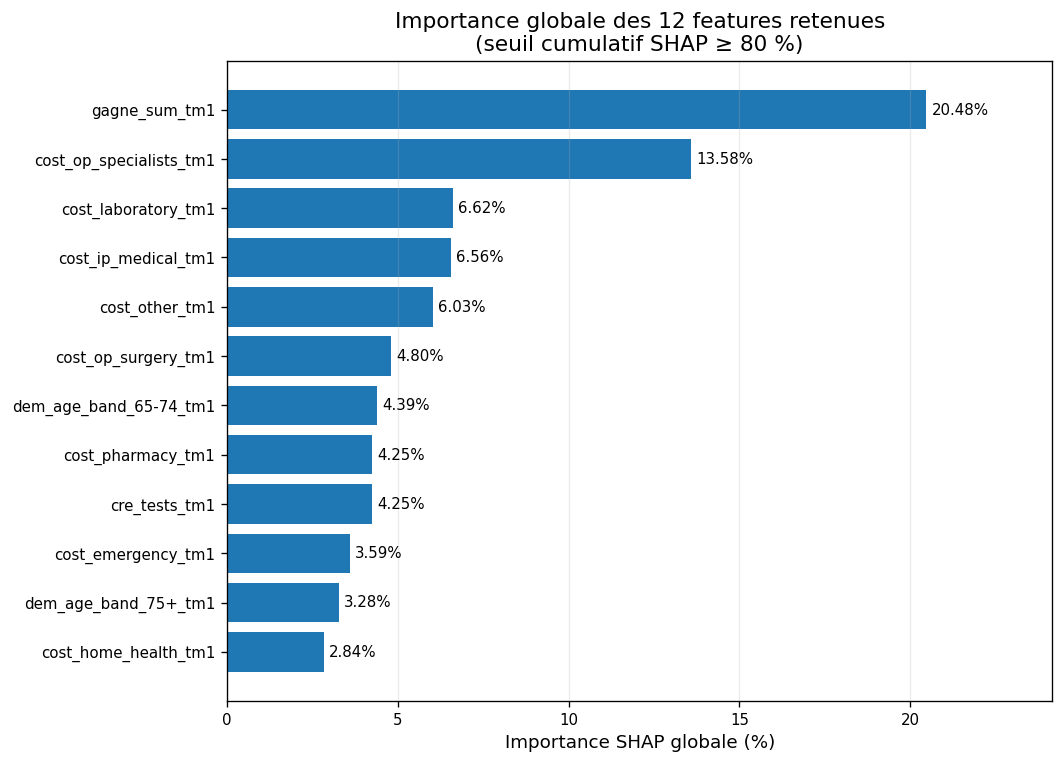


Source : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\03_reference_model_shap\05_global_SHAP_REF_importance.csv

FIGURE 2 — SIGNAUX STATISTIQUES
[OK] Figure_2_signaux_statistiques.png
[OK] Figure_2_signaux_statistiques.pdf


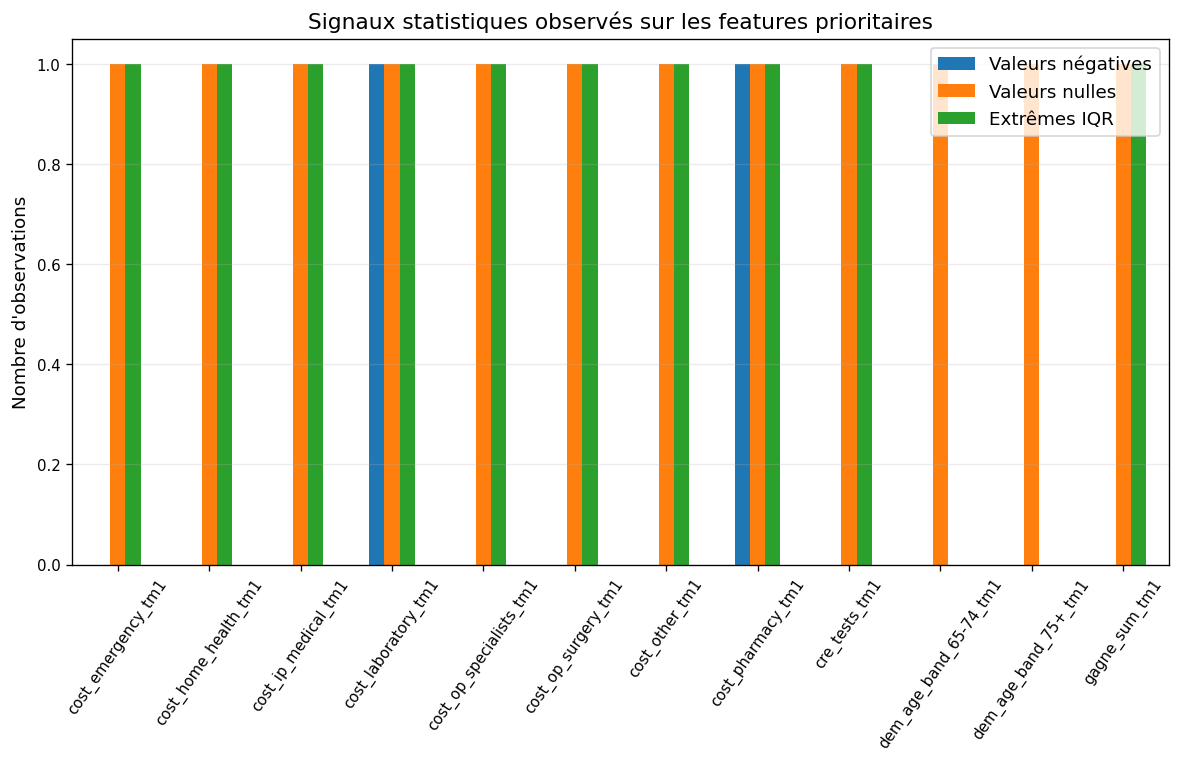


Source : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\09_statistical_knowledge\02_statistical_observations.csv

FIGURE 3 — ENTONNOIR DOCUMENTAIRE
[OK] Figure_3_entonnoir_documentaire.png
[OK] Figure_3_entonnoir_documentaire.pdf


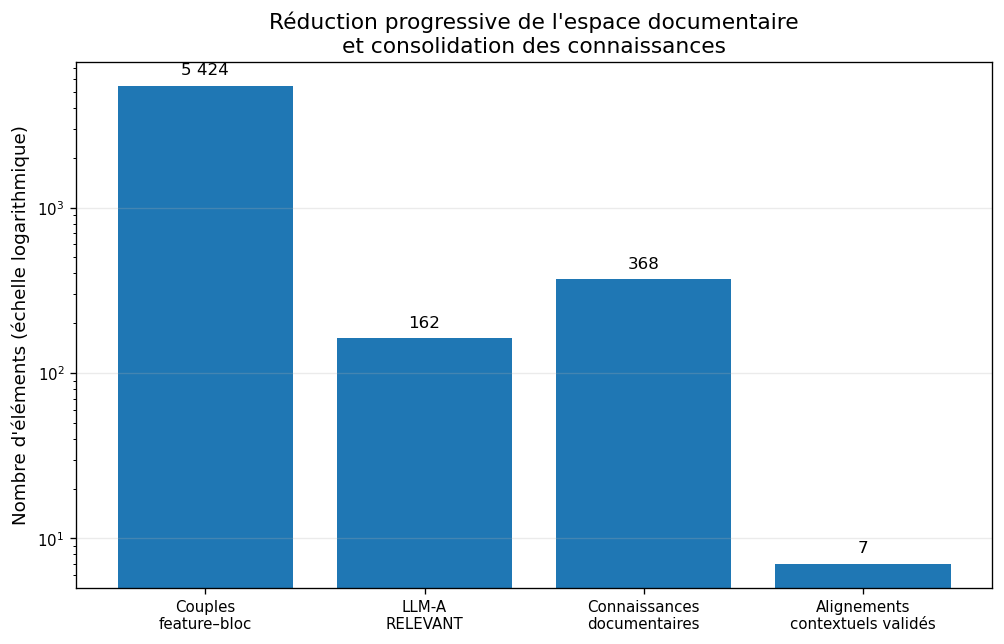


FIGURE 4 — DIAGNOSTIC FINAL
[OK] Figure_4_diagnostic_108_NOT_SUPPORTED.png
[OK] Figure_4_diagnostic_108_NOT_SUPPORTED.pdf


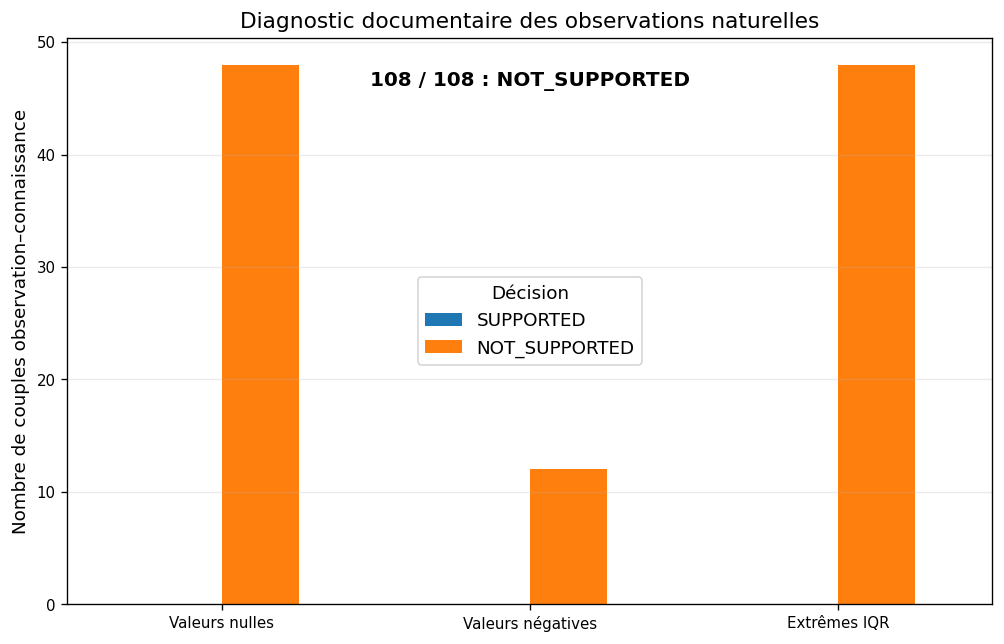


FIGURE 5 — PARCOURS DECISIONNEL
[OK] Figure_5_abstention_responsable.png
[OK] Figure_5_abstention_responsable.pdf


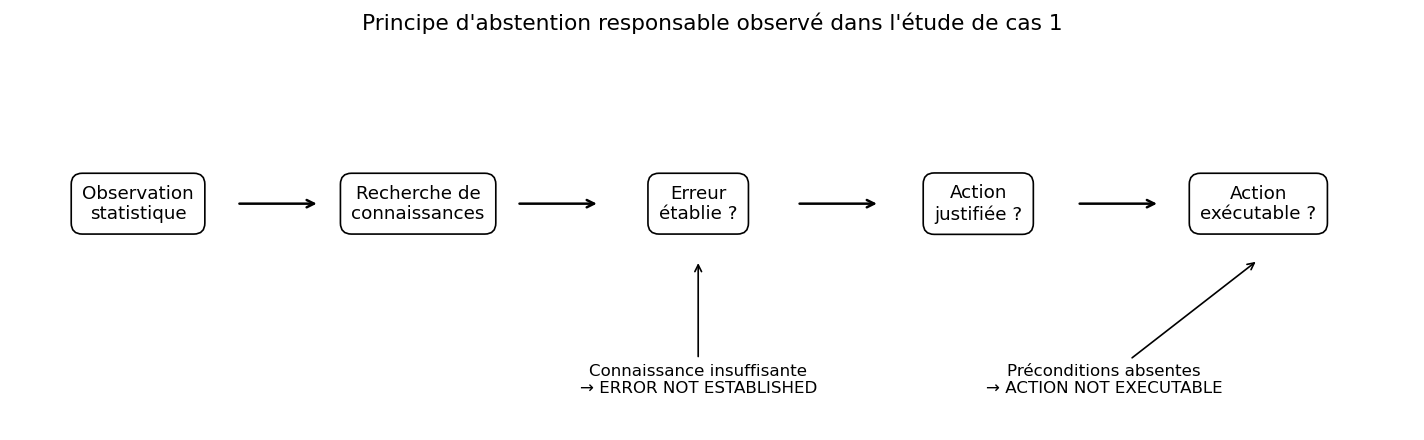


FIGURES TERMINEES

Dossier de sortie :
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\article_figures_case_study_1

Figures principales recommandées pour l'article :

Figure 1 : Importance SHAP des 12 features
Figure 2 : Signaux statistiques observés
Figure 3 : Entonnoir documentaire
Figure 4 : Résultat du diagnostic naturel (108/108 NOT_SUPPORTED)

Figure 5 :
Schéma de synthèse de l'abstention responsable.
Il peut être placé en fin de l'étude de cas ou dans la discussion.

Formats :
- PNG : 300 dpi
- PDF : vectoriel, préférable pour publication



In [1]:
# =====================================================================
# DEMARCHE_ENCAD3 — ETUDE DE CAS 1
# FIGURES POUR LA SECTION EXPERIMENTALE DE L'ARTICLE
# =====================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ---------------------------------------------------------------------
# 0. CONFIGURATION
# ---------------------------------------------------------------------

ROOT = Path(r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3")

RESULTS = ROOT / "results"
FIG_DIR = RESULTS / "article_figures_case_study_1"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 120
})


def save_figure(fig, name):
    """Sauvegarde PNG 300 dpi + PDF vectoriel."""
    png = FIG_DIR / f"{name}.png"
    pdf = FIG_DIR / f"{name}.pdf"

    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")

    print(f"[OK] {png.name}")
    print(f"[OK] {pdf.name}")


def find_csv(required_columns):
    """
    Recherche récursivement un CSV contenant toutes les colonnes demandées.
    Evite de dépendre du nom exact du fichier.
    """
    required_columns = set(required_columns)

    for f in RESULTS.rglob("*.csv"):
        try:
            df = pd.read_csv(f)
            if required_columns.issubset(df.columns):
                return f, df
        except Exception:
            pass

    return None, None


# =====================================================================
# FIGURE 1 — IMPORTANCE SHAP DES 12 FEATURES
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 1 — SHAP")
print("=" * 80)

shap_file, shap = find_csv([
    "original_feature",
    "importance_percent",
    "cumulative_importance"
])

if shap is not None:

    shap = shap.copy()

    # Si le fichier contient toutes les features, garder celles du scope 80 %
    if "selection_reason" in shap.columns:
        tmp = shap[
            shap["selection_reason"]
            .astype(str)
            .str.contains("80_PERCENT", case=False, na=False)
        ]
        if len(tmp) > 0:
            shap = tmp.copy()

    # Dans tous les cas : 12 features du scope expérimental
    shap = shap.sort_values("importance_percent", ascending=False).head(12)

    # ordre inversé pour barh
    plot_df = shap.sort_values("importance_percent", ascending=True)

    fig, ax = plt.subplots(figsize=(9, 6.5))

    bars = ax.barh(
        plot_df["original_feature"],
        plot_df["importance_percent"]
    )

    ax.set_xlabel("Importance SHAP globale (%)")
    ax.set_ylabel("")
    ax.set_title(
        "Importance globale des 12 features retenues\n"
        "(seuil cumulatif SHAP ≥ 80 %)"
    )

    ax.grid(axis="x", alpha=0.25)

    # valeurs au bout des barres
    for bar, value in zip(bars, plot_df["importance_percent"]):
        ax.text(
            bar.get_width() + 0.15,
            bar.get_y() + bar.get_height()/2,
            f"{value:.2f}%",
            va="center",
            fontsize=9
        )

    ax.set_xlim(
        0,
        max(plot_df["importance_percent"]) * 1.18
    )

    fig.tight_layout()

    save_figure(fig, "Figure_1_SHAP_12_features")
    plt.show()

    print("\nSource :", shap_file)

else:
    print("[NON GENEREE] Fichier SHAP non trouvé.")


# =====================================================================
# FIGURE 2 — SIGNAUX STATISTIQUES DES 12 FEATURES
# Valeurs négatives / zéros / extrêmes IQR
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 2 — SIGNAUX STATISTIQUES")
print("=" * 80)

# On cherche d'abord un fichier contenant les observations statistiques
obs_file, obs = find_csv([
    "feature",
    "observation_type"
])

if obs is not None:

    obs = obs.copy()

    # Uniformisation des catégories
    obs["observation_type"] = (
        obs["observation_type"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    # On essaie de trouver automatiquement une colonne de comptage
    possible_count_cols = [
        "count",
        "n",
        "observation_count",
        "n_observations",
        "value_count"
    ]

    count_col = None
    for c in possible_count_cols:
        if c in obs.columns:
            count_col = c
            break

    if count_col is not None:

        pivot = obs.pivot_table(
            index="feature",
            columns="observation_type",
            values=count_col,
            aggfunc="sum",
            fill_value=0
        )

    else:
        # Si chaque ligne correspond elle-même à une observation/condition
        pivot = pd.crosstab(
            obs["feature"],
            obs["observation_type"]
        )

    # Renommage plus lisible lorsque les catégories existent
    rename_map = {
        "NEGATIVE_VALUES": "Valeurs négatives",
        "ZERO_VALUES": "Valeurs nulles",
        "IQR_EXTREME_OBSERVATIONS": "Extrêmes IQR",
        "IQR_EXTREMES": "Extrêmes IQR"
    }

    pivot = pivot.rename(columns=rename_map)

    wanted = [
        "Valeurs négatives",
        "Valeurs nulles",
        "Extrêmes IQR"
    ]

    available = [c for c in wanted if c in pivot.columns]

    if len(available) > 0:

        fig, ax = plt.subplots(figsize=(10, 6.5))

        pivot[available].plot(
            kind="bar",
            ax=ax
        )

        ax.set_title(
            "Signaux statistiques observés sur les features prioritaires"
        )
        ax.set_xlabel("")
        ax.set_ylabel("Nombre d'observations")
        ax.tick_params(axis="x", rotation=55)
        ax.legend(title="")
        ax.grid(axis="y", alpha=0.25)

        fig.tight_layout()

        save_figure(fig, "Figure_2_signaux_statistiques")
        plt.show()

        print("\nSource :", obs_file)

    else:
        print(
            "[NON GENEREE] Le fichier statistique existe, "
            "mais les catégories attendues n'ont pas été trouvées."
        )

else:
    print("[NON GENEREE] Fichier des observations statistiques non trouvé.")


# =====================================================================
# FIGURE 3 — ENTONNOIR DE CONSTRUCTION DE LA CONNAISSANCE
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 3 — ENTONNOIR DOCUMENTAIRE")
print("=" * 80)

# Valeurs validées par l'expérience.
# Elles représentent des résultats globaux de la chaîne documentaire.
stages = [
    "Couples\nfeature–bloc",
    "LLM-A\nRELEVANT",
    "Connaissances\ndocumentaires",
    "Alignements\ncontextuels validés"
]

values = [
    5424,
    162,
    368,
    7
]

fig, ax = plt.subplots(figsize=(8.5, 5.5))

bars = ax.bar(stages, values)

ax.set_yscale("log")

ax.set_ylabel("Nombre d'éléments (échelle logarithmique)")
ax.set_title(
    "Réduction progressive de l'espace documentaire\n"
    "et consolidation des connaissances"
)

ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value * 1.12,
        f"{value:,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=10
    )

fig.tight_layout()

save_figure(fig, "Figure_3_entonnoir_documentaire")
plt.show()


# =====================================================================
# FIGURE 4 — RESULTAT FINAL DU DIAGNOSTIC NATUREL
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 4 — DIAGNOSTIC FINAL")
print("=" * 80)

diagnostic_file, diag = find_csv([
    "decision"
])

# On préfère exploiter le fichier réel s'il existe.
# Sinon, les résultats expérimentaux validés sont :
# IQR = 48 NOT_SUPPORTED
# NEGATIVE = 12 NOT_SUPPORTED
# ZERO = 48 NOT_SUPPORTED

if diag is not None:

    d = diag.copy()

    # chercher automatiquement une colonne décrivant le type d'observation
    type_candidates = [
        "observation_type",
        "statistical_observation_type",
        "problem_type",
        "signal_type"
    ]

    type_col = None
    for c in type_candidates:
        if c in d.columns:
            type_col = c
            break

    if type_col is not None:

        d["decision"] = d["decision"].astype(str).str.upper()
        d[type_col] = d[type_col].astype(str).str.upper()

        table = pd.crosstab(
            d[type_col],
            d["decision"]
        )

    else:
        table = None

else:
    table = None


# Résultats validés de l'expérience si la structure du CSV
# ne permet pas une extraction automatique.
if table is None:

    result = pd.DataFrame({
        "Type": [
            "Valeurs nulles",
            "Valeurs négatives",
            "Extrêmes IQR"
        ],
        "SUPPORTED": [0, 0, 0],
        "NOT_SUPPORTED": [48, 12, 48]
    }).set_index("Type")

else:

    result = table.copy()

    rename_idx = {
        "ZERO_VALUES": "Valeurs nulles",
        "NEGATIVE_VALUES": "Valeurs négatives",
        "IQR_EXTREME_OBSERVATIONS": "Extrêmes IQR",
        "IQR_EXTREMES": "Extrêmes IQR"
    }

    result = result.rename(index=rename_idx)

    for c in ["SUPPORTED", "NOT_SUPPORTED"]:
        if c not in result.columns:
            result[c] = 0

    result = result[["SUPPORTED", "NOT_SUPPORTED"]]


fig, ax = plt.subplots(figsize=(8.5, 5.5))

result.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Diagnostic documentaire des observations naturelles"
)
ax.set_xlabel("")
ax.set_ylabel("Nombre de couples observation–connaissance")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Décision")
ax.grid(axis="y", alpha=0.25)

# Annotation du résultat principal
ax.text(
    0.5,
    0.94,
    "108 / 108 : NOT_SUPPORTED",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=12,
    fontweight="bold"
)

fig.tight_layout()

save_figure(fig, "Figure_4_diagnostic_108_NOT_SUPPORTED")
plt.show()


# =====================================================================
# FIGURE 5 — SYNTHESE DU RESULTAT SCIENTIFIQUE
# Schéma simple destiné à l'article
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 5 — PARCOURS DECISIONNEL")
print("=" * 80)

fig, ax = plt.subplots(figsize=(12, 3.8))

ax.axis("off")

boxes = [
    (0.02, "Observation\nstatistique"),
    (0.22, "Recherche de\nconnaissances"),
    (0.42, "Erreur\nétablie ?"),
    (0.62, "Action\njustifiée ?"),
    (0.82, "Action\nexécutable ?")
]

for x, label in boxes:

    ax.text(
        x + 0.07,
        0.60,
        label,
        ha="center",
        va="center",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="black"
        )
    )

# flèches
for i in range(len(boxes)-1):

    x1 = boxes[i][0] + 0.14
    x2 = boxes[i+1][0]

    ax.annotate(
        "",
        xy=(x2, 0.60),
        xytext=(x1, 0.60),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.5
        )
    )

# branche d'abstention
ax.annotate(
    "Connaissance insuffisante\n→ ERROR NOT ESTABLISHED",
    xy=(0.49, 0.45),
    xytext=(0.49, 0.13),
    ha="center",
    va="center",
    arrowprops=dict(arrowstyle="->"),
    fontsize=10
)

ax.annotate(
    "Préconditions absentes\n→ ACTION NOT EXECUTABLE",
    xy=(0.89, 0.45),
    xytext=(0.78, 0.13),
    ha="center",
    va="center",
    arrowprops=dict(arrowstyle="->"),
    fontsize=10
)

ax.set_title(
    "Principe d'abstention responsable observé dans l'étude de cas 1",
    fontsize=13,
    pad=15
)

fig.tight_layout()

save_figure(fig, "Figure_5_abstention_responsable")
plt.show()


# =====================================================================
# RESUME
# =====================================================================

print("\n" + "=" * 80)
print("FIGURES TERMINEES")
print("=" * 80)

print(f"""
Dossier de sortie :
{FIG_DIR}

Figures principales recommandées pour l'article :

Figure 1 : Importance SHAP des 12 features
Figure 2 : Signaux statistiques observés
Figure 3 : Entonnoir documentaire
Figure 4 : Résultat du diagnostic naturel (108/108 NOT_SUPPORTED)

Figure 5 :
Schéma de synthèse de l'abstention responsable.
Il peut être placé en fin de l'étude de cas ou dans la discussion.

Formats :
- PNG : 300 dpi
- PDF : vectoriel, préférable pour publication
""")

In [2]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3")
RESULTS = ROOT / "results"

# ============================================================
# 1. FICHIER DES OBSERVATIONS STATISTIQUES
# ============================================================

f_obs = RESULTS / "09_statistical_knowledge" / "02_statistical_observations.csv"

obs = pd.read_csv(f_obs)

print("=" * 80)
print("OBSERVATIONS STATISTIQUES")
print("=" * 80)

print("\nShape :", obs.shape)

print("\nColonnes :")
print(obs.columns.tolist())

print("\nContenu complet :")
print(obs.to_string(index=False))


# ============================================================
# 2. FICHIERS DE LA BASE DE CONNAISSANCES
# ============================================================

kb_dir = RESULTS / "11_consolidated_knowledge_base"

print("\n\n" + "=" * 80)
print("FICHIERS KB")
print("=" * 80)

if kb_dir.exists():
    for f in sorted(kb_dir.glob("*.csv")):
        try:
            df = pd.read_csv(f)

            print("\n------------------------------------------------------------")
            print("FICHIER :", f.name)
            print("Shape   :", df.shape)
            print("Colonnes:")
            print(df.columns.tolist())

            print("\nPremières lignes :")
            print(df.head(5).to_string(index=False))

        except Exception as e:
            print(f"\nErreur lecture {f.name}: {e}")
else:
    print("Dossier non trouvé :", kb_dir)

OBSERVATIONS STATISTIQUES

Shape : (24, 13)

Colonnes :
['statistical_observation_id', 'feature', 'source_type', 'observation_type', 'description', 'observed_value', 'n_affected', 'n_reference', 'support', 'support_percent', 'is_error', 'error_status', 'proposes_correction']

Contenu complet :
statistical_observation_id                 feature source_type         observation_type                                                                        description  observed_value  n_affected  n_reference  support  support_percent  is_error    error_status  proposes_correction
             STAT_OBS_0001           gagne_sum_tm1 STATISTICAL              ZERO_VALUES                                         21328 zero values observed in Dataset_REF.             0.0       21328        48784 0.437193        43.719252     False NOT_ESTABLISHED                False
             STAT_OBS_0002           gagne_sum_tm1 STATISTICAL IQR_EXTREME_OBSERVATIONS       2557 observations fall outside the descri


FIGURE 2 CORRIGEE — SIGNAUX STATISTIQUES
[OK] C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\article_figures_case_study_1\Figure_2_signaux_statistiques_CORRIGEE.png
[OK] C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\article_figures_case_study_1\Figure_2_signaux_statistiques_CORRIGEE.pdf


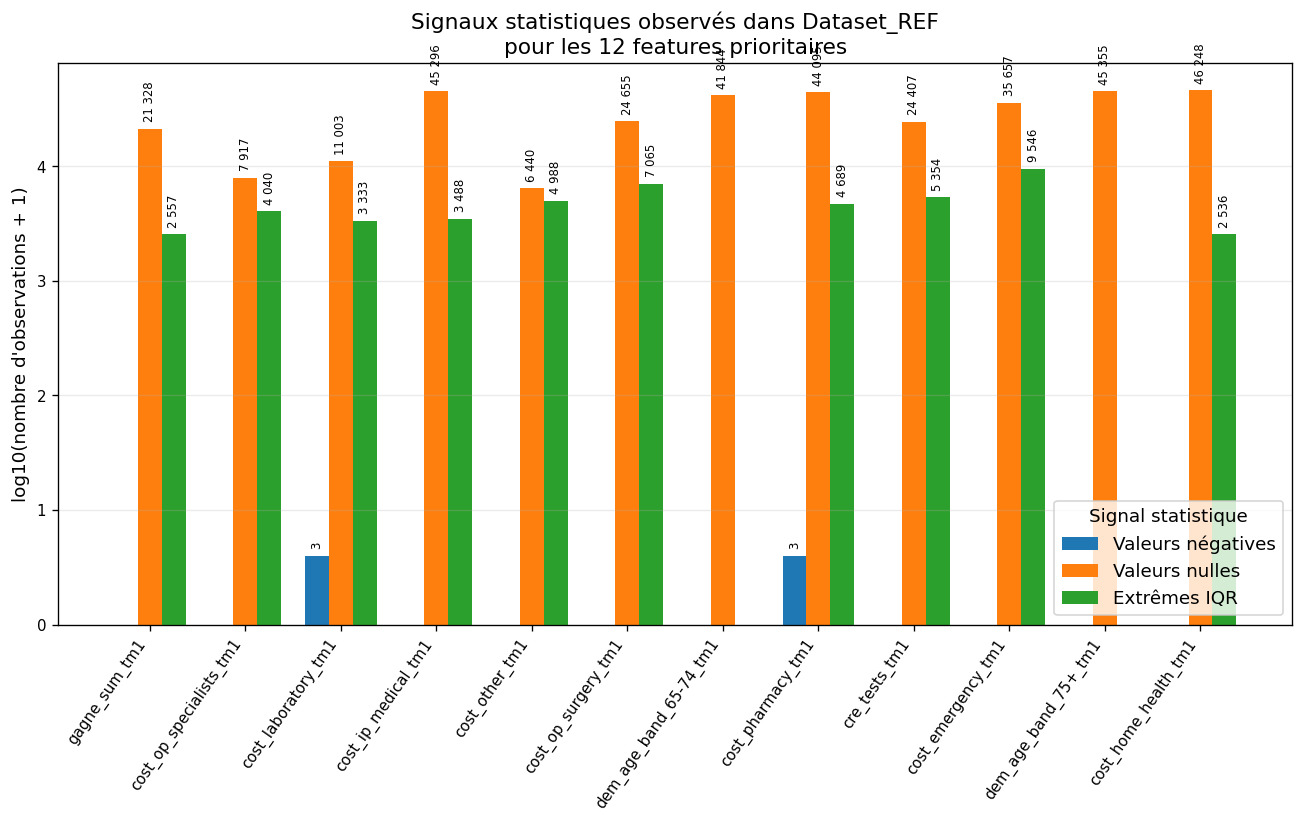


Valeurs utilisées :
observation_type         Valeurs négatives  Valeurs nulles  Extrêmes IQR
feature                                                                 
gagne_sum_tm1                            0           21328          2557
cost_op_specialists_tm1                  0            7917          4040
cost_laboratory_tm1                      3           11003          3333
cost_ip_medical_tm1                      0           45296          3488
cost_other_tm1                           0            6440          4988
cost_op_surgery_tm1                      0           24655          7065
dem_age_band_65-74_tm1                   0           41844             0
cost_pharmacy_tm1                        3           44095          4689
cre_tests_tm1                            0           24407          5354
cost_emergency_tm1                       0           35657          9546
dem_age_band_75+_tm1                     0           45355             0
cost_home_health_tm1          

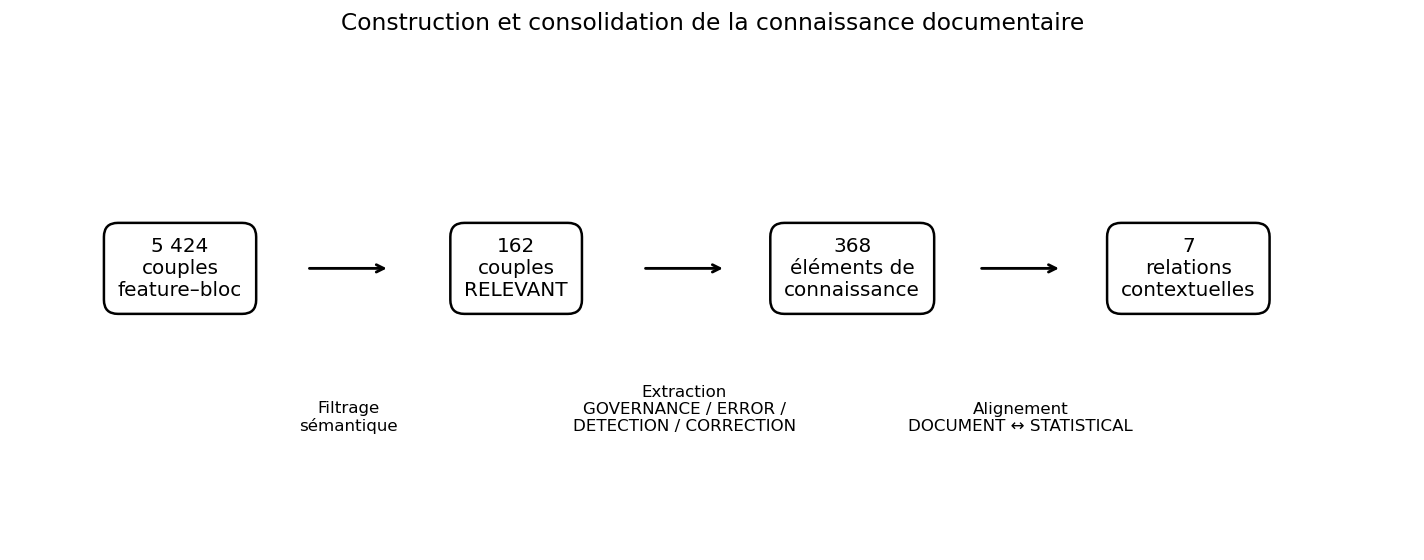


FIGURE 6 — COUVERTURE DOCUMENTAIRE PAR FEATURE
[OK] C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\article_figures_case_study_1\Figure_6_couverture_documentaire_par_feature.png
[OK] C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\results\article_figures_case_study_1\Figure_6_couverture_documentaire_par_feature.pdf


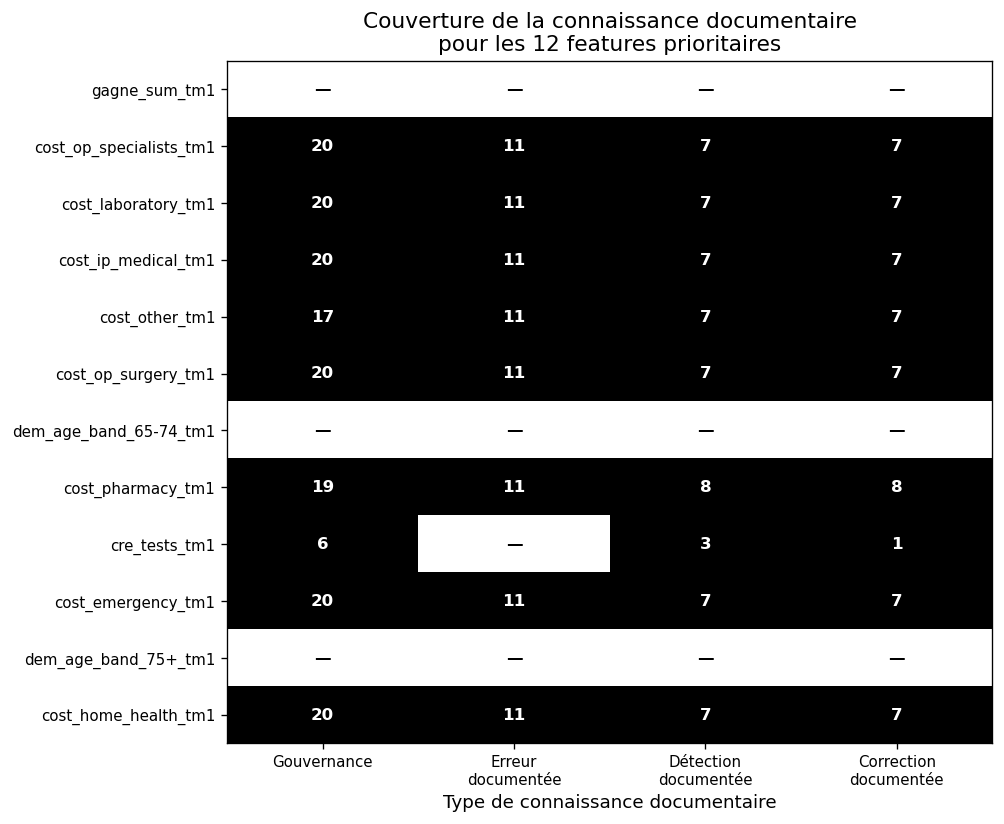


COUVERTURE DOCUMENTAIRE UTILISEE POUR LA FIGURE 6
knowledge_type           GOVERNANCE  ERROR  DETECTION  CORRECTION
feature                                                          
gagne_sum_tm1                     0      0          0           0
cost_op_specialists_tm1          20     11          7           7
cost_laboratory_tm1              20     11          7           7
cost_ip_medical_tm1              20     11          7           7
cost_other_tm1                   17     11          7           7
cost_op_surgery_tm1              20     11          7           7
dem_age_band_65-74_tm1            0      0          0           0
cost_pharmacy_tm1                19     11          8           8
cre_tests_tm1                     6      0          3           1
cost_emergency_tm1               20     11          7           7
dem_age_band_75+_tm1              0      0          0           0
cost_home_health_tm1             20     11          7           7

VERIFICATIONS

Nombre to

In [3]:
# =====================================================================
# DEMARCHE_ENCAD3 — ETUDE DE CAS 1
# FIGURES DEFINITIVES : 2, 3 ET 6
# =====================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

RESULTS = ROOT / "results"
FIG_DIR = RESULTS / "article_figures_case_study_1"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 120
})


def save_figure(fig, name):
    png = FIG_DIR / f"{name}.png"
    pdf = FIG_DIR / f"{name}.pdf"

    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")

    print(f"[OK] {png}")
    print(f"[OK] {pdf}")


# =====================================================================
# FIGURE 2 CORRIGEE
# Nombre REEL d'observations affectées par feature
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 2 CORRIGEE — SIGNAUX STATISTIQUES")
print("=" * 80)

obs_file = (
    RESULTS
    / "09_statistical_knowledge"
    / "02_statistical_observations.csv"
)

obs = pd.read_csv(obs_file)

# On utilise maintenant n_affected et NON le nombre de lignes
pivot = obs.pivot_table(
    index="feature",
    columns="observation_type",
    values="n_affected",
    aggfunc="sum",
    fill_value=0
)

# Garantir l'existence des 3 catégories
types = [
    "NEGATIVE_VALUES",
    "ZERO_VALUES",
    "IQR_EXTREME_OBSERVATIONS"
]

for c in types:
    if c not in pivot.columns:
        pivot[c] = 0

pivot = pivot[types]

pivot = pivot.rename(columns={
    "NEGATIVE_VALUES": "Valeurs négatives",
    "ZERO_VALUES": "Valeurs nulles",
    "IQR_EXTREME_OBSERVATIONS": "Extrêmes IQR"
})

# ordre SHAP
shap_file = (
    RESULTS
    / "03_reference_model_shap"
    / "05_global_SHAP_REF_importance.csv"
)

shap = pd.read_csv(shap_file)

shap_order = (
    shap.sort_values("importance_percent", ascending=False)
        .head(12)["original_feature"]
        .tolist()
)

pivot = pivot.reindex(shap_order).fillna(0)

# -------------------------------------------------------------
# Comme les nombres sont très différents (3 vs > 40 000),
# une échelle logarithmique est préférable.
# log1p permet aussi d'afficher les zéros.
# -------------------------------------------------------------

plot_data = np.log10(pivot + 1)

fig, ax = plt.subplots(figsize=(11, 7))

x = np.arange(len(pivot))
width = 0.25

for i, col in enumerate(pivot.columns):

    bars = ax.bar(
        x + (i - 1) * width,
        plot_data[col],
        width,
        label=col
    )

    # afficher les nombres REELS sur les barres
    for bar, real_value in zip(bars, pivot[col]):

        if real_value > 0:

            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.06,
                f"{int(real_value):,}".replace(",", " "),
                ha="center",
                va="bottom",
                rotation=90,
                fontsize=7
            )

ax.set_xticks(x)
ax.set_xticklabels(
    pivot.index,
    rotation=55,
    ha="right"
)

ax.set_ylabel(
    "log10(nombre d'observations + 1)"
)

ax.set_xlabel("")

ax.set_title(
    "Signaux statistiques observés dans Dataset_REF\n"
    "pour les 12 features prioritaires"
)

ax.legend(title="Signal statistique")

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_2_signaux_statistiques_CORRIGEE"
)

plt.show()


print("\nValeurs utilisées :")
print(pivot.to_string())


# =====================================================================
# FIGURE 3 AMELIOREE
# Construction documentaire — ce n'est PLUS présenté comme
# un entonnoir monotone
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 3 AMELIOREE — CONSTRUCTION DES CONNAISSANCES")
print("=" * 80)

fig, ax = plt.subplots(figsize=(12, 4.8))

ax.axis("off")

# étapes
boxes = [
    (0.04, 0.55, "5 424\ncouples\nfeature–bloc"),
    (0.28, 0.55, "162\ncouples\nRELEVANT"),
    (0.52, 0.55, "368\néléments de\nconnaissance"),
    (0.76, 0.55, "7\nrelations\ncontextuelles")
]

for x0, y0, text in boxes:

    ax.text(
        x0 + 0.08,
        y0,
        text,
        ha="center",
        va="center",
        fontsize=12,
        bbox=dict(
            boxstyle="round,pad=0.7",
            facecolor="white",
            edgecolor="black",
            linewidth=1.5
        )
    )

# flèches
for i in range(len(boxes)-1):

    x1 = boxes[i][0] + 0.17
    x2 = boxes[i+1][0] - 0.01

    ax.annotate(
        "",
        xy=(x2, 0.55),
        xytext=(x1, 0.55),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.7
        )
    )

# explications sous les transitions
ax.text(
    0.24,
    0.23,
    "Filtrage\nsémantique",
    ha="center",
    fontsize=10
)

ax.text(
    0.48,
    0.23,
    "Extraction\nGOVERNANCE / ERROR /\nDETECTION / CORRECTION",
    ha="center",
    fontsize=10
)

ax.text(
    0.72,
    0.23,
    "Alignement\nDOCUMENT ↔ STATISTICAL",
    ha="center",
    fontsize=10
)

ax.set_title(
    "Construction et consolidation de la connaissance documentaire",
    fontsize=14
)

fig.tight_layout()

save_figure(
    fig,
    "Figure_3_construction_connaissance_AMELIOREE"
)

plt.show()


# =====================================================================
# FIGURE 6
# COUVERTURE DOCUMENTAIRE PAR FEATURE
#
# IMPORTANT :
# Cette figure décrit ce qui EXISTE réellement dans la KB.
# Elle ne prétend PAS encore que les actions sont exécutables.
# =====================================================================

print("\n" + "=" * 80)
print("FIGURE 6 — COUVERTURE DOCUMENTAIRE PAR FEATURE")
print("=" * 80)

nodes_file = (
    RESULTS
    / "11_consolidated_knowledge_base"
    / "01_knowledge_base_nodes.csv"
)

nodes = pd.read_csv(nodes_file)

doc = nodes[
    nodes["source_type"].astype(str).str.upper() == "DOCUMENT"
].copy()

# Types documentaires que nous voulons représenter
knowledge_types = [
    "GOVERNANCE",
    "ERROR",
    "DETECTION",
    "CORRECTION"
]

coverage = (
    doc.groupby(
        ["feature", "knowledge_type"]
    )
    .size()
    .unstack(fill_value=0)
)

for c in knowledge_types:
    if c not in coverage.columns:
        coverage[c] = 0

coverage = coverage[knowledge_types]

# ajouter les features sans document
coverage = coverage.reindex(
    shap_order,
    fill_value=0
)

# matrice binaire présence / absence
binary = (coverage > 0).astype(int)

fig, ax = plt.subplots(figsize=(8.5, 7))

im = ax.imshow(
    binary.values,
    aspect="auto",
    cmap="Greys",
    vmin=0,
    vmax=1
)

ax.set_xticks(
    np.arange(len(knowledge_types))
)

ax.set_xticklabels(
    [
        "Gouvernance",
        "Erreur\ndocumentée",
        "Détection\ndocumentée",
        "Correction\ndocumentée"
    ]
)

ax.set_yticks(
    np.arange(len(binary))
)

ax.set_yticklabels(
    binary.index
)

# inscrire le nombre réel de nœuds dans chaque cellule
for i in range(len(coverage)):
    for j in range(len(knowledge_types)):

        n = int(
            coverage.iloc[i, j]
        )

        if n > 0:
            txt = str(n)
            color = "white"
        else:
            txt = "—"
            color = "black"

        ax.text(
            j,
            i,
            txt,
            ha="center",
            va="center",
            color=color,
            fontsize=10,
            fontweight="bold"
        )

ax.set_title(
    "Couverture de la connaissance documentaire\n"
    "pour les 12 features prioritaires"
)

ax.set_xlabel(
    "Type de connaissance documentaire"
)

ax.set_ylabel("")

fig.tight_layout()

save_figure(
    fig,
    "Figure_6_couverture_documentaire_par_feature"
)

plt.show()


# =====================================================================
# TABLEAU DE CONTROLE
# =====================================================================

print("\n" + "=" * 80)
print("COUVERTURE DOCUMENTAIRE UTILISEE POUR LA FIGURE 6")
print("=" * 80)

print(coverage.to_string())


# =====================================================================
# VERIFICATIONS IMPORTANTES
# =====================================================================

print("\n" + "=" * 80)
print("VERIFICATIONS")
print("=" * 80)

print(
    "\nNombre total de nœuds documentaires représentés :",
    int(coverage.values.sum())
)

print(
    "Nombre de features avec au moins une connaissance documentaire :",
    int((coverage.sum(axis=1) > 0).sum()),
    "/ 12"
)

print(
    "Nombre de features sans connaissance documentaire :",
    int((coverage.sum(axis=1) == 0).sum()),
    "/ 12"
)

print("\nFigures enregistrées dans :")
print(FIG_DIR)